In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy

# Data Loading

In [6]:
train_path = 'D:/University/University of Tehran/MSc/Thesis/task/data/trained/'
not_trained_path = 'D:/University/University of Tehran/MSc/Thesis/task/data/not trained/'
AI_path = 'D:/University/University of Tehran/MSc/Thesis/task/data/AI/trained'
AI_2arm_path = 'D:/University/University of Tehran/MSc/Thesis/task/data/AI/2arm/trained'
bl_4arm_path = 'D:/University/University of Tehran/MSc/Thesis/task/data/base-line/4 arm'
bl_2arm_path = 'D:/University/University of Tehran/MSc/Thesis/task/data/base-line/2 arm'
all_trained_4arm_df = []
all_not_trained_4arm_df = []
all_trained_2arm_df = []
all_not_trained_2arm_df = []
all_AI_4arm_df = []
all_AI_2arm_df = []
all_bl_4arm_df = []
all_bl_2arm_df = []
for sub in range(1, 46):
    main_file = '4 arm/subject' + str(sub) + '.csv'
    file_2arm = '2 arm/subject' + str(sub) + '_2arm.csv'
    all_trained_4arm_df.append(pd.read_csv(train_path + main_file))
    all_trained_2arm_df.append(pd.read_csv(train_path + file_2arm))
    
for sub in range(1, 46):
    main_file = '4 arm/subject' + str(sub) + '.csv'
    file_2arm = '2 arm/subject' + str(sub) + '_2arm.csv'
    all_not_trained_4arm_df.append(pd.read_csv(not_trained_path + main_file))
    all_not_trained_2arm_df.append(pd.read_csv(not_trained_path + file_2arm))


for sub in range(1, 21):
    main_file = '/subject' + str(sub) + '.csv'
    file_2arm = '/subject' + str(sub) + '_2arm.csv'
    all_AI_4arm_df.append(pd.read_csv(AI_path + main_file))
    all_AI_2arm_df.append(pd.read_csv(AI_2arm_path + file_2arm))
    
for sub in range(1, 41):
    main_file = '/subject' + str(sub) + '.csv'
    file_2arm = '/subject' + str(sub) + '_2arm.csv'
    all_bl_4arm_df.append(pd.read_csv(bl_4arm_path + main_file))
    all_bl_2arm_df.append(pd.read_csv(bl_2arm_path + file_2arm))

In [7]:
all_sub_df = all_trained_4arm_df + all_not_trained_4arm_df + all_bl_4arm_df
all_sub_2arm_df = all_trained_2arm_df + all_not_trained_2arm_df + all_bl_2arm_df
g1_len = len(all_trained_4arm_df)
g2_len = len(all_not_trained_4arm_df)
g3_len = len(all_bl_4arm_df)
g1 = 'SoLI '
g2 = 'SoLU'
g3 = 'Solo'

# Performance 

In [8]:
list(all_sub_df[0]['choice'])[45:].count(1)

7

In [9]:
all_sub_df = all_trained_4arm_df + all_not_trained_4arm_df

all_sub_b3_best_perf = []

for idx, sub in enumerate(all_sub_df):
    best_idx = eval(list(sub['card probs'])[46]).index(0.7)
    b3_choices = list(sub['choice'])[45:]
    b3_best_perf =  b3_choices.count(best_idx) 
    all_sub_b3_best_perf.append(b3_best_perf)
    
all_sub_b3_best_perf = np.array(all_sub_b3_best_perf)


# RL Model fitting

In [10]:
all_sub_df = all_trained_4arm_df + all_not_trained_4arm_df
all_sub_2arm_df = all_trained_2arm_df + all_not_trained_2arm_df
g1_len = len(all_trained_4arm_df)
g2_len = len(all_not_trained_4arm_df)
# g3_len = len(all_bl_4arm_df)
g1 = 'SoLI '
g2 = 'SoLU'
# g3 = 'Solo'

## 2arm model

In [11]:
def llik_td(x, *args):
    alpha, beta = x
    actions, rewards = args

    Q = np.zeros(2) * 0.5
    logp_actions = np.zeros(len(actions))

    for t, (a, r) in enumerate(zip(actions, rewards)):
        Q_ = Q * beta
        logp_action = Q_ - scipy.special.logsumexp(Q_)

        logp_actions[t] = logp_action[a]

        Q[a] = Q[a] + alpha * (r - Q[a])

    return -np.sum(logp_actions[1:])

In [12]:
import os
import scipy
all_2arm_alpha = []
all_2arm_epsilon = []
for sub in all_sub_2arm_df:
  frame = sub
  actions = frame['choice'][:105]
  rewards = (frame['outcome'][:105] == 'win') * 1
  true_alpha = 0.2
  true_beta = 20
  x0 = [true_alpha, true_beta]
  result = scipy.optimize.minimize(llik_td, x0, args=(actions, rewards), method="L-BFGS-B" ,bounds=((0.01, 1), (0.01, 50)))
  print(result)
  print("")
  print(f"MLE: alpha = {result.x[0]:.2f}")
  print(f"MLE: epsilon = {result.x[1]:.2f}")
  all_2arm_alpha.append(result.x[0])
  all_2arm_epsilon.append(result.x[1])

  message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
  success: True
   status: 0
      fun: 8.067594936885616
        x: [ 3.787e-01  4.506e+00]
      nit: 15
      jac: [-3.162e-05  0.000e+00]
     nfev: 69
     njev: 23
 hess_inv: <2x2 LbfgsInvHessProduct with dtype=float64>

MLE: alpha = 0.38
MLE: epsilon = 4.51
  message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
  success: True
   status: 0
      fun: 3.300594454486405
        x: [ 9.861e-01  4.886e+01]
      nit: 52
      jac: [ 2.994e-02 -1.025e-04]
     nfev: 210
     njev: 70
 hess_inv: <2x2 LbfgsInvHessProduct with dtype=float64>

MLE: alpha = 0.99
MLE: epsilon = 48.86
  message: CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL
  success: True
   status: 0
      fun: 20.10158995025867
        x: [ 1.000e-02  1.000e-02]
      nit: 3
      jac: [ 2.948e-02  3.220e-02]
     nfev: 21
     njev: 7
 hess_inv: <2x2 LbfgsInvHessProduct with dtype=float64>

MLE: alpha = 0.01
MLE: epsilon = 0.01
  message: CONVERGENCE: NOR

Seperate SoLI and SoLU

In [13]:
soli_2arm_alpha = np.array(all_2arm_alpha[:45])
soli_2arm_beta = np.array(all_2arm_epsilon[:45])
solu_2arm_alpha = np.array(all_2arm_alpha[45:])
solu_2arm_beta = np.array(all_2arm_epsilon[45:])

## Social Models

### Core Value Model

In [14]:
def core_value_Qmean_model(x, *args):
    alpha_ind, beta_ind, alpha, beta, gm1, gm2, gm3 = x
    actions, rewards, ag_choices, chosen_ags = args
    
    Q = np.zeros(4)
    logp_actions = np.zeros(len(actions))
    for t, (a, r, ag_choice, chosen_ag) in enumerate(zip(actions, rewards, ag_choices, chosen_ags)):
        if t == 15 or t == 45:
            Q = np.ones(4) * np.mean(Q)
        if t > 14 and t < 45 and t % 3 == 0:
            obs_impact = np.zeros(4)
            try:
                ag_choice = eval(ag_choice)
            except:
                t = t
            obs_impact[ag_choice[0]] += gm1
            obs_impact[ag_choice[1]] += gm2
            obs_impact[ag_choice[2]] += gm3
            
            Q += obs_impact
            Q_ = Q * beta
            logp_action = Q_ - scipy.special.logsumexp(Q_)
            logp_actions[t] = logp_action[a]
            Q[a] = Q[a] + alpha * (r - Q[a])
        elif t >= 45 and t % 3 == 0:
            gamma = 0
            try:
                ag_choice = eval(ag_choice)
            except:
                t = t
            obs_impact = np.zeros(4)
            if chosen_ag == 'A':
                gamma = gm1
            elif chosen_ag == 'B':
                gamma = gm2
            elif chosen_ag == 'C':
                gamma = gm3
            else:
                gamma = 0
            try:
                obs_impact[ag_choice] += gamma
            except:
                obs_impact = np.zeros(4)
            Q += obs_impact
            Q_ = Q * beta
            logp_action = Q_ - scipy.special.logsumexp(Q_)
            logp_actions[t] = logp_action[a]
            Q[a] = Q[a] + alpha * (r - Q[a])
        elif t < 15:
            Q_ = Q * beta_ind
            logp_action = Q_ - scipy.special.logsumexp(Q_)
            logp_actions[t] = logp_action[a]
            Q[a] = Q[a] + alpha_ind * (r - Q[a])
        else:
            Q_ = Q * beta
            logp_action = Q_ - scipy.special.logsumexp(Q_)
            logp_actions[t] = logp_action[a]
            Q[a] = Q[a] + alpha * (r - Q[a])
            
    return -np.sum(logp_actions[1:])

Core Value Model Fitting

In [15]:
import os
import scipy
all_cv_alpha_ind_Qmean = []
all_cv_epsilon_ind_Qmean = []
all_cv_alpha_Qmean = []
all_cv_gamma_Qmean = []
all_cv_epsilon_Qmean = []
all_cv_neg_ll_Qmean = []


for sub in all_sub_df:

  frame = sub  
  actions = frame['choice'][:105]
  rewards = (frame['outcome'][:105] == 'win') * 1
  ag_choices = frame['agent_choices'][:105]
  chosen_ags = frame['chosen_agent'][:105]
  true_alpha = 0.2
  true_beta = 20
  x0 = [0.2, 20, true_alpha, true_beta, 0.2, 0.2, 0.2]
  result = scipy.optimize.minimize(core_value_Qmean_model, x0, args=(actions, rewards, ag_choices, chosen_ags), method="L-BFGS-B" ,bounds=((0.01, 1), (0.01, 50), (0.01, 1), (0.01, 50), (-1, 1), (-1, 1), (-1, 1)))
  print(result)
  print("")
  print(f"MLE: alpha_ind = {result.x[0]:.2f}")
  print(f"MLE: epsilon_ind = {result.x[1]:.2f}")
  print(f"MLE: alpha = {result.x[2]:.2f}")
  print(f"MLE: epsilon = {result.x[3]:.2f}")
  print(f"MLE: gamma1 = {result.x[4]:.2f}")
  print(f"MLE: gamma2 = {result.x[5]:.2f}")
  print(f"MLE: gamma3 = {result.x[6]:.2f}")
  
  all_cv_alpha_ind_Qmean.append(result.x[0])
  all_cv_epsilon_ind_Qmean.append(result.x[1])
  all_cv_alpha_Qmean.append(result.x[2])
  all_cv_gamma_Qmean.append([result.x[4], result.x[5], result.x[6]])
  all_cv_epsilon_Qmean.append(result.x[3])
  all_cv_neg_ll_Qmean.append(result.fun)

  message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
  success: True
   status: 0
      fun: 103.81965371065098
        x: [ 1.624e-01  6.368e+00  8.386e-01  2.264e+00  1.000e+00
             3.169e-01  3.951e-01]
      nit: 60
      jac: [ 3.880e-04  1.137e-05  3.439e-04 -6.537e-05 -2.085e+01
             5.969e-05 -2.970e-04]
     nfev: 768
     njev: 96
 hess_inv: <7x7 LbfgsInvHessProduct with dtype=float64>

MLE: alpha_ind = 0.16
MLE: epsilon_ind = 6.37
MLE: alpha = 0.84
MLE: epsilon = 2.26
MLE: gamma1 = 1.00
MLE: gamma2 = 0.32
MLE: gamma3 = 0.40
  message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
  success: True
   status: 0
      fun: 50.04653380786827
        x: [ 9.203e-01  5.000e+01  1.006e-01  8.506e+00  6.483e-02
            -1.126e-01  1.818e-01]
      nit: 88
      jac: [ 3.155e-04 -4.420e-03 -8.306e-04 -1.990e-05  8.669e-05
            -2.757e-04 -1.375e-03]
     nfev: 872
     njev: 109
 hess_inv: <7x7 LbfgsInvHessProduct with dtype=float64>

MLE: alpha_ind 

sorting gammas

In [16]:
all_sub_ag_type = []
for idx, sub in enumerate(all_sub_df):
    all_sub_ag_type.append(list(sub['agent types'])[-1])

In [17]:
cv_sorted_gammas = []

for idx, sub in enumerate(all_sub_ag_type): 
    gammas = [0, 0, 0]
    ag_type = eval(sub)
    gammas[0] = all_cv_gamma_Qmean[idx][ag_type.index(0)]
    gammas[1] = all_cv_gamma_Qmean[idx][ag_type.index(1)]
    gammas[2] = all_cv_gamma_Qmean[idx][ag_type.index(2)]
    cv_sorted_gammas.append(gammas.copy())

Seperating SoLI and SoLU

In [18]:
# CV -> Core Value
soli_cv_alpha_ind = np.array(all_cv_alpha_ind_Qmean[:45])
solu_cv_alpha_ind = np.array(all_cv_alpha_ind_Qmean[45:])

soli_cv_beta_ind = np.array(all_cv_epsilon_ind_Qmean[:45])
solu_cv_beta_ind = np.array(all_cv_epsilon_ind_Qmean[45:])

soli_cv_alpha = np.array(all_cv_alpha_Qmean[:45])
solu_cv_alpha = np.array(all_cv_alpha_Qmean[45:])

soli_cv_beta = np.array(all_cv_epsilon_Qmean[:45])
solu_cv_beta = np.array(all_cv_epsilon_Qmean[45:])

soli_cv_gammas = np.array(cv_sorted_gammas[:45])
solu_cv_gammas = np.array(cv_sorted_gammas[45:])

soli_cv_nll = np.array(all_cv_neg_ll_Qmean[:45])
solu_cv_nll = np.array(all_cv_neg_ll_Qmean[45:])

### Temporary Value Model 

In [19]:
def temporary_value_Qmean_model(x, *args):
    alpha_ind, beta_ind, alpha, beta, gm1, gm2, gm3 = x
    actions, rewards, ag_choices, chosen_ags = args
    
    Q = np.zeros(4)
    logp_actions = np.zeros(len(actions))
    for t, (a, r, ag_choice, chosen_ag) in enumerate(zip(actions, rewards, ag_choices, chosen_ags)):
        if t == 15 or t == 45:
            Q = np.ones(4) * np.mean(Q)
            
        if t > 14 and t < 45:
            if t % 3 == 0:
                obs_impact = np.zeros(4)
                try:
                    ag_choice = eval(ag_choice)
                except:
                    t = t
                obs_impact[ag_choice[0]] += gm1
                obs_impact[ag_choice[1]] += gm2
                obs_impact[ag_choice[2]] += gm3
                   
            Q_ = (Q + obs_impact) * beta
            logp_action = Q_ - scipy.special.logsumexp(Q_)
            logp_actions[t] = logp_action[a]
            Q[a] = Q[a] + alpha * (r - Q[a])
        elif t >= 45:
            if t % 3 == 0:
                gamma = 0
                try:
                    ag_choice = eval(ag_choice)
                except:
                    t = t
                obs_impact = np.zeros(4)
                if chosen_ag == 'A':
                    gamma = gm1
                elif chosen_ag == 'B':
                    gamma = gm2
                elif chosen_ag == 'C':
                    gamma = gm3
                else:
                    gamma = 0
                try:
                    obs_impact[ag_choice] += gamma
                except:
                    obs_impact = np.zeros(4)

            Q_ = (Q + obs_impact) * beta
            logp_action = Q_ - scipy.special.logsumexp(Q_)
            logp_actions[t] = logp_action[a]
            Q[a] = Q[a] + alpha * (r - Q[a])
        elif t < 15:
            Q_ = Q * beta_ind
            logp_action = Q_ - scipy.special.logsumexp(Q_)
            logp_actions[t] = logp_action[a]
            Q[a] = Q[a] + alpha_ind * (r - Q[a])
        else: 
            Q_ = Q * beta
            logp_action = Q_ - scipy.special.logsumexp(Q_)
            logp_actions[t] = logp_action[a]
            Q[a] = Q[a] + alpha * (r - Q[a])
        
        
    return -np.sum(logp_actions[1:])

In [20]:
import os
import scipy

all_tv_alpha_ind_Qmean = []
all_tv_beta_ind_Qmean = []
all_tv_alpha_Qmean = []
all_tv_gamma_Qmean = []
all_tv_beta_Qmean = []
all_tv_neg_ll_Qmean = []

for sub in all_sub_df:

  frame = sub  
  actions = frame['choice'][:105]
  rewards = (frame['outcome'][:105] == 'win') * 1
  ag_choices = frame['agent_choices'][:105]
  chosen_ags = frame['chosen_agent'][:105]
  true_alpha = 0.2
  true_beta = 20
  x0 = [0.2, 20, true_alpha, true_beta, 0.2, 0.2, 0.2]
  result = scipy.optimize.minimize(temporary_value_Qmean_model, x0, args=(actions, rewards, ag_choices, chosen_ags), method="L-BFGS-B" ,bounds=((0.01, 1), (0.01, 50), (0.01, 1), (0.01, 50), (-1, 1), (-1, 1), (-1, 1)))
  print(result)
  print("")
  print(f"MLE: alpha_ind = {result.x[0]:.2f}")
  print(f"MLE: epsilon_ind = {result.x[1]:.2f}")
  print(f"MLE: alpha = {result.x[2]:.2f}")
  print(f"MLE: epsilon = {result.x[3]:.2f}")
  print(f"MLE: gamma1 = {result.x[4]:.2f}")
  print(f"MLE: gamma2 = {result.x[5]:.2f}")
  print(f"MLE: gamma3 = {result.x[6]:.2f}")
  
  all_tv_alpha_ind_Qmean.append(result.x[0])
  all_tv_beta_ind_Qmean.append(result.x[1])
  all_tv_alpha_Qmean.append(result.x[2])
  all_tv_gamma_Qmean.append([result.x[4], result.x[5], result.x[6]])
  all_tv_beta_Qmean.append(result.x[3])
  all_tv_neg_ll_Qmean.append(result.fun)

  message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
  success: True
   status: 0
      fun: 111.73445592505615
        x: [ 1.625e-01  6.367e+00  5.000e-02  5.147e+00  2.199e-01
             1.475e-01  6.009e-02]
      nit: 79
      jac: [ 1.137e-05 -8.527e-06  4.533e-04  8.527e-06  1.791e-04
             1.791e-04 -5.684e-04]
     nfev: 792
     njev: 99
 hess_inv: <7x7 LbfgsInvHessProduct with dtype=float64>

MLE: alpha_ind = 0.16
MLE: epsilon_ind = 6.37
MLE: alpha = 0.05
MLE: epsilon = 5.15
MLE: gamma1 = 0.22
MLE: gamma2 = 0.15
MLE: gamma3 = 0.06
  message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
  success: True
   status: 0
      fun: 43.07186018068387
        x: [ 9.189e-01  5.000e+01  1.764e-01  8.192e+00  1.501e-01
            -1.444e-03  3.171e-01]
      nit: 53
      jac: [ 1.705e-05 -3.794e-03 -1.953e-03 -6.395e-06 -7.958e-04
            -1.151e-04  1.474e-03]
     nfev: 480
     njev: 60
 hess_inv: <7x7 LbfgsInvHessProduct with dtype=float64>

MLE: alpha_ind =

Sorting gammas

In [21]:
all_sub_ag_type = []
for idx, sub in enumerate(all_sub_df):
    all_sub_ag_type.append(list(sub['agent types'])[-1])

In [22]:
tv_sorted_gammas = []

for idx, sub in enumerate(all_sub_ag_type): 
    gammas = [0, 0, 0]
    ag_type = eval(sub)
    gammas[0] = all_tv_gamma_Qmean[idx][ag_type.index(0)]
    gammas[1] = all_tv_gamma_Qmean[idx][ag_type.index(1)]
    gammas[2] = all_tv_gamma_Qmean[idx][ag_type.index(2)]
    tv_sorted_gammas.append(gammas.copy())

Seperating SoLI and SoLU

In [23]:
# TV -> Temporary Value

soli_tv_alpha_ind = np.array(all_tv_alpha_ind_Qmean[:45])
solu_tv_alpha_ind = np.array(all_tv_alpha_ind_Qmean[45:])

soli_tv_beta_ind = np.array(all_tv_beta_ind_Qmean[:45])
solu_tv_beta_ind = np.array(all_tv_beta_ind_Qmean[45:])

soli_tv_alpha = np.array(all_tv_alpha_Qmean[:45])
solu_tv_alpha = np.array(all_tv_alpha_Qmean[45:])

soli_tv_beta = np.array(all_tv_beta_Qmean[:45])
solu_tv_beta = np.array(all_tv_beta_Qmean[45:])

soli_tv_gammas = np.array(tv_sorted_gammas[:45])
solu_tv_gammas = np.array(tv_sorted_gammas[45:])

soli_tv_nll = np.array(all_tv_neg_ll_Qmean[:45])
solu_tv_nll = np.array(all_tv_neg_ll_Qmean[45:])

# Sorting by Performance

In [24]:
def sort_with_indices(a):
    idx = np.argsort(a)
    return idx, a[idx]

In [25]:
soli_sorted_perf_idc, soli_sorted_perf = sort_with_indices(all_sub_b3_best_perf[:45])
solu_sorted_perf_idc, solu_sorted_perf = sort_with_indices(all_sub_b3_best_perf[45:])

SoLI Sorting

In [26]:
sorted_soli_2arm_alpha = soli_2arm_alpha[soli_sorted_perf_idc]
sorted_soli_2arm_beta = soli_2arm_beta[soli_sorted_perf_idc]
sorted_soli_cv_alpha_ind = soli_cv_alpha_ind[soli_sorted_perf_idc]
sorted_soli_cv_beta_ind = soli_cv_beta_ind[soli_sorted_perf_idc]
sorted_soli_cv_alpha = soli_cv_alpha[soli_sorted_perf_idc]
sorted_soli_cv_beta = soli_cv_beta[soli_sorted_perf_idc]
sorted_soli_cv_gammas = soli_cv_gammas[soli_sorted_perf_idc]
sorted_soli_cv_nll = soli_cv_nll[soli_sorted_perf_idc]
sorted_soli_tv_alpha_ind = soli_tv_alpha_ind[soli_sorted_perf_idc]
sorted_soli_tv_beta_ind = soli_tv_beta_ind[soli_sorted_perf_idc]
sorted_soli_tv_alpha = soli_tv_alpha[soli_sorted_perf_idc]
sorted_soli_tv_beta = soli_tv_beta[soli_sorted_perf_idc]
sorted_soli_tv_gammas = soli_tv_gammas[soli_sorted_perf_idc]
sorted_soli_tv_nll = soli_tv_nll[soli_sorted_perf_idc]

SoLU Sorting

In [27]:
sorted_solu_2arm_alpha = solu_2arm_alpha[solu_sorted_perf_idc]
sorted_solu_2arm_beta = solu_2arm_beta[solu_sorted_perf_idc]
sorted_solu_cv_alpha_ind = solu_cv_alpha_ind[solu_sorted_perf_idc]
sorted_solu_cv_beta_ind = solu_cv_beta_ind[solu_sorted_perf_idc]
sorted_solu_cv_alpha = solu_cv_alpha[solu_sorted_perf_idc]
sorted_solu_cv_beta = solu_cv_beta[solu_sorted_perf_idc]
sorted_solu_cv_gammas = solu_cv_gammas[solu_sorted_perf_idc]
sorted_solu_cv_nll = solu_cv_nll[solu_sorted_perf_idc]
sorted_solu_tv_alpha_ind = solu_tv_alpha_ind[solu_sorted_perf_idc]
sorted_solu_tv_beta_ind = solu_tv_beta_ind[solu_sorted_perf_idc]
sorted_solu_tv_alpha = solu_tv_alpha[solu_sorted_perf_idc]
sorted_solu_tv_beta = solu_tv_beta[solu_sorted_perf_idc]
sorted_solu_tv_gammas = solu_tv_gammas[solu_sorted_perf_idc]
sorted_solu_tv_nll = solu_tv_nll[solu_sorted_perf_idc]

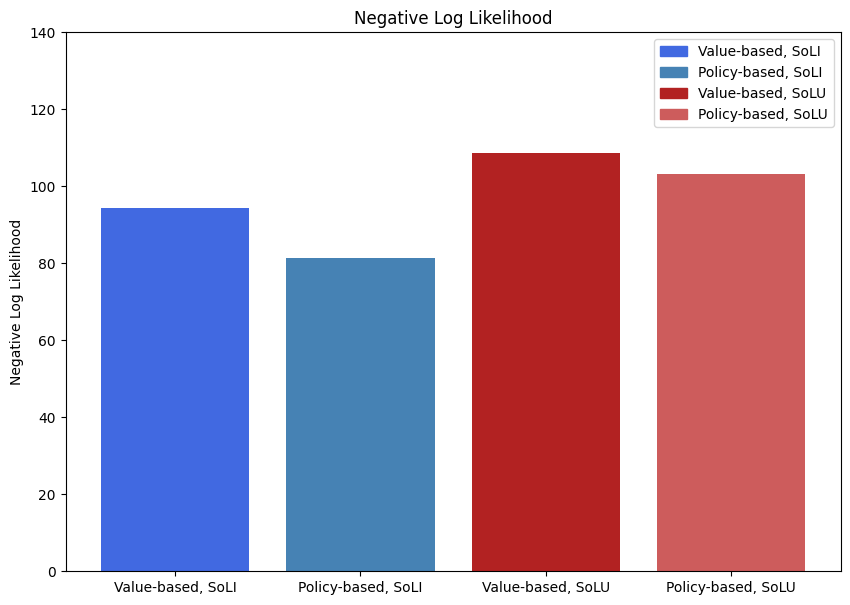

In [28]:
from matplotlib.patches import Patch


x = ['Value-based, SoLI', 'Policy-based, SoLI', 'Value-based, SoLU', 'Policy-based, SoLU']

mean_values = [np.mean(sorted_soli_cv_nll), np.mean(sorted_soli_tv_nll), np.mean(sorted_solu_cv_nll), np.mean(sorted_solu_tv_nll)]
clr = ['royalblue', 'steelblue', 'firebrick', 'indianred']
labels = ['Value-based, SoLI', 'Policy-based, SoLI', 'Value-based, SoLU', 'Policy-based, SoLU']
fig, axs = plt.subplots(1, 1, figsize=(10, 7))

axs.bar(x, mean_values, color=clr)
axs.set_ylim([0, 140])
axs.set_title('Negative Log Likelihood')
axs.set_ylabel('Negative Log Likelihood')
handles = [Patch(color=clr[i], label=labels[i]) for i in range(len(clr))]
axs.legend(handles=handles, loc='best')

alpha and beta corelations

Text(0.5, 1.0, 'Coefficient: 0.0388      P value: 0.8002')

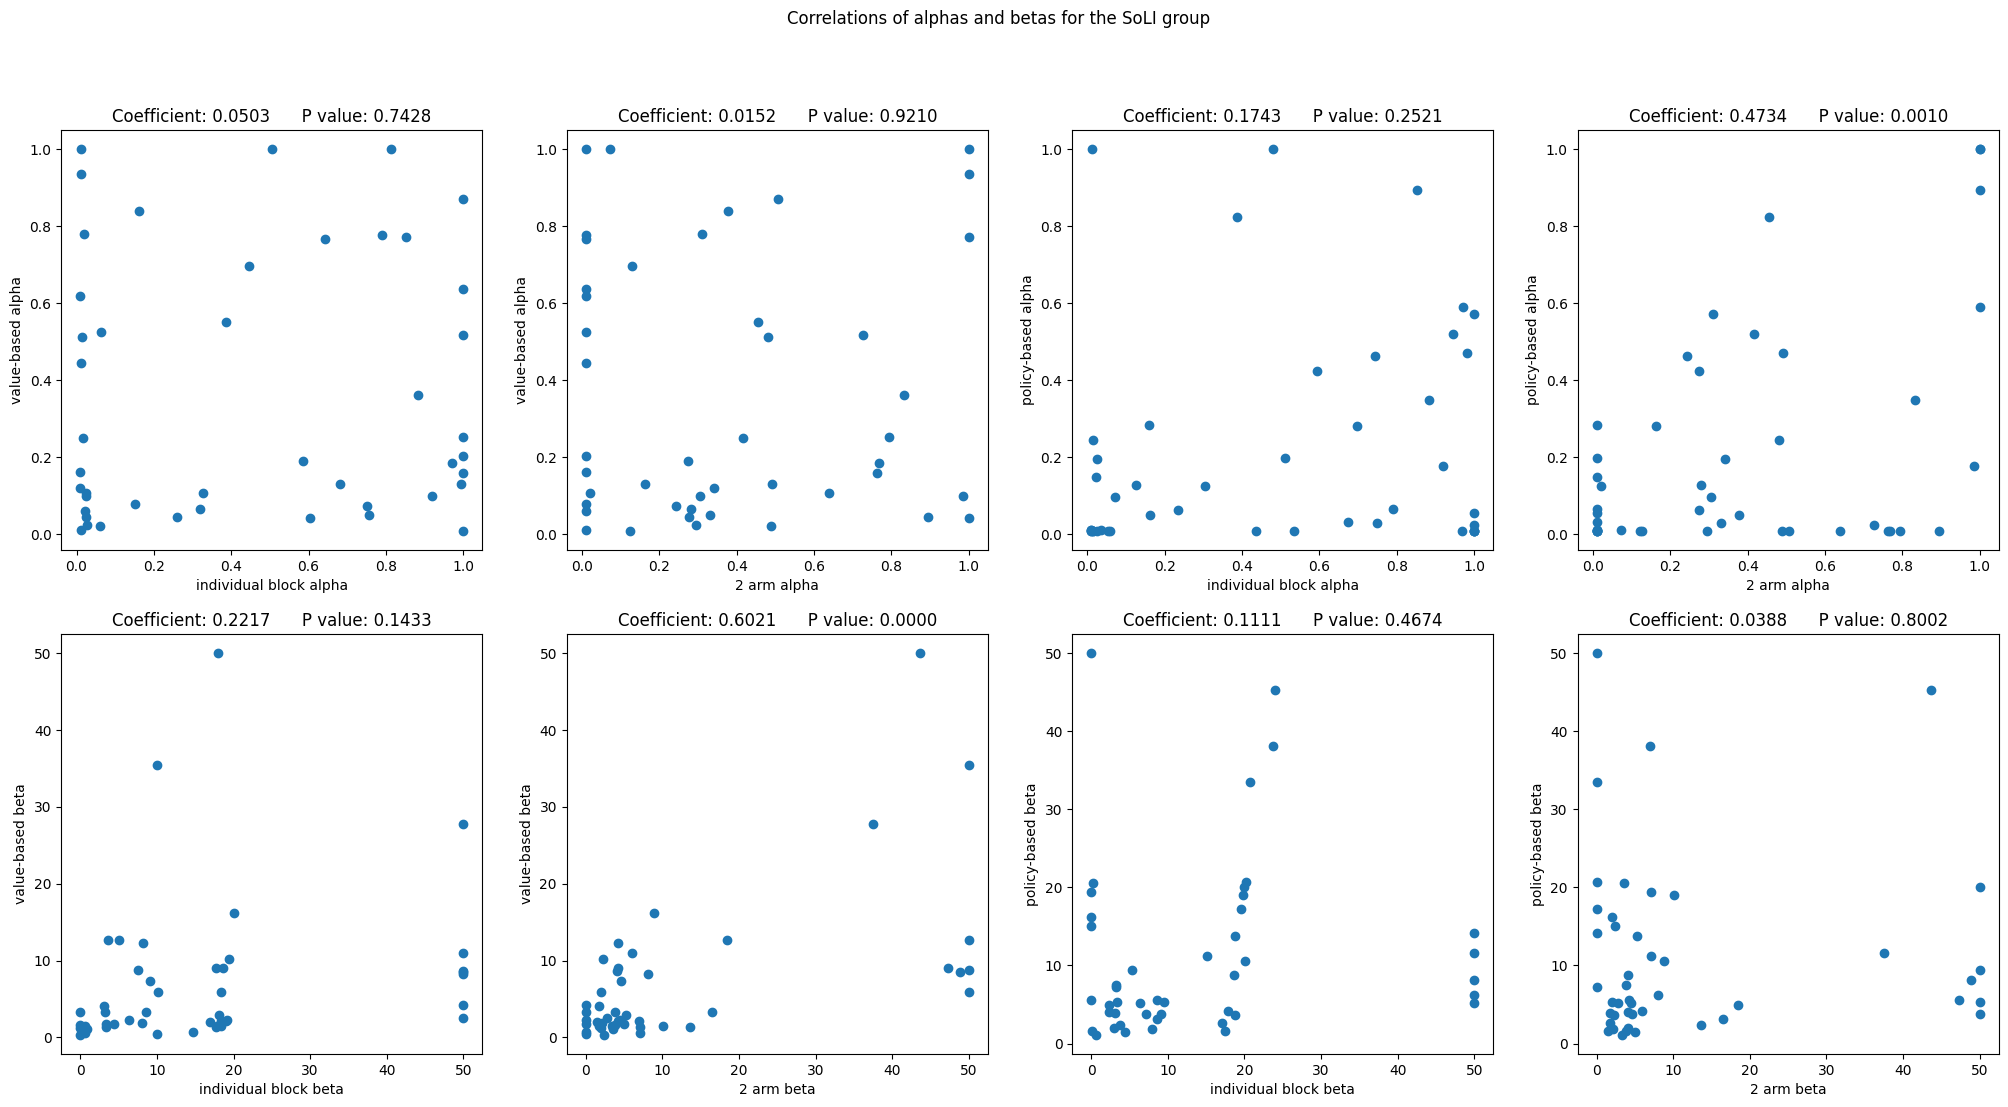

In [29]:
from scipy.stats import pearsonr

fig, axs = plt.subplots(2, 4, figsize=(25, 12))

fig.suptitle('Correlations of alphas and betas for the SoLI group')


r, p = pearsonr(sorted_soli_cv_alpha_ind, sorted_soli_cv_alpha)
axs[0, 0].scatter(sorted_soli_cv_alpha_ind,  sorted_soli_cv_alpha)
axs[0, 0].set_xlabel('individual block alpha')
axs[0, 0].set_ylabel('value-based alpha')
axs[0, 0].set_title('Coefficient: '+ format(r, ".4f") + '      P value: ' + format(p, ".4f"))

r, p = pearsonr(sorted_soli_2arm_alpha, sorted_soli_cv_alpha)
axs[0, 1].scatter(sorted_soli_2arm_alpha, sorted_soli_cv_alpha)
axs[0, 1].set_xlabel('2 arm alpha')
axs[0, 1].set_ylabel('value-based alpha')
axs[0, 1].set_title('Coefficient: '+ format(r, ".4f") + '      P value: ' + format(p, ".4f"))

r, p = pearsonr(sorted_soli_tv_alpha_ind, sorted_soli_tv_alpha)
axs[0, 2].scatter(sorted_soli_tv_alpha_ind,  sorted_soli_tv_alpha)
axs[0, 2].set_xlabel('individual block alpha')
axs[0, 2].set_ylabel('policy-based alpha')
axs[0, 2].set_title('Coefficient: '+ format(r, ".4f") + '      P value: ' + format(p, ".4f"))

r, p = pearsonr(sorted_soli_2arm_alpha, sorted_soli_tv_alpha)
axs[0, 3].scatter(sorted_soli_2arm_alpha, sorted_soli_tv_alpha)
axs[0, 3].set_xlabel('2 arm alpha')
axs[0, 3].set_ylabel('policy-based alpha')
axs[0, 3].set_title('Coefficient: '+ format(r, ".4f") + '      P value: ' + format(p, ".4f"))



r, p = pearsonr(sorted_soli_cv_beta_ind, sorted_soli_cv_beta)
axs[1, 0].scatter(sorted_soli_cv_beta_ind,  sorted_soli_cv_beta)
axs[1, 0].set_xlabel('individual block beta')
axs[1, 0].set_ylabel('value-based beta')
axs[1, 0].set_title('Coefficient: '+ format(r, ".4f") + '      P value: ' + format(p, ".4f"))

r, p = pearsonr(sorted_soli_2arm_beta, sorted_soli_cv_beta)
axs[1, 1].scatter(sorted_soli_2arm_beta, sorted_soli_cv_beta)
axs[1, 1].set_xlabel('2 arm beta')
axs[1, 1].set_ylabel('value-based beta')
axs[1, 1].set_title('Coefficient: '+ format(r, ".4f") + '      P value: ' + format(p, ".4f"))

r, p = pearsonr(sorted_soli_tv_beta_ind, sorted_soli_tv_beta)
axs[1, 2].scatter(sorted_soli_tv_beta_ind,  sorted_soli_tv_beta)
axs[1, 2].set_xlabel('individual block beta')
axs[1, 2].set_ylabel('policy-based beta')
axs[1, 2].set_title('Coefficient: '+ format(r, ".4f") + '      P value: ' + format(p, ".4f"))

r, p = pearsonr(sorted_soli_2arm_beta, sorted_soli_tv_beta)
axs[1, 3].scatter(sorted_soli_2arm_beta, sorted_soli_tv_beta)
axs[1, 3].set_xlabel('2 arm beta')
axs[1, 3].set_ylabel('policy-based beta')
axs[1, 3].set_title('Coefficient: '+ format(r, ".4f") + '      P value: ' + format(p, ".4f"))

Visualizing models parameters

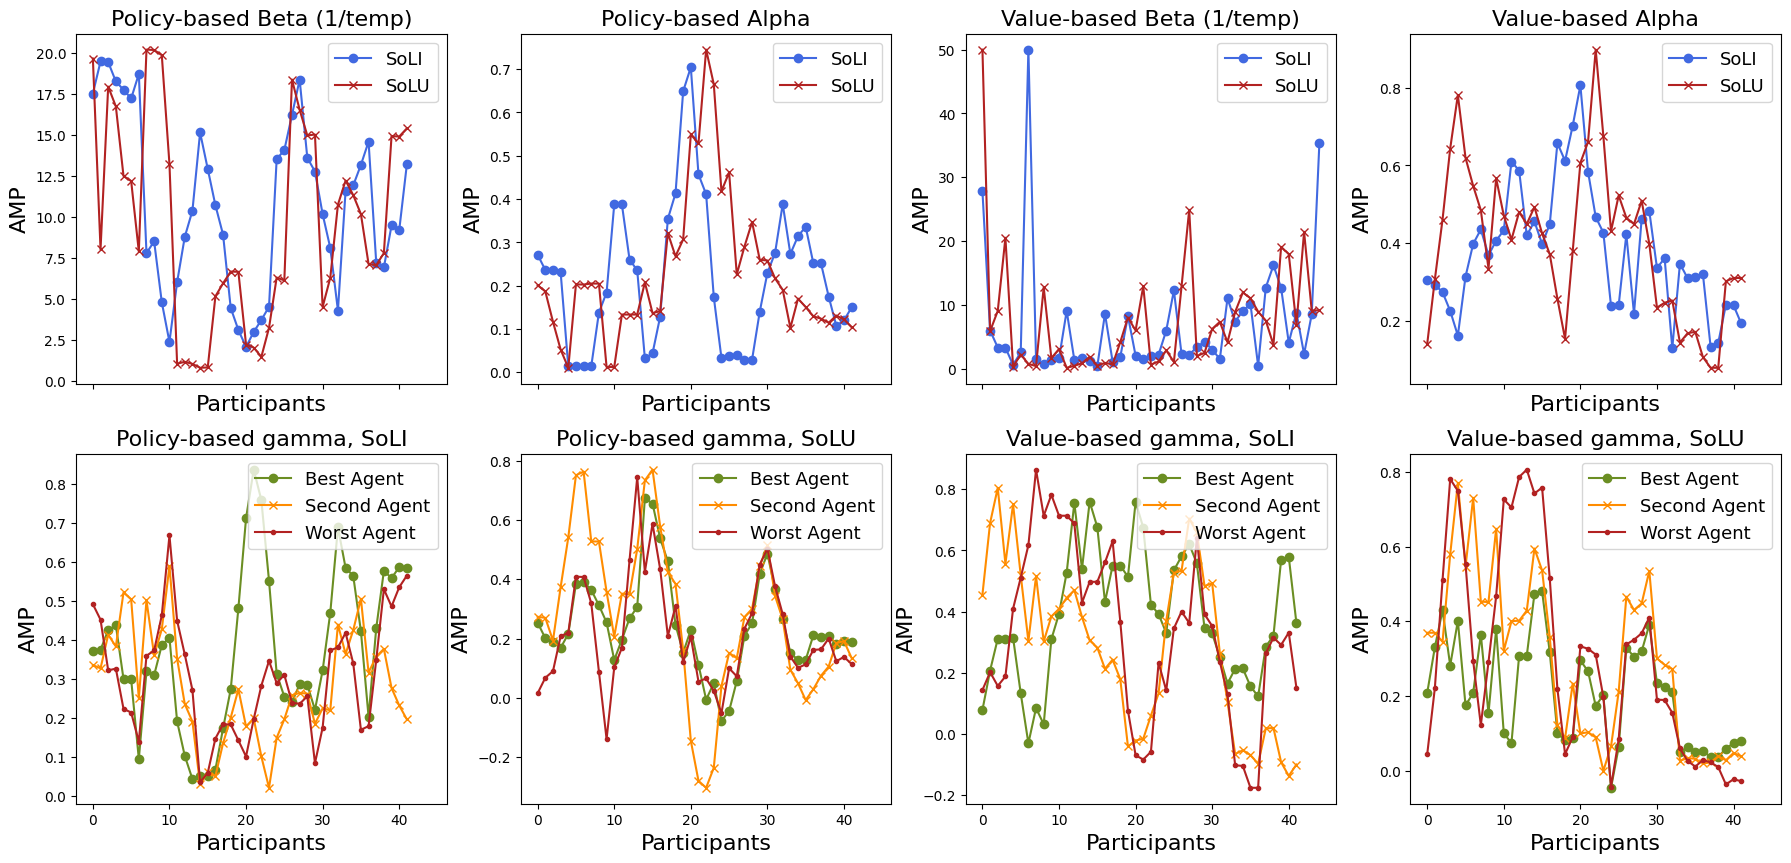

In [30]:
fig, axs = plt.subplots(2, 4, sharex='all', figsize=(22, 10))




x1 = [i for i in range(45)]
axs[0, 0].plot(np.convolve(sorted_soli_tv_beta, np.ones(4)/4, mode='valid'), marker='o', label='SoLI', color='royalblue')
axs[0, 0].plot(np.convolve(sorted_solu_tv_beta, np.ones(4)/4, mode='valid'), marker='x', label='SoLU', color='firebrick')
axs[0, 0].set_title('Policy-based Beta (1/temp)', fontsize=16)
axs[0, 0].set_xlabel('Participants', fontsize=16)
axs[0, 0].set_ylabel('AMP', fontsize=16)
axs[0, 0].legend(loc=0, prop={'size':13})

axs[0, 1].plot(np.convolve(sorted_soli_tv_alpha, np.ones(4)/4, mode='valid'), marker='o', label='SoLI', color='royalblue')
axs[0, 1].plot(np.convolve(sorted_solu_tv_alpha, np.ones(4)/4, mode='valid'), marker='x', label='SoLU', color='firebrick')
axs[0, 1].set_title('Policy-based Alpha', fontsize=16)
axs[0, 1].set_xlabel('Participants', fontsize=16)
axs[0, 1].set_ylabel('AMP', fontsize=16)
axs[0, 1].legend(loc=0, prop={'size':13})

axs[0, 2].plot(sorted_soli_cv_beta, marker='o', label='SoLI', color='royalblue')
axs[0, 2].plot(sorted_solu_cv_beta, marker='x', label='SoLU', color='firebrick')
axs[0, 2].set_title('Value-based Beta (1/temp)', fontsize=16)
axs[0, 2].set_xlabel('Participants', fontsize=16)
axs[0, 2].set_ylabel('AMP', fontsize=16)
axs[0, 2].legend(loc=0, prop={'size':13})

axs[0, 3].plot(np.convolve(sorted_soli_cv_alpha, np.ones(4)/4, mode='valid'), marker='o', label='SoLI', color='royalblue')
axs[0, 3].plot(np.convolve(sorted_solu_cv_alpha, np.ones(4)/4, mode='valid'), marker='x', label='SoLU', color='firebrick')
axs[0, 3].set_title('Value-based Alpha', fontsize=16)
axs[0, 3].set_xlabel('Participants', fontsize=16)
axs[0, 3].set_ylabel('AMP', fontsize=16)
axs[0, 3].legend(loc=0, prop={'size':13})

axs[1, 0].plot(np.convolve(sorted_soli_tv_gammas[:, 0], np.ones(4)/4, mode='valid'), marker='o', label='Best Agent', color='olivedrab')
axs[1, 0].plot(np.convolve(sorted_soli_tv_gammas[:, 1], np.ones(4)/4, mode='valid'), marker='x', label='Second Agent', color='darkorange')
axs[1, 0].plot(np.convolve(sorted_soli_tv_gammas[:, 2], np.ones(4)/4, mode='valid'), marker='.', label='Worst Agent', color='firebrick')
axs[1, 0].set_title('Policy-based gamma, SoLI', fontsize=16)
axs[1, 0].set_xlabel('Participants', fontsize=16)
axs[1, 0].set_ylabel('AMP', fontsize=16)
axs[1, 0].legend(loc=0, prop={'size':13})

axs[1, 1].plot(np.convolve(sorted_solu_tv_gammas[:, 0], np.ones(4)/4, mode='valid'), marker='o', label='Best Agent', color='olivedrab')
axs[1, 1].plot(np.convolve(sorted_solu_tv_gammas[:, 1], np.ones(4)/4, mode='valid'), marker='x', label='Second Agent', color='darkorange')
axs[1, 1].plot(np.convolve(sorted_solu_tv_gammas[:, 2], np.ones(4)/4, mode='valid'), marker='.', label='Worst Agent', color='firebrick')
axs[1, 1].set_title('Policy-based gamma, SoLU', fontsize=16)
axs[1, 1].set_xlabel('Participants', fontsize=16)
axs[1, 1].set_ylabel('AMP', fontsize=16)
axs[1, 1].legend(loc=0, prop={'size':13})

axs[1, 2].plot(np.convolve(sorted_soli_cv_gammas[:, 0], np.ones(4)/4, mode='valid'), marker='o', label='Best Agent', color='olivedrab')
axs[1, 2].plot(np.convolve(sorted_soli_cv_gammas[:, 1], np.ones(4)/4, mode='valid'), marker='x', label='Second Agent', color='darkorange')
axs[1, 2].plot(np.convolve(sorted_soli_cv_gammas[:, 2], np.ones(4)/4, mode='valid'), marker='.', label='Worst Agent', color='firebrick')
axs[1, 2].set_title('Value-based gamma, SoLI', fontsize=16)
axs[1, 2].set_xlabel('Participants', fontsize=16)
axs[1, 2].set_ylabel('AMP', fontsize=16)
axs[1, 2].legend(loc=0, prop={'size':13})

axs[1, 3].plot(np.convolve(sorted_solu_cv_gammas[:, 0], np.ones(4)/4, mode='valid'), marker='o', label='Best Agent', color='olivedrab')
axs[1, 3].plot(np.convolve(sorted_solu_cv_gammas[:, 1], np.ones(4)/4, mode='valid'), marker='x', label='Second Agent', color='darkorange')
axs[1, 3].plot(np.convolve(sorted_solu_cv_gammas[:, 2], np.ones(4)/4, mode='valid'), marker='.', label='Worst Agent', color='firebrick')
axs[1, 3].set_title('Value-based gamma, SoLU', fontsize=16)
axs[1, 3].set_xlabel('Participants', fontsize=16)
axs[1, 3].set_ylabel('AMP', fontsize=16)
axs[1, 3].legend(loc=0, prop={'size':13})


# fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/main/paper draft/Figures/newRL1.svg')

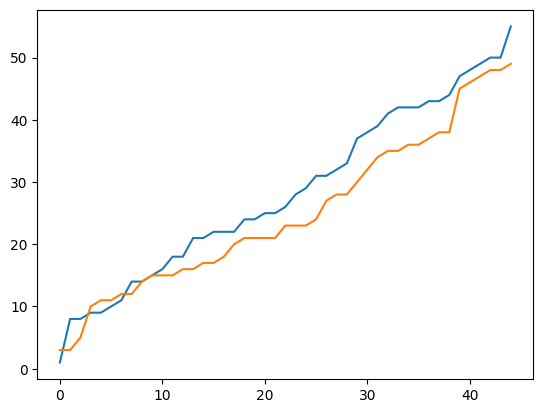

In [31]:
plt.plot(soli_sorted_perf)
plt.plot(solu_sorted_perf)

In [32]:
sorted_soli_cv_gammas[:45, 0]

array([ 4.87418901e-03,  2.29612231e-02,  9.03616899e-03,  2.75781034e-01,
        5.20830867e-01,  4.39504501e-01,  3.79575297e-04,  2.98655853e-01,
       -2.08970892e-01, -2.13474844e-01,  4.61813018e-01,  8.57239118e-02,
        9.04481772e-01,  1.20161403e-01,  1.00000000e+00,  1.00000000e+00,
        3.85058829e-02,  1.00000000e+00,  6.67994537e-01,  1.89422422e-02,
        5.15806125e-01,  1.00000000e+00,  5.20740657e-01,  1.00000000e+00,
        1.78829950e-01, -6.89802930e-03,  3.95067428e-01,  7.52872700e-01,
        1.00000000e+00,  1.76062838e-01,  5.55160554e-01,  4.99098476e-01,
        1.54765542e-01,  1.04663348e-01,  2.43446816e-01,  1.55994006e-01,
        3.47928432e-01,  1.08435433e-01,  9.72289705e-03,  2.37573174e-02,
        1.00000000e+00,  2.51009953e-01,  1.00000000e+00,  6.48282973e-02,
        1.33711012e-01])

# Simple RL

In [33]:
def Q_4arms(x, *args):
    alpha_ind, beta_ind, alpha, beta = x
    actions, rewards = args

    Q = np.zeros(4) * 0.5
    logp_actions = np.zeros(len(actions))

    for t, (a, r) in enumerate(zip(actions, rewards)):
        
        
        if t > 15:
            Q_ = Q * beta
            logp_action = Q_ - scipy.special.logsumexp(Q_)
            logp_actions[t] = logp_action[a]
            Q[a] = Q[a] + alpha * (r - Q[a])
        else:
            Q_ = Q * beta_ind
            logp_action = Q_ - scipy.special.logsumexp(Q_)
            logp_actions[t] = logp_action[a]
            Q[a] = Q[a] + alpha_ind * (r - Q[a])
    return -np.sum(logp_actions[1:])

In [34]:
import os
import scipy
all_soli_simple_alpha_ind = []
all_soli_simple_beta_ind = []
all_soli_simple_alpha = []
all_soli_simple_beta = []
all_soli_simple_neg_ll = []
for sub in all_trained_4arm_df:
  frame = sub
  actions = frame['choice'][:105]
  rewards = (frame['outcome'][:105] == 'win') * 1
  true_alpha = 0.2
  true_beta = 20
  x0 = [0.2, 20, true_alpha, true_beta]
  result = scipy.optimize.minimize(Q_4arms, x0, args=(actions, rewards), method="L-BFGS-B" ,bounds=((0.01, 1), (0.01, 50), (0.01, 1), (0.01, 50)))
  print(result)
  print("")
  print(f"MLE: alpha = {result.x[0]:.2f}")
  print(f"MLE: epsilon = {result.x[1]:.2f}")
  all_soli_simple_alpha_ind.append(result.x[0])
  all_soli_simple_beta_ind.append(result.x[1])
  all_soli_simple_alpha.append(result.x[2])
  all_soli_simple_beta.append(result.x[3])
  all_soli_simple_neg_ll.append(result.fun)

  message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
  success: True
   status: 0
      fun: 122.24151353576661
        x: [ 3.216e-02  2.076e+01  2.491e-02  3.470e+00]
      nit: 44
      jac: [ 1.214e-03  2.842e-06  2.132e-05 -2.842e-06]
     nfev: 265
     njev: 53
 hess_inv: <4x4 LbfgsInvHessProduct with dtype=float64>

MLE: alpha = 0.03
MLE: epsilon = 20.76
  message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
  success: True
   status: 0
      fun: 56.219982268349895
        x: [ 9.650e-01  5.000e+01  2.720e-01  6.510e+00]
      nit: 41
      jac: [-1.421e-06 -1.283e-03 -4.832e-05  1.421e-05]
     nfev: 245
     njev: 49
 hess_inv: <4x4 LbfgsInvHessProduct with dtype=float64>

MLE: alpha = 0.96
MLE: epsilon = 50.00
  message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
  success: True
   status: 0
      fun: 115.05334870647712
        x: [ 4.736e-02  1.364e+01  2.963e-01  3.735e+00]
      nit: 25
      jac: [-3.197e-04  0.000e+00  1.421e-04  4.263e-06]
     nfev: 1

In [35]:
import os
import scipy
all_solu_simple_alpha_ind = []
all_solu_simple_beta_ind = []
all_solu_simple_alpha = []
all_solu_simple_beta = []
all_solu_simple_neg_ll = []
for sub in all_not_trained_4arm_df:
  frame = sub
  actions = frame['choice'][:105]
  rewards = (frame['outcome'][:105] == 'win') * 1
  true_alpha = 0.2
  true_beta = 20
  x0 = [0.2, 20, true_alpha, true_beta]
  result = scipy.optimize.minimize(Q_4arms, x0, args=(actions, rewards), method="L-BFGS-B" ,bounds=((0.01, 1), (0.01, 50), (0.01, 1), (0.01, 50)))
  print(result)
  print("")
  print(f"MLE: alpha = {result.x[0]:.2f}")
  print(f"MLE: epsilon = {result.x[1]:.2f}")
  all_solu_simple_alpha_ind.append(result.x[0])
  all_solu_simple_beta_ind.append(result.x[1])
  all_solu_simple_alpha.append(result.x[2])
  all_solu_simple_beta.append(result.x[3])
  all_solu_simple_neg_ll.append(result.fun)

  message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
  success: True
   status: 0
      fun: 145.1095652478107
        x: [ 1.000e-02  1.750e+01  1.000e-02  1.000e-02]
      nit: 3
      jac: [ 9.888e+01  5.677e-02  2.475e-01  2.937e-01]
     nfev: 25
     njev: 5
 hess_inv: <4x4 LbfgsInvHessProduct with dtype=float64>

MLE: alpha = 0.01
MLE: epsilon = 17.50
  message: CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL
  success: True
   status: 0
      fun: 142.5590361412295
        x: [ 8.085e-01  1.236e+00  1.000e-02  1.000e-02]
      nit: 21
      jac: [-5.684e-06 -2.842e-06  3.099e-02  4.255e-01]
     nfev: 170
     njev: 34
 hess_inv: <4x4 LbfgsInvHessProduct with dtype=float64>

MLE: alpha = 0.81
MLE: epsilon = 1.24
  message: CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL
  success: True
   status: 0
      fun: 138.50021677773526
        x: [ 1.000e-02  1.000e-02  8.597e-01  1.091e+00]
      nit: 30
      jac: [ 1.106e+01  3.974e-02  0.000e+00  0.000e+00]
     nfev: 175
 

# Parameter Recovery

In [36]:
import ast
import matplotlib.pyplot as plt

from scipy.optimize import minimize
from scipy.special import logsumexp, softmax
from scipy.stats import pearsonr, spearmanr
from IPython.display import display

# Check that original model functions are available
assert 'core_value_Qmean_model' in globals()
assert 'temporary_value_Qmean_model' in globals()
assert 'Q_4arms' in globals()
assert len(all_sub_df) == 90, "Expected 90 social-group participants"

# Same parameter bounds as your original fitting code
RECOVERY_BOUNDS_2 = (
    (0.01, 1.0),
    (0.01, 50.0)
)

RECOVERY_BOUNDS_4 = RECOVERY_BOUNDS_2 * 2

RECOVERY_BOUNDS_7 = (
    RECOVERY_BOUNDS_2 * 2
    + ((-1.0, 1.0),) * 3
)

PARAM_NAMES = [
    "alpha_ind",
    "beta_ind",
    "alpha_social",
    "beta_social",
    "gamma1",
    "gamma2",
    "gamma3"
]


def block1_nll(params, actions, rewards):
    """
    Negative log-likelihood for the first 15 trials.

    This matches the individual-learning portion
    of both original social RL models.
    """

    alpha_ind, beta_ind = params

    Q = np.zeros(4, dtype=float)
    logp = np.zeros(len(actions), dtype=float)

    for t, (a, r) in enumerate(zip(actions, rewards)):

        logits = beta_ind * Q

        logp[t] = (
            logits[int(a)] - logsumexp(logits)
        )

        Q[int(a)] += alpha_ind * (
            float(r) - Q[int(a)]
        )

    # Same convention as your original notebook:
    # omit the first choice likelihood
    return -float(logp[1:].sum())


def get_probabilities(frame):
    """
    Read the actual card probabilities and
    their placements from a participant's data.
    """

    return np.stack([
        np.asarray(
            ast.literal_eval(s) if isinstance(s, str) else s,
            dtype=float
        )
        for s in frame["card probs"].iloc[:105]
    ])


# Validate against your original likelihood functions
frame = all_sub_df[0]

actions = np.asarray(
    frame["choice"][:15], dtype=int
)

rewards = (
    np.asarray(frame["outcome"][:15]) == "win"
).astype(int)

agent_choices = frame["agent_choices"][:15]
chosen_agents = frame["chosen_agent"][:15]

test_params = np.array([0.31, 8.0])

test_params_7 = np.r_[
    test_params,
    [0.3, 8.0, 0.2, 0.1, 0.1]
]

assert np.isclose(
    block1_nll(test_params, actions, rewards),
    core_value_Qmean_model(
        test_params_7,
        actions,
        rewards,
        agent_choices,
        chosen_agents
    ),
    atol=1e-9
)

assert np.isclose(
    block1_nll(test_params, actions, rewards),
    temporary_value_Qmean_model(
        test_params_7,
        actions,
        rewards,
        agent_choices,
        chosen_agents
    ),
    atol=1e-9
)

print("Validation successful.")
print("Block-1 likelihood matches both original social models.")

Validation successful.
Block-1 likelihood matches both original social models.


In [37]:
def generate_block1(alpha_ind, beta_ind, probabilities, rng):
    """
    Simulate 15 trials using known individual
    learning-rate and inverse-temperature values.
    """

    Q = np.zeros(4, dtype=float)

    actions = np.empty(15, dtype=int)
    rewards = np.empty(15, dtype=int)

    for t in range(15):

        probabilities_of_choice = softmax(beta_ind * Q)

        actions[t] = rng.choice(
            4,
            p=probabilities_of_choice
        )

        rewards[t] = int(
            rng.random() < probabilities[t, actions[t]]
        )

        action = actions[t]
        reward = rewards[t]

        Q[action] += alpha_ind * (
            reward - Q[action]
        )

    return actions, rewards


def firstblock_recovery(
    n_sims=300,
    seed=2026,
    n_starts=3,
    parameter_source="broad"
):
    rng = np.random.default_rng(seed)

    # Parameters obtained from your original fitted models
    empirical_parameters = np.vstack([
        np.column_stack([
            all_cv_alpha_ind_Qmean,
            all_cv_epsilon_ind_Qmean
        ]),
        np.column_stack([
            all_tv_alpha_ind_Qmean,
            all_tv_beta_ind_Qmean
        ])
    ])

    results = []

    for iteration in range(n_sims):

        subject_index = int(
            rng.integers(0, len(all_sub_df))
        )

        probabilities = get_probabilities(
            all_sub_df[subject_index]
        )[:15]

        # Choose known generating parameters
        if parameter_source == "empirical":

            alpha_true, beta_true = empirical_parameters[
                int(rng.integers(len(empirical_parameters)))
            ]

        elif parameter_source == "broad":

            alpha_true = rng.uniform(0.05, 0.95)

            beta_true = np.exp(
                rng.uniform(
                    np.log(0.5),
                    np.log(40.0)
                )
            )

        else:
            raise ValueError(
                "parameter_source must be 'broad' or 'empirical'"
            )

        # Simulate choices and rewards
        simulated_actions, simulated_rewards = generate_block1(
            alpha_true,
            beta_true,
            probabilities,
            rng
        )

        # Multiple optimization starting points
        starting_points = [[0.2, 20.0]]

        for _ in range(n_starts - 1):

            starting_points.append([
                rng.uniform(0.05, 0.95),
                np.exp(
                    rng.uniform(
                        np.log(0.5),
                        np.log(40.0)
                    )
                )
            ])

        fits = []

        for x0 in starting_points:

            fit = minimize(
                block1_nll,
                x0=x0,
                args=(simulated_actions, simulated_rewards),
                method="L-BFGS-B",
                bounds=RECOVERY_BOUNDS_2
            )

            if np.isfinite(fit.fun):
                fits.append(fit)

        if not fits:
            raise RuntimeError(
                f"No finite fit for simulation {iteration}"
            )

        # Retain the fit with the lowest NLL
        best_fit = min(
            fits,
            key=lambda result: result.fun
        )

        results.append({
            "simulation": iteration,
            "source": parameter_source,
            "participant_template": subject_index,

            "alpha_ind_true": alpha_true,
            "alpha_ind_est": best_fit.x[0],

            "beta_ind_true": beta_true,
            "beta_ind_est": best_fit.x[1],

            "fit_success": bool(best_fit.success),
            "NLL": best_fit.fun
        })

    return pd.DataFrame(results)


# Broad parameter-range recovery
recovery_broad = firstblock_recovery(
    n_sims=300,
    seed=2026,
    n_starts=3,
    parameter_source="broad"
)

# Recovery using parameters from empirical fits
recovery_empirical = firstblock_recovery(
    n_sims=300,
    seed=2028,
    n_starts=3,
    parameter_source="empirical"
)

# Combine both recovery analyses
block1_recovery = pd.concat(
    [recovery_broad, recovery_empirical],
    ignore_index=True
)

display(
    block1_recovery.groupby("source").size()
)

block1_recovery.to_csv(
    "parameter_recovery_first15.csv",
    index=False
)

print("15-trial recovery completed.")
print("Saved: parameter_recovery_first15.csv")

source
broad        300
empirical    300
dtype: int64

15-trial recovery completed.
Saved: parameter_recovery_first15.csv


In [38]:
def social_observation_impact(t, ag_choice, chosen_agent, gammas):

    impact = np.zeros(4, dtype=float)

    if t < 15 or t % 3 != 0:
        return impact

    if 15 <= t < 45:

        choices = (
            ast.literal_eval(ag_choice)
            if isinstance(ag_choice, str)
            else ag_choice
        )

        for j, card in enumerate(choices):
            impact[int(card)] += gammas[j]

    elif t >= 45 and chosen_agent in ("A", "B", "C"):

        agent_index = {
            "A": 0,
            "B": 1,
            "C": 2
        }[chosen_agent]

        try:
            card = int(ag_choice)

            if 0 <= card < 4:
                impact[card] += gammas[agent_index]

        except (ValueError, TypeError):
            pass

    return impact


def simulate_full_original_model(kind, true_parameters, frame, rng):

    params = np.asarray(true_parameters, dtype=float)

    probabilities = get_probabilities(frame)

    agent_choices = frame["agent_choices"].iloc[:105].tolist()
    chosen_agents = frame["chosen_agent"].iloc[:105].tolist()

    Q = np.zeros(4, dtype=float)

    actions = np.empty(105, dtype=int)
    rewards = np.empty(105, dtype=int)
    log_probabilities = np.empty(105, dtype=float)

    observation_impact = np.zeros(4, dtype=float)

    for t in range(105):

        if kind == "Baseline":

            # Reproduce your original baseline implementation
            alpha = params[0] if t <= 15 else params[2]
            beta = params[1] if t <= 15 else params[3]

            decision_Q = Q

        else:

            # Block transitions in the two social models
            if t in (15, 45):
                Q[:] = Q.mean()

            if t < 15:

                alpha = params[0]
                beta = params[1]
                decision_Q = Q

            else:

                alpha = params[2]
                beta = params[3]

                if t % 3 == 0:

                    observation_impact = social_observation_impact(
                        t,
                        agent_choices[t],
                        chosen_agents[t],
                        params[4:7]
                    )

                    if kind == "Value-based":
                        Q += observation_impact

                if kind == "Policy-based":
                    decision_Q = Q + observation_impact
                else:
                    decision_Q = Q

        # Generate a choice
        choice_probabilities = softmax(beta * decision_Q)

        action = int(
            rng.choice(4, p=choice_probabilities)
        )

        # Generate reward from actual card probability
        reward = int(
            rng.random() < probabilities[t, action]
        )

        log_probabilities[t] = np.log(
            max(choice_probabilities[action], 1e-300)
        )

        actions[t] = action
        rewards[t] = reward

        # Update learned value
        Q[action] += alpha * (reward - Q[action])

    # Original fitting functions
    functions = {
        "Baseline": Q_4arms,
        "Value-based": core_value_Qmean_model,
        "Policy-based": temporary_value_Qmean_model
    }

    function = functions[kind]

    if kind == "Baseline":
        args = (actions, rewards)
    else:
        args = (
            actions,
            rewards,
            agent_choices,
            chosen_agents
        )

    # Check simulation against the original likelihood
    original_nll = float(function(params, *args))

    simulated_nll = float(
        -log_probabilities[1:].sum()
    )

    if not np.isclose(
        original_nll,
        simulated_nll,
        atol=1e-7,
        rtol=0
    ):
        raise AssertionError(
            f"{kind}: simulated and original likelihoods disagree: "
            f"{original_nll} vs {simulated_nll}"
        )

    return args


def full_parameter_matrix(kind):

    if kind == "Value-based":

        return np.column_stack([
            all_cv_alpha_ind_Qmean,
            all_cv_epsilon_ind_Qmean,
            all_cv_alpha_Qmean,
            all_cv_epsilon_Qmean,
            np.asarray(all_cv_gamma_Qmean)
        ])

    if kind == "Policy-based":

        return np.column_stack([
            all_tv_alpha_ind_Qmean,
            all_tv_beta_ind_Qmean,
            all_tv_alpha_Qmean,
            all_tv_beta_Qmean,
            np.asarray(all_tv_gamma_Qmean)
        ])

    return np.column_stack([
        np.r_[
            all_soli_simple_alpha_ind,
            all_solu_simple_alpha_ind
        ],
        np.r_[
            all_soli_simple_beta_ind,
            all_solu_simple_beta_ind
        ],
        np.r_[
            all_soli_simple_alpha,
            all_solu_simple_alpha
        ],
        np.r_[
            all_soli_simple_beta,
            all_solu_simple_beta
        ]
    ])


def full_parameter_recovery(
    n_sims_per_model=90,
    seed=2027,
    n_starts=1,
    kinds=("Value-based", "Policy-based")
):

    rng = np.random.default_rng(seed)

    results = []

    functions = {
        "Baseline": Q_4arms,
        "Value-based": core_value_Qmean_model,
        "Policy-based": temporary_value_Qmean_model
    }

    for kind in kinds:

        print("Recovering:", kind, flush=True)

        fitted_parameters = full_parameter_matrix(kind)

        expected_parameters = 4 if kind == "Baseline" else 7

        assert fitted_parameters.shape == (
            90,
            expected_parameters
        )

        subject_indices = rng.choice(
            90,
            size=n_sims_per_model,
            replace=n_sims_per_model > 90
        )

        function = functions[kind]

        bounds = (
            RECOVERY_BOUNDS_4
            if kind == "Baseline"
            else RECOVERY_BOUNDS_7
        )

        default_start = np.array(
            [0.2, 20.0, 0.2, 20.0]
            + (
                []
                if kind == "Baseline"
                else [0.2, 0.2, 0.2]
            )
        )

        names = (
            PARAM_NAMES[:4]
            if kind == "Baseline"
            else PARAM_NAMES
        )

        for run, subject in enumerate(subject_indices):

            true_parameters = np.asarray(
                fitted_parameters[subject],
                dtype=float
            )

            # Simulate complete 105-trial task
            args = simulate_full_original_model(
                kind,
                true_parameters,
                all_sub_df[subject],
                rng
            )

            starting_points = [default_start.copy()]

            for _ in range(n_starts - 1):

                start = [
                    rng.uniform(0.05, 0.95),
                    rng.uniform(1, 35),
                    rng.uniform(0.05, 0.95),
                    rng.uniform(1, 35)
                ]

                if kind != "Baseline":
                    start.extend(
                        rng.uniform(-0.8, 0.8, 3)
                    )

                starting_points.append(np.array(start))

            # Refit simulated participant
            fits = [
                minimize(
                    function,
                    x0=start,
                    args=args,
                    method="L-BFGS-B",
                    bounds=bounds
                )
                for start in starting_points
            ]

            valid_fits = [
                fit
                for fit in fits
                if np.isfinite(fit.fun)
            ]

            if not valid_fits:
                raise RuntimeError(
                    f"Failed fit: {kind}, simulation {run}"
                )

            best_fit = min(
                valid_fits,
                key=lambda fit: fit.fun
            )

            row = {
                "model": kind,
                "run": run,
                "subject_template": int(subject),
                "NLL": float(best_fit.fun),
                "fit_success": bool(best_fit.success)
            }

            for j, name in enumerate(names):

                row[name + "_true"] = true_parameters[j]
                row[name + "_est"] = best_fit.x[j]

            # Recover change in learning rate
            row["delta_alpha_true"] = (
                true_parameters[2] - true_parameters[0]
            )

            row["delta_alpha_est"] = (
                best_fit.x[2] - best_fit.x[0]
            )

            results.append(row)

        print("Finished:", kind, flush=True)

    return pd.DataFrame(results)


# Run full-model recovery
full_recovery = full_parameter_recovery(
    n_sims_per_model=90,
    n_starts=1
)

display(full_recovery.head())

full_recovery.to_csv(
    "parameter_recovery_full105.csv",
    index=False
)

print("Full-model recovery completed.")
print("Saved: parameter_recovery_full105.csv")

Recovering: Value-based


Finished: Value-based
Recovering: Policy-based
Finished: Policy-based


,model,run,subject_template,NLL,fit_success,alpha_ind_true,alpha_ind_est,beta_ind_true,beta_ind_est,alpha_social_true,...,beta_social_true,beta_social_est,gamma1_true,gamma1_est,gamma2_true,gamma2_est,gamma3_true,gamma3_est,delta_alpha_true,delta_alpha_est
0,Value-based,0,78,78.284329,True,0.018937,0.022533,17.706852,18.532780,0.070151,...,12.726249,12.506447,0.105997,0.120969,0.217025,0.241956,0.094231,0.137291,0.051214,0.040366
1,Value-based,1,4,47.582910,True,0.150417,0.181519,7.472186,50.000000,0.078851,...,8.783822,5.811490,0.251010,0.382950,0.309790,0.451850,0.099103,0.131521,-0.071566,-0.110124
2,Value-based,2,17,88.699693,True,0.024253,0.045206,50.000000,18.630587,0.107353,...,2.549721,4.172126,1.000000,1.000000,0.439505,0.401500,0.574583,0.340954,0.083100,0.093556
3,Value-based,3,68,105.224811,True,0.303933,0.024142,3.049721,17.103981,0.998618,...,1.945895,2.931672,0.296723,0.428471,0.453914,0.135703,0.651890,0.437086,0.694684,0.916651
4,Value-based,4,65,12.983434,True,0.016274,0.021365,50.000000,49.843966,1.000000,...,21.440477,50.000000,-0.184868,-0.053305,-0.063440,-1.000000,0.048434,0.022564,0.983726,0.978635


Full-model recovery completed.
Saved: parameter_recovery_full105.csv


PARAMETER RECOVERY RESULTS


,model,parameter,N,Pearson r,Spearman rho,MAE,bias,boundary fraction
0,Block 1 (15 trials; broad parameters),alpha_ind,300,0.461,0.451,0.239,-0.019,0.217
1,Block 1 (15 trials; broad parameters),beta_ind,300,0.702,0.748,13.379,12.167,0.360
2,Block 1 (15 trials; empirical parameters),alpha_ind,300,0.415,0.342,0.274,0.003,0.357
3,Block 1 (15 trials; empirical parameters),beta_ind,300,0.311,0.366,12.856,0.583,0.357
4,Value-based (105 trials),alpha_ind,90,0.456,0.308,0.271,-0.000,0.189
5,Value-based (105 trials),beta_ind,90,0.463,0.577,9.490,0.146,0.278
6,Value-based (105 trials),alpha_social,90,0.938,0.938,0.069,-0.001,0.089
7,Value-based (105 trials),beta_social,90,0.896,0.924,2.365,1.443,0.044
8,Value-based (105 trials),gamma1,90,0.902,0.903,0.110,-0.034,0.144
9,Value-based (105 trials),gamma2,90,0.746,0.809,0.147,-0.037,0.067


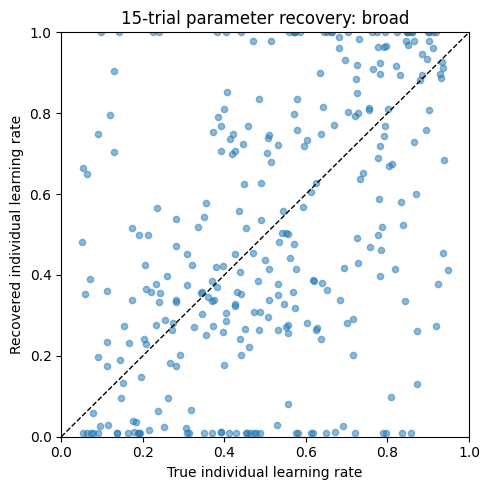

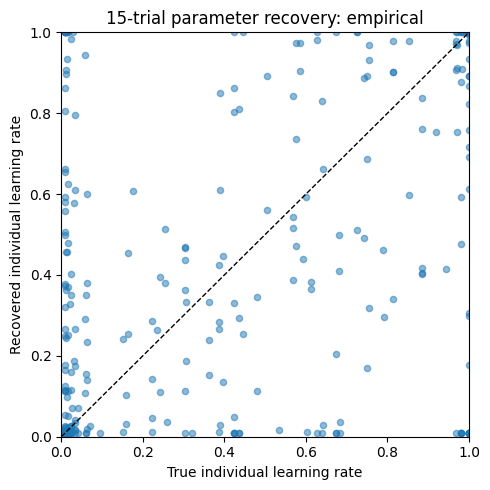

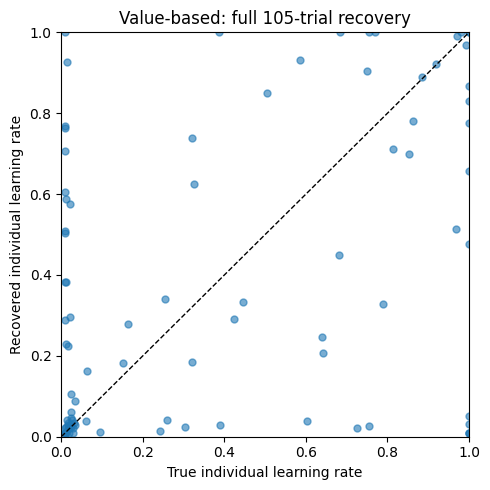

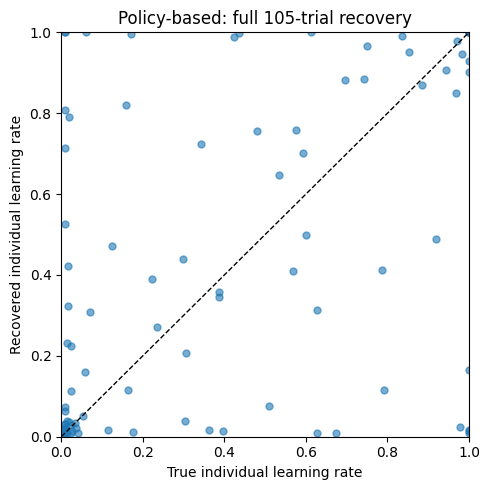

Recovery summary and figures saved.


In [39]:
def recovery_summary(df, columns, model_label):

    rows = []

    for parameter in columns:

        true_values = df[
            parameter + "_true"
        ].to_numpy(float)

        estimated_values = df[
            parameter + "_est"
        ].to_numpy(float)

        valid = (
            np.isfinite(true_values)
            & np.isfinite(estimated_values)
        )

        x = true_values[valid]
        y = estimated_values[valid]

        if len(x) < 3:
            continue

        # Recovery correlations
        if np.std(x) > 0 and np.std(y) > 0:

            pearson = pearsonr(x, y).statistic
            spearman = spearmanr(x, y).statistic

        else:

            pearson = np.nan
            spearman = np.nan

        # Parameter bounds
        bounds = {
            "alpha_ind": (0.01, 1.0),
            "beta_ind": (0.01, 50.0),
            "alpha_social": (0.01, 1.0),
            "beta_social": (0.01, 50.0),
            "gamma1": (-1.0, 1.0),
            "gamma2": (-1.0, 1.0),
            "gamma3": (-1.0, 1.0)
        }

        if parameter in bounds:

            lower, upper = bounds[parameter]

            boundary_fraction = np.mean(
                (y <= lower + 0.001)
                | (y >= upper - 0.001)
            )

        else:

            boundary_fraction = np.nan

        rows.append({
            "model": model_label,
            "parameter": parameter,
            "N": len(x),
            "Pearson r": pearson,
            "Spearman rho": spearman,
            "MAE": np.mean(np.abs(y - x)),
            "bias": np.mean(y - x),
            "boundary fraction": boundary_fraction
        })

    return pd.DataFrame(rows)


# First-block recovery summaries
summary_parts = []

for source, df in block1_recovery.groupby(
    "source",
    sort=False
):

    summary_parts.append(
        recovery_summary(
            df,
            ["alpha_ind", "beta_ind"],
            f"Block 1 (15 trials; {source} parameters)"
        )
    )


# Full-model recovery summaries
for model, df in full_recovery.groupby(
    "model",
    sort=False
):

    parameters = [
        "alpha_ind",
        "beta_ind",
        "alpha_social",
        "beta_social",
        "gamma1",
        "gamma2",
        "gamma3",
        "delta_alpha"
    ]

    if model == "Baseline":
        parameters = [
            "alpha_ind",
            "beta_ind",
            "alpha_social",
            "beta_social",
            "delta_alpha"
        ]

    summary_parts.append(
        recovery_summary(
            df,
            parameters,
            model + " (105 trials)"
        )
    )


# Final recovery table
recovery_table = pd.concat(
    summary_parts,
    ignore_index=True
)

print("PARAMETER RECOVERY RESULTS")

display(recovery_table.round(3))

recovery_table.to_csv(
    "parameter_recovery_summary.csv",
    index=False
)


# Figure 1: Individual learning-rate recovery
for source, df in block1_recovery.groupby(
    "source",
    sort=False
):

    plt.figure(figsize=(5, 5))

    plt.scatter(
        df["alpha_ind_true"],
        df["alpha_ind_est"],
        alpha=0.5,
        s=20
    )

    plt.plot(
        [0, 1],
        [0, 1],
        "k--",
        linewidth=1
    )

    plt.xlim(0, 1)
    plt.ylim(0, 1)

    plt.xlabel("True individual learning rate")
    plt.ylabel("Recovered individual learning rate")

    plt.title(
        f"15-trial parameter recovery: {source}"
    )

    plt.tight_layout()

    plt.savefig(
        f"parameter_recovery_alpha_ind_first15_{source}.png",
        dpi=200
    )

    plt.show()


# Figure 2: Full-model individual learning-rate recovery
for model, df in full_recovery.groupby(
    "model",
    sort=False
):

    plt.figure(figsize=(5, 5))

    plt.scatter(
        df["alpha_ind_true"],
        df["alpha_ind_est"],
        alpha=0.6,
        s=25
    )

    plt.plot(
        [0, 1],
        [0, 1],
        "k--",
        linewidth=1
    )

    plt.xlim(0, 1)
    plt.ylim(0, 1)

    plt.xlabel("True individual learning rate")
    plt.ylabel("Recovered individual learning rate")

    plt.title(
        f"{model}: full 105-trial recovery"
    )

    plt.tight_layout()

    plt.savefig(
        "parameter_recovery_"
        + model.replace("-", "_")
        + ".png",
        dpi=200
    )

    plt.show()


print("Recovery summary and figures saved.")

# Visualization

## AIC

SoLI

In [40]:
all_soli_simple_neg_ll = np.array(all_soli_simple_neg_ll)

all_soli_simple_aic = 2 * 4 + 2 * all_soli_simple_neg_ll
all_soli_cv_aic = 2 * 7 + 2 * soli_cv_nll
all_soli_tv_aic = 2 * 7 + 2 * soli_tv_nll

SoLU

In [41]:
all_solu_simple_neg_ll = np.array(all_solu_simple_neg_ll)

all_solu_simple_aic = 2 * 4 + 2 * all_solu_simple_neg_ll
all_solu_cv_aic = 2 * 7 + 2 * solu_cv_nll
all_solu_tv_aic = 2 * 7 + 2 * solu_tv_nll

In [42]:
from scipy.special import digamma, gammaln, logsumexp, expit
from IPython.display import display

model_names = ["Baseline", "Value-based", "Policy-based"]

# Columns: Baseline, Value-based, Policy-based
nll_by_group = {
    "SoLI": np.column_stack([
        all_soli_simple_neg_ll,
        soli_cv_nll,
        soli_tv_nll
    ]),
    "SoLU": np.column_stack([
        all_solu_simple_neg_ll,
        solu_cv_nll,
        solu_tv_nll
    ])
}

# Your original models exclude the first trial from NLL.
n_choices = 104

# Free parameters for each model
n_parameters = np.array([4, 7, 7])

log_evidence_by_group = {}

for group, nll in nll_by_group.items():

    if nll.shape != (45, 3) or not np.isfinite(nll).all():
        raise ValueError(
            f"{group}: expected finite 45 x 3 NLL array, got {nll.shape}"
        )

    # BIC = 2*NLL + k*log(n)
    bic = 2 * nll + np.log(n_choices) * n_parameters

    # Approximate log Bayesian model evidence
    log_evidence_by_group[group] = -0.5 * bic

    print(f"{group}: {len(nll)} participants, 3 fitted models")

print("Model evidence matrices created successfully.")


SoLI: 45 participants, 3 fitted models
SoLU: 45 participants, 3 fitted models
Model evidence matrices created successfully.


In [43]:

def rfx_bms(log_evidence, n_samples=500_000, seed=2026):
    """
    Random-effects Bayesian model selection.

    Input:
        log_evidence: participants x models

    Output:
        Expected model frequencies
        Exceedance probabilities (XP)
        Protected exceedance probabilities (PXP)
        Bayesian omnibus risk (BOR)
    """

    L = np.asarray(log_evidence, dtype=float)
    n_people, n_models = L.shape

    # Numerical stability
    L = L - L.max(axis=1, keepdims=True)

    # Uniform Dirichlet prior
    prior = np.ones(n_models)
    alpha = prior.copy()

    # Variational Bayes estimation
    for iteration in range(100_000):

        elog_r = digamma(alpha) - digamma(alpha.sum())

        log_q = L + elog_r
        q = np.exp(
            log_q - logsumexp(log_q, axis=1, keepdims=True)
        )

        new_alpha = prior + q.sum(axis=0)

        if np.max(np.abs(new_alpha - alpha)) < 1e-10:
            alpha = new_alpha
            break

        alpha = new_alpha

    else:
        raise RuntimeError("BMS optimization did not converge")

    # Final posterior model responsibilities
    elog_r = digamma(alpha) - digamma(alpha.sum())
    log_q = L + elog_r

    q = np.exp(
        log_q - logsumexp(log_q, axis=1, keepdims=True)
    )

    # H0: Equal population model frequencies
    F0 = float(
        np.sum(logsumexp(L, axis=1) - np.log(n_models))
    )

    # H1: Unequal, unknown model frequencies
    entropy_r = (
        np.sum(gammaln(alpha))
        - gammaln(alpha.sum())
        - np.sum((alpha - 1) * elog_r)
    )

    entropy_assignments = -np.sum(
        q * np.log(np.maximum(q, 1e-300))
    )

    expected_log_joint = (
        gammaln(prior.sum())
        - np.sum(gammaln(prior))
        + np.sum((prior - 1) * elog_r)
        + np.sum(q * (L + elog_r))
    )

    F1 = float(
        expected_log_joint
        + entropy_r
        + entropy_assignments
    )

    # Bayesian omnibus risk
    bor = float(expit(F0 - F1))

    # Monte Carlo exceedance probabilities
    rng = np.random.default_rng(seed)
    wins = np.zeros(n_models, dtype=int)

    for _ in range(n_samples // 50_000):
        samples = rng.dirichlet(alpha, size=50_000)
        wins += np.bincount(
            samples.argmax(axis=1),
            minlength=n_models
        )

    leftover = n_samples % 50_000
    if leftover:
        samples = rng.dirichlet(alpha, size=leftover)
        wins += np.bincount(
            samples.argmax(axis=1),
            minlength=n_models
        )

    xp = wins / n_samples

    # Protected exceedance probabilities
    pxp = (1 - bor) * xp + bor / n_models

    # Expected population model frequencies
    expected_frequency = alpha / alpha.sum()

    return {
        "expected_frequency": expected_frequency,
        "exceedance_probability": xp,
        "protected_exceedance_probability": pxp,
        "BOR": bor,
        "iterations": iteration + 1
    }

print("RFX-BMS function defined successfully.")


RFX-BMS function defined successfully.


In [44]:

bms_results = {}
rows = []

for group, log_evidence in log_evidence_by_group.items():

    result = rfx_bms(log_evidence)
    bms_results[group] = result

    print(f"\n{'=' * 45}")
    print(f"{group} — Random-effects Bayesian model selection")
    print(f"{'=' * 45}")

    print(f"Bayesian Omnibus Risk (BOR): {result['BOR']:.6f}")

    for i, model in enumerate(model_names):

        rows.append({
            "Group": group,
            "Model": model,
            "Expected frequency": result["expected_frequency"][i],
            "Exceedance probability": result["exceedance_probability"][i],
            "Protected exceedance probability":
                result["protected_exceedance_probability"][i]
        })

# Create results table
bms_table = pd.DataFrame(rows)

print("\nFINAL BAYESIAN MODEL SELECTION RESULTS")

display(bms_table.round(6))

# Optional: save the results table
bms_table.to_csv("RFX_BMS_results.csv", index=False)

print("\nResults saved as RFX_BMS_results.csv")



SoLI — Random-effects Bayesian model selection
Bayesian Omnibus Risk (BOR): 0.000000

SoLU — Random-effects Bayesian model selection
Bayesian Omnibus Risk (BOR): 0.472624

FINAL BAYESIAN MODEL SELECTION RESULTS


,Group,Model,Expected frequency,Exceedance probability,Protected exceedance probability
0,SoLI,Baseline,0.041281,0.000000,0.000000
1,SoLI,Value-based,0.204036,0.000018,0.000018
2,SoLI,Policy-based,0.754682,0.999982,0.999982
3,SoLU,Baseline,0.296940,0.051606,0.184757
4,SoLU,Value-based,0.200089,0.003826,0.159559
5,SoLU,Policy-based,0.502971,0.944568,0.655684



Results saved as RFX_BMS_results.csv


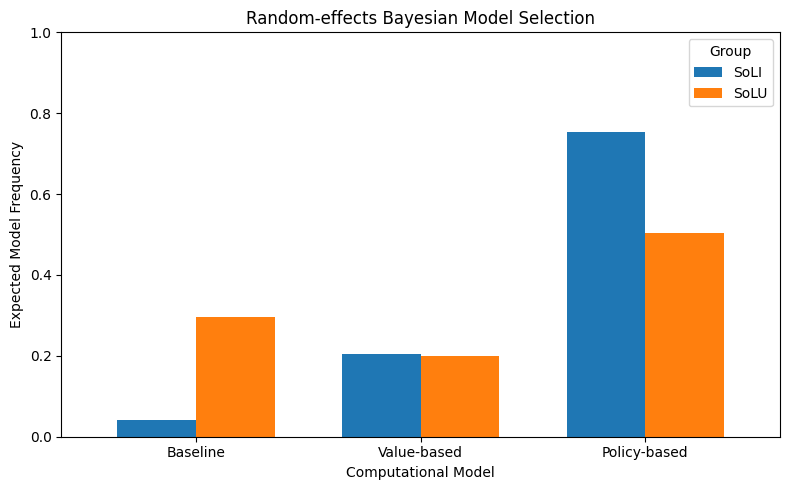

In [45]:

import matplotlib.pyplot as plt

freq_table = bms_table.pivot(
    index="Model",
    columns="Group",
    values="Expected frequency"
)

freq_table = freq_table.reindex(model_names)

ax = freq_table.plot(
    kind="bar",
    figsize=(8, 5),
    width=0.7
)

ax.set_title("Random-effects Bayesian Model Selection")
ax.set_ylabel("Expected Model Frequency")
ax.set_xlabel("Computational Model")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Group")

plt.tight_layout()
plt.show()


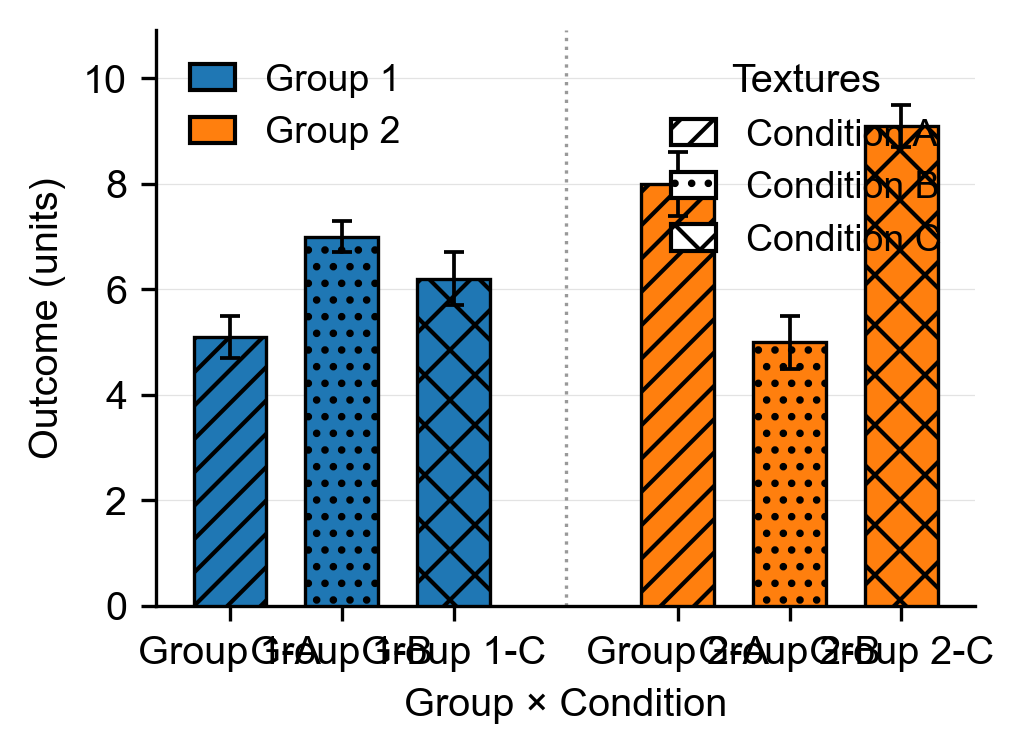

In [46]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# --------------------
# Example data (replace with yours)
# --------------------
group_names   = ["Group 1", "Group 2"]
condition_lbl = ["A", "B", "C"]
vals_g1 = np.array([5.1, 7.0, 6.2])
vals_g2 = np.array([8.0, 5.0, 9.1])
err_g1  = np.array([0.4, 0.3, 0.5])
err_g2  = np.array([0.6, 0.5, 0.4])

# --------------------
# Layout
# --------------------
n = len(condition_lbl)
gap = 1.0          # space between groups
w = 0.65           # bar width
x1 = np.arange(n)
x2 = x1 + n + gap

# Publication-friendly hatch patterns
HATCHES = ['///', '...', 'xx']   # diagonal lines, dots, cross-hatch

# --------------------
# Style (Nature-style)
# --------------------
plt.rcParams.update({
    "figure.dpi": 300,
    "font.size": 9.5,
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
})

# ~89 mm wide (single-column figure size)
fig = plt.figure(figsize=(3.5, 2.6))
ax = plt.gca()

# --------------------
# Bars
# --------------------
bars1 = ax.bar(x1, vals_g1, width=w, edgecolor="black", linewidth=0.8, zorder=3)
bars2 = ax.bar(x2, vals_g2, width=w, edgecolor="black", linewidth=0.8, zorder=3)

# Apply hatches for each condition
for i, b in enumerate(bars1): b.set_hatch(HATCHES[i])
for i, b in enumerate(bars2): b.set_hatch(HATCHES[i])

# Error bars
ax.errorbar(x1, vals_g1, yerr=err_g1, fmt="none", color="black",
            elinewidth=0.9, capsize=2.5, capthick=0.9, zorder=4)
ax.errorbar(x2, vals_g2, yerr=err_g2, fmt="none", color="black",
            elinewidth=0.9, capsize=2.5, capthick=0.9, zorder=4)

# --------------------
# Axes & labels
# --------------------
xticks = list(x1) + list(x2)
ax.set_xticks(xticks)
ax.set_xticklabels(
    [f"{group_names[0]}-{c}" for c in condition_lbl] +
    [f"{group_names[1]}-{c}" for c in condition_lbl]
)
ax.set_ylabel("Outcome (units)")
ax.set_xlabel("Group × Condition")

# Subtle grid and group separator
ax.grid(axis="y", linewidth=0.3, alpha=0.35, zorder=0)
ax.axvline((x1[-1] + x2[0]) / 2, linestyle=":", linewidth=0.8,
           color="black", alpha=0.4)

# Y-axis limit with headroom
ymax = np.max(np.r_[vals_g1+err_g1, vals_g2+err_g2])
ax.set_ylim(0, ymax * 1.15)

# --------------------
# Legends
# --------------------
c1, c2 = bars1[0].get_facecolor(), bars2[0].get_facecolor()
leg_groups = [Patch(facecolor=c1, edgecolor="black", label=group_names[0]),
              Patch(facecolor=c2, edgecolor="black", label=group_names[1])]
leg_tex = [Patch(facecolor="white", edgecolor="black", hatch=h, label=f"Condition {c}")
           for h, c in zip(HATCHES, condition_lbl)]

g1 = ax.legend(handles=leg_groups, loc="upper left", frameon=False,
               fontsize=9, handlelength=1.2)
g2 = ax.legend(handles=leg_tex, loc="upper right", frameon=False,
               fontsize=9, handlelength=1.2, title="Textures")
ax.add_artist(g1)

fig.tight_layout()

# --------------------
# Save outputs
# --------------------
fig.savefig("nhb_grouped_bars.png", dpi=600)  # high-res PNG
fig.savefig("nhb_grouped_bars.pdf")           # vector PDF
plt.show()

C:\Users\AsusIran\AppData\Local\Temp\ipykernel_6112\1576952960.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs.set_xticklabels(x, rotation=45, ha="right", fontsize=fnt_size)


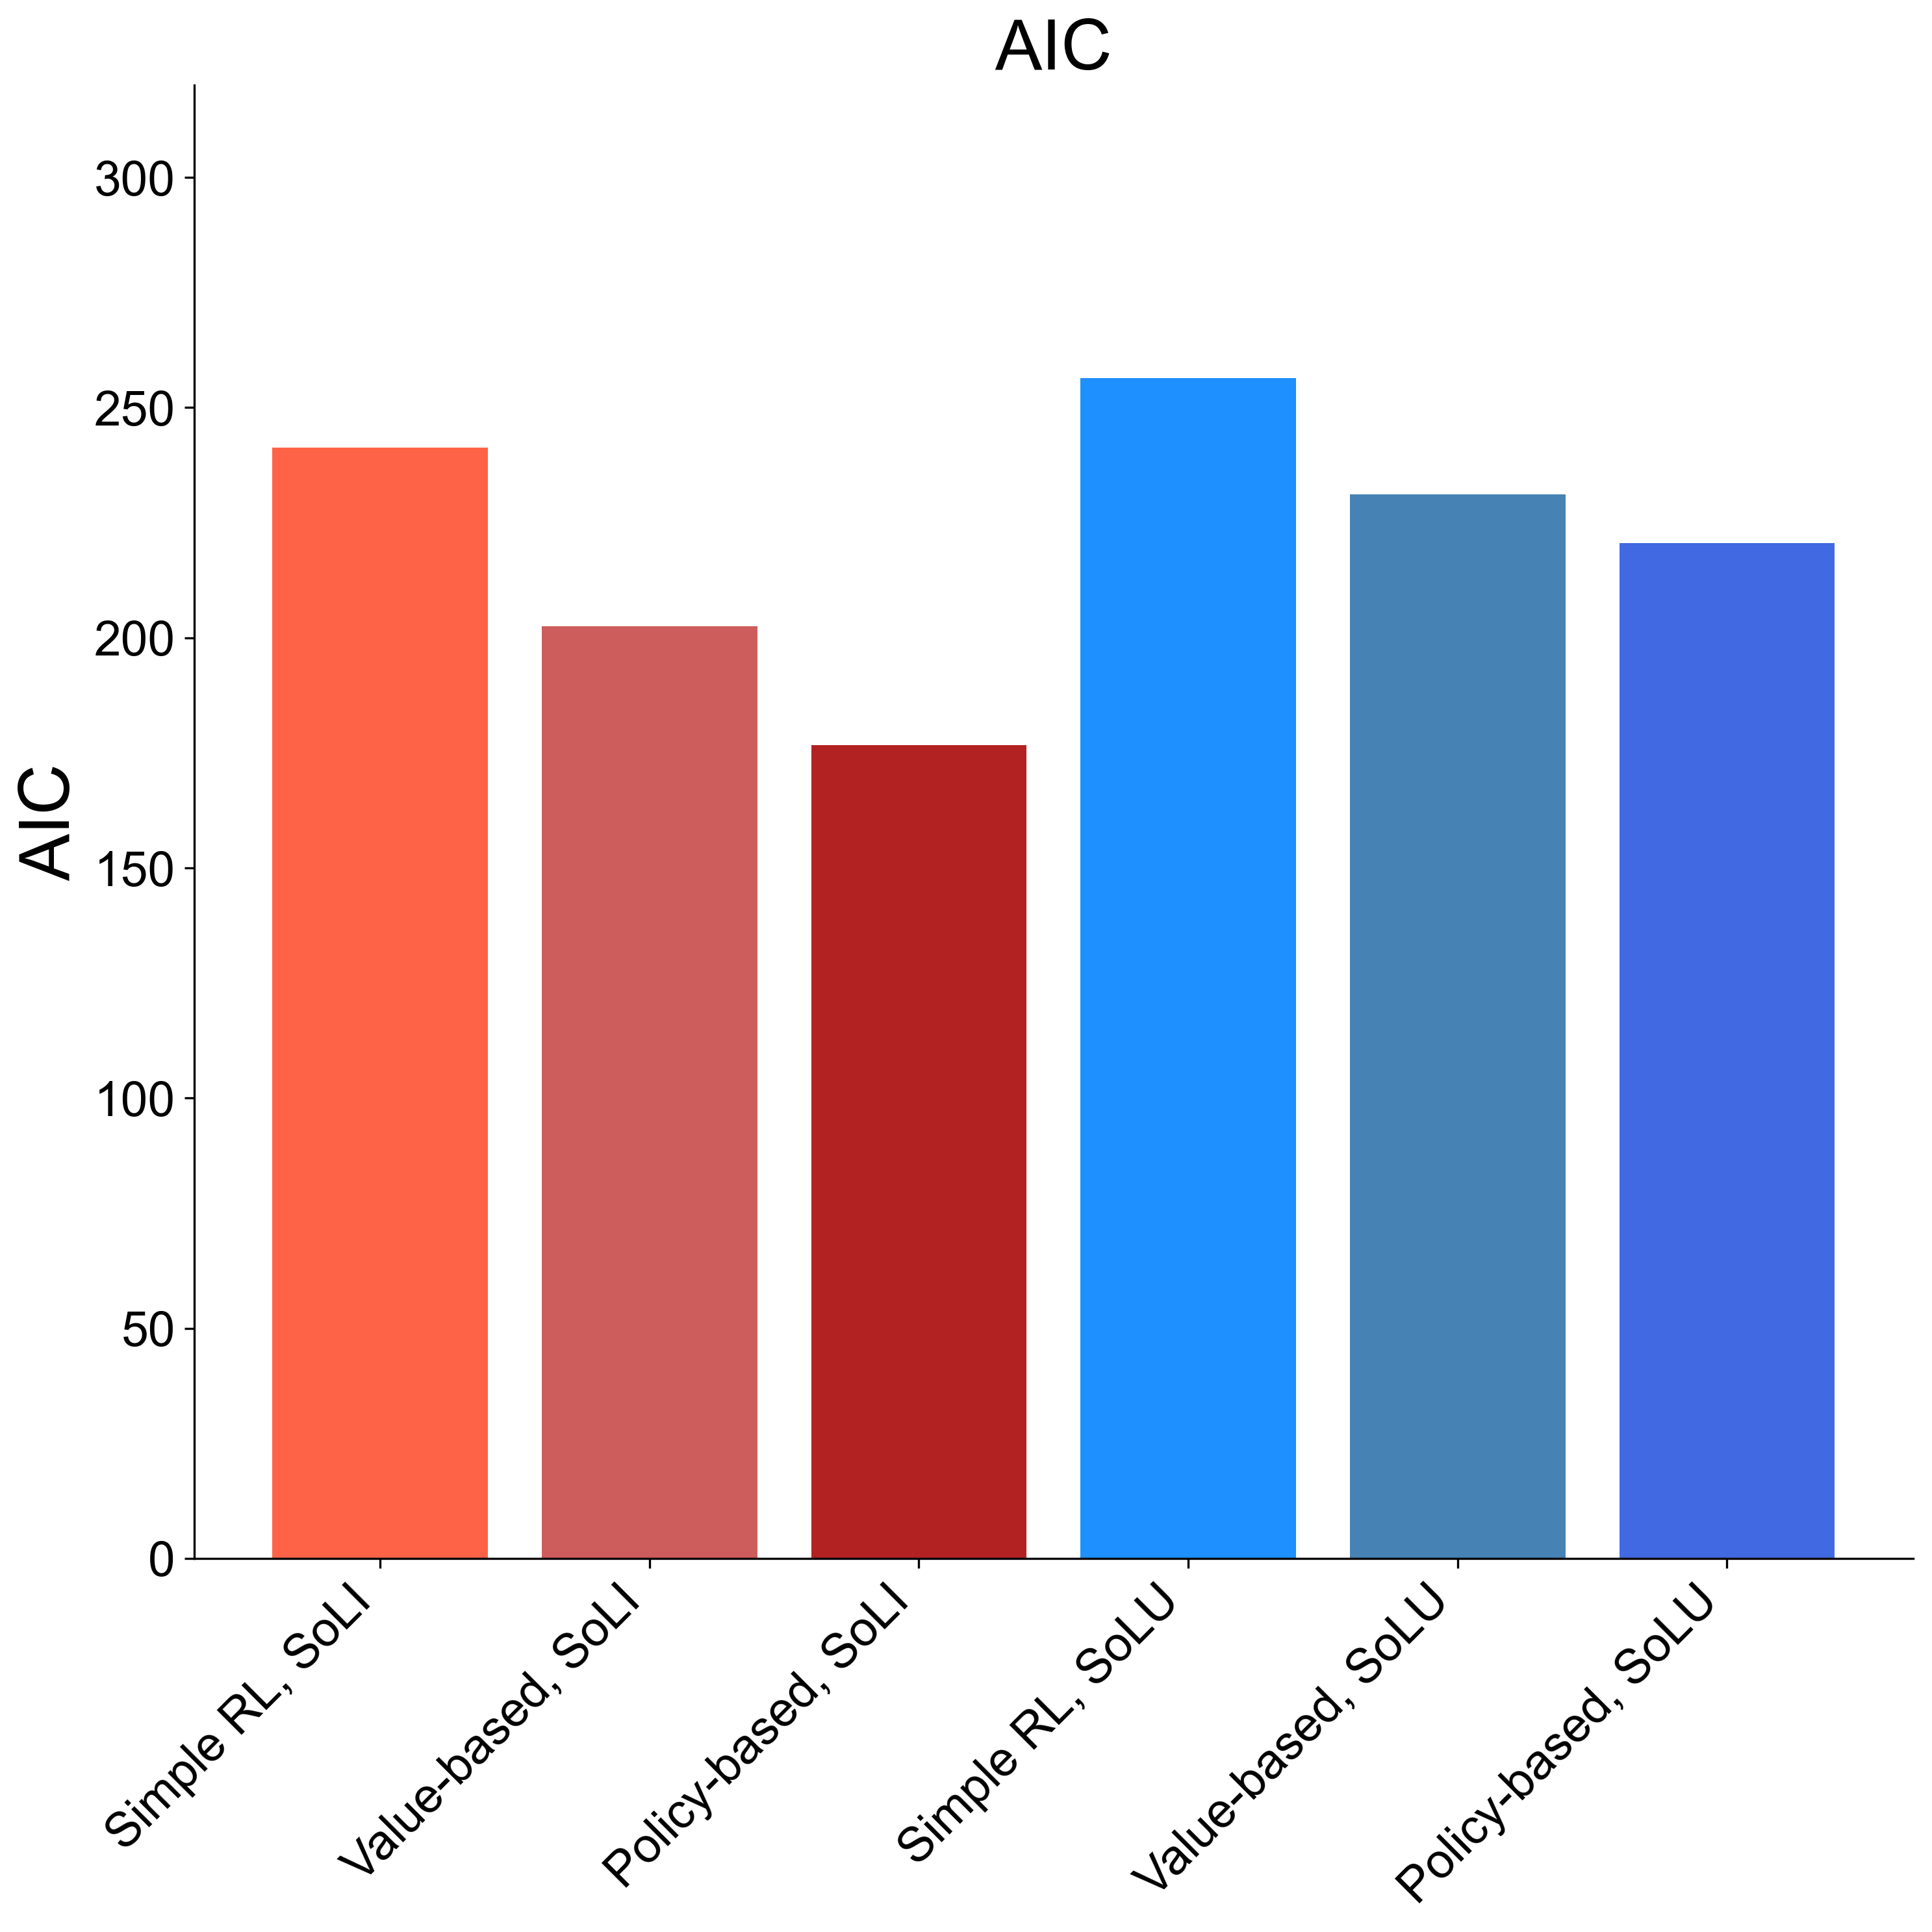

In [47]:
from matplotlib.patches import Patch


import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

x = ['Simple RL, SoLI', 'Value-based, SoLI', 'Policy-based, SoLI',
     'Simple RL, SoLU', 'Value-based, SoLU', 'Policy-based, SoLU']

fnt_size = 26
lbl_size = 26

mean_values = [
    np.mean(all_soli_simple_aic),
    np.mean(all_soli_cv_aic),
    np.mean(all_soli_tv_aic),
    np.mean(all_solu_simple_aic),
    np.mean(all_solu_cv_aic),
    np.mean(all_solu_tv_aic)
]

clr = ['tomato', 'indianred', 'firebrick',
       'dodgerblue', 'steelblue', 'royalblue']
labels = x  # same list

fig, axs = plt.subplots(1, 1, figsize=(10, 10))

axs.bar(x, mean_values, color=clr)
axs.set_ylim([0, 320])

# bigger title
axs.set_title('AIC', fontsize=fnt_size)

# bigger y label
axs.set_ylabel('AIC', fontsize=fnt_size)

# bigger x tick labels
axs.set_xticklabels(x, rotation=45, ha="right", fontsize=fnt_size)

# bigger tick numbers (both axes)
axs.tick_params(axis='both', which='major', labelsize=18)

# legend with bigger font
handles = [Patch(color=clr[i], label=labels[i]) for i in range(len(clr))]
# axs.legend(handles=handles, loc='best', fontsize=12, title='Models', title_fontsize=13)

plt.tight_layout()

fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/main/paper draft/Figures/AIC.svg', bbox_inches='tight', pad_inches=0.02)

In [48]:
from scipy.stats import ttest_ind

# mean_values = [np.mean(all_soli_simple_aic), np.mean(all_soli_cv_aic), np.mean(all_soli_tv_aic), np.mean(all_solu_simple_aic), np.mean(all_solu_cv_aic), np.mean(all_solu_tv_aic)]

t_stat, p_value = ttest_ind(all_soli_simple_aic, all_soli_cv_aic)
print('Simple RL, SoLI VS Value-based, SoLI. t stat: ', t_stat, ' P value:', p_value)
t_stat, p_value = ttest_ind(all_soli_simple_aic, all_soli_tv_aic)
print('Simple RL, SoLI VS Policy-based, SoLI. t stat: ', t_stat, ' P value:', p_value)

t_stat, p_value = ttest_ind(all_soli_cv_aic, all_soli_tv_aic)
print('Value-based, SoLI VS Policy-based, SoLI. t stat: ', t_stat, ' P value:', p_value)

t_stat, p_value = ttest_ind(all_solu_simple_aic, all_solu_cv_aic)
print('Simple RL, SoLU VS Value-based, SoLU. t stat: ', t_stat, ' P value:', p_value)
t_stat, p_value = ttest_ind(all_solu_simple_aic, all_solu_tv_aic)
print('Simple RL, SoLU VS Policy-based, SoLU. t stat: ', t_stat, ' P value:', p_value)

t_stat, p_value = ttest_ind(all_solu_cv_aic, all_solu_tv_aic)
print('Value-based, SoLU VS Policy-based, SoLU. t stat: ', t_stat, ' P value:', p_value)

Simple RL, SoLI VS Value-based, SoLI. t stat:  3.722648410132372  P value: 0.00034709276983800196
Simple RL, SoLI VS Policy-based, SoLI. t stat:  5.3711655468237955  P value: 6.3126958300951e-07
Value-based, SoLI VS Policy-based, SoLI. t stat:  2.015121924368312  P value: 0.04694367992948746
Simple RL, SoLU VS Value-based, SoLU. t stat:  2.430023368359311  P value: 0.017128806304799314
Simple RL, SoLU VS Policy-based, SoLU. t stat:  3.040183175265198  P value: 0.003113955471984417
Value-based, SoLU VS Policy-based, SoLU. t stat:  0.7766013209639261  P value: 0.43947647617852204


## Diff NLL

In [49]:
def sort_with_indices(a):
    idx = np.argsort(a)
    return idx, a[idx]

In [50]:
soli_diff_idx, soli_sorted_diff_nll = sort_with_indices(soli_tv_nll - soli_cv_nll)
solu_diff_idx, solu_sorted_diff_nll = sort_with_indices(solu_tv_nll - solu_cv_nll)


In [51]:
soli_pv_diff_alpha = soli_tv_alpha[soli_diff_idx] - soli_cv_alpha[soli_diff_idx]
soli_pi_diff_alpha = soli_tv_alpha[soli_diff_idx] - soli_tv_alpha_ind[soli_diff_idx]
soli_vi_diff_alpha = soli_cv_alpha[soli_diff_idx] - soli_cv_alpha_ind[soli_diff_idx]

solu_pv_diff_alpha = solu_tv_alpha[soli_diff_idx] - solu_cv_alpha[soli_diff_idx]
solu_pi_diff_alpha = solu_tv_alpha[soli_diff_idx] - solu_tv_alpha_ind[soli_diff_idx]
solu_vi_diff_alpha = solu_cv_alpha[soli_diff_idx] - solu_cv_alpha_ind[soli_diff_idx]

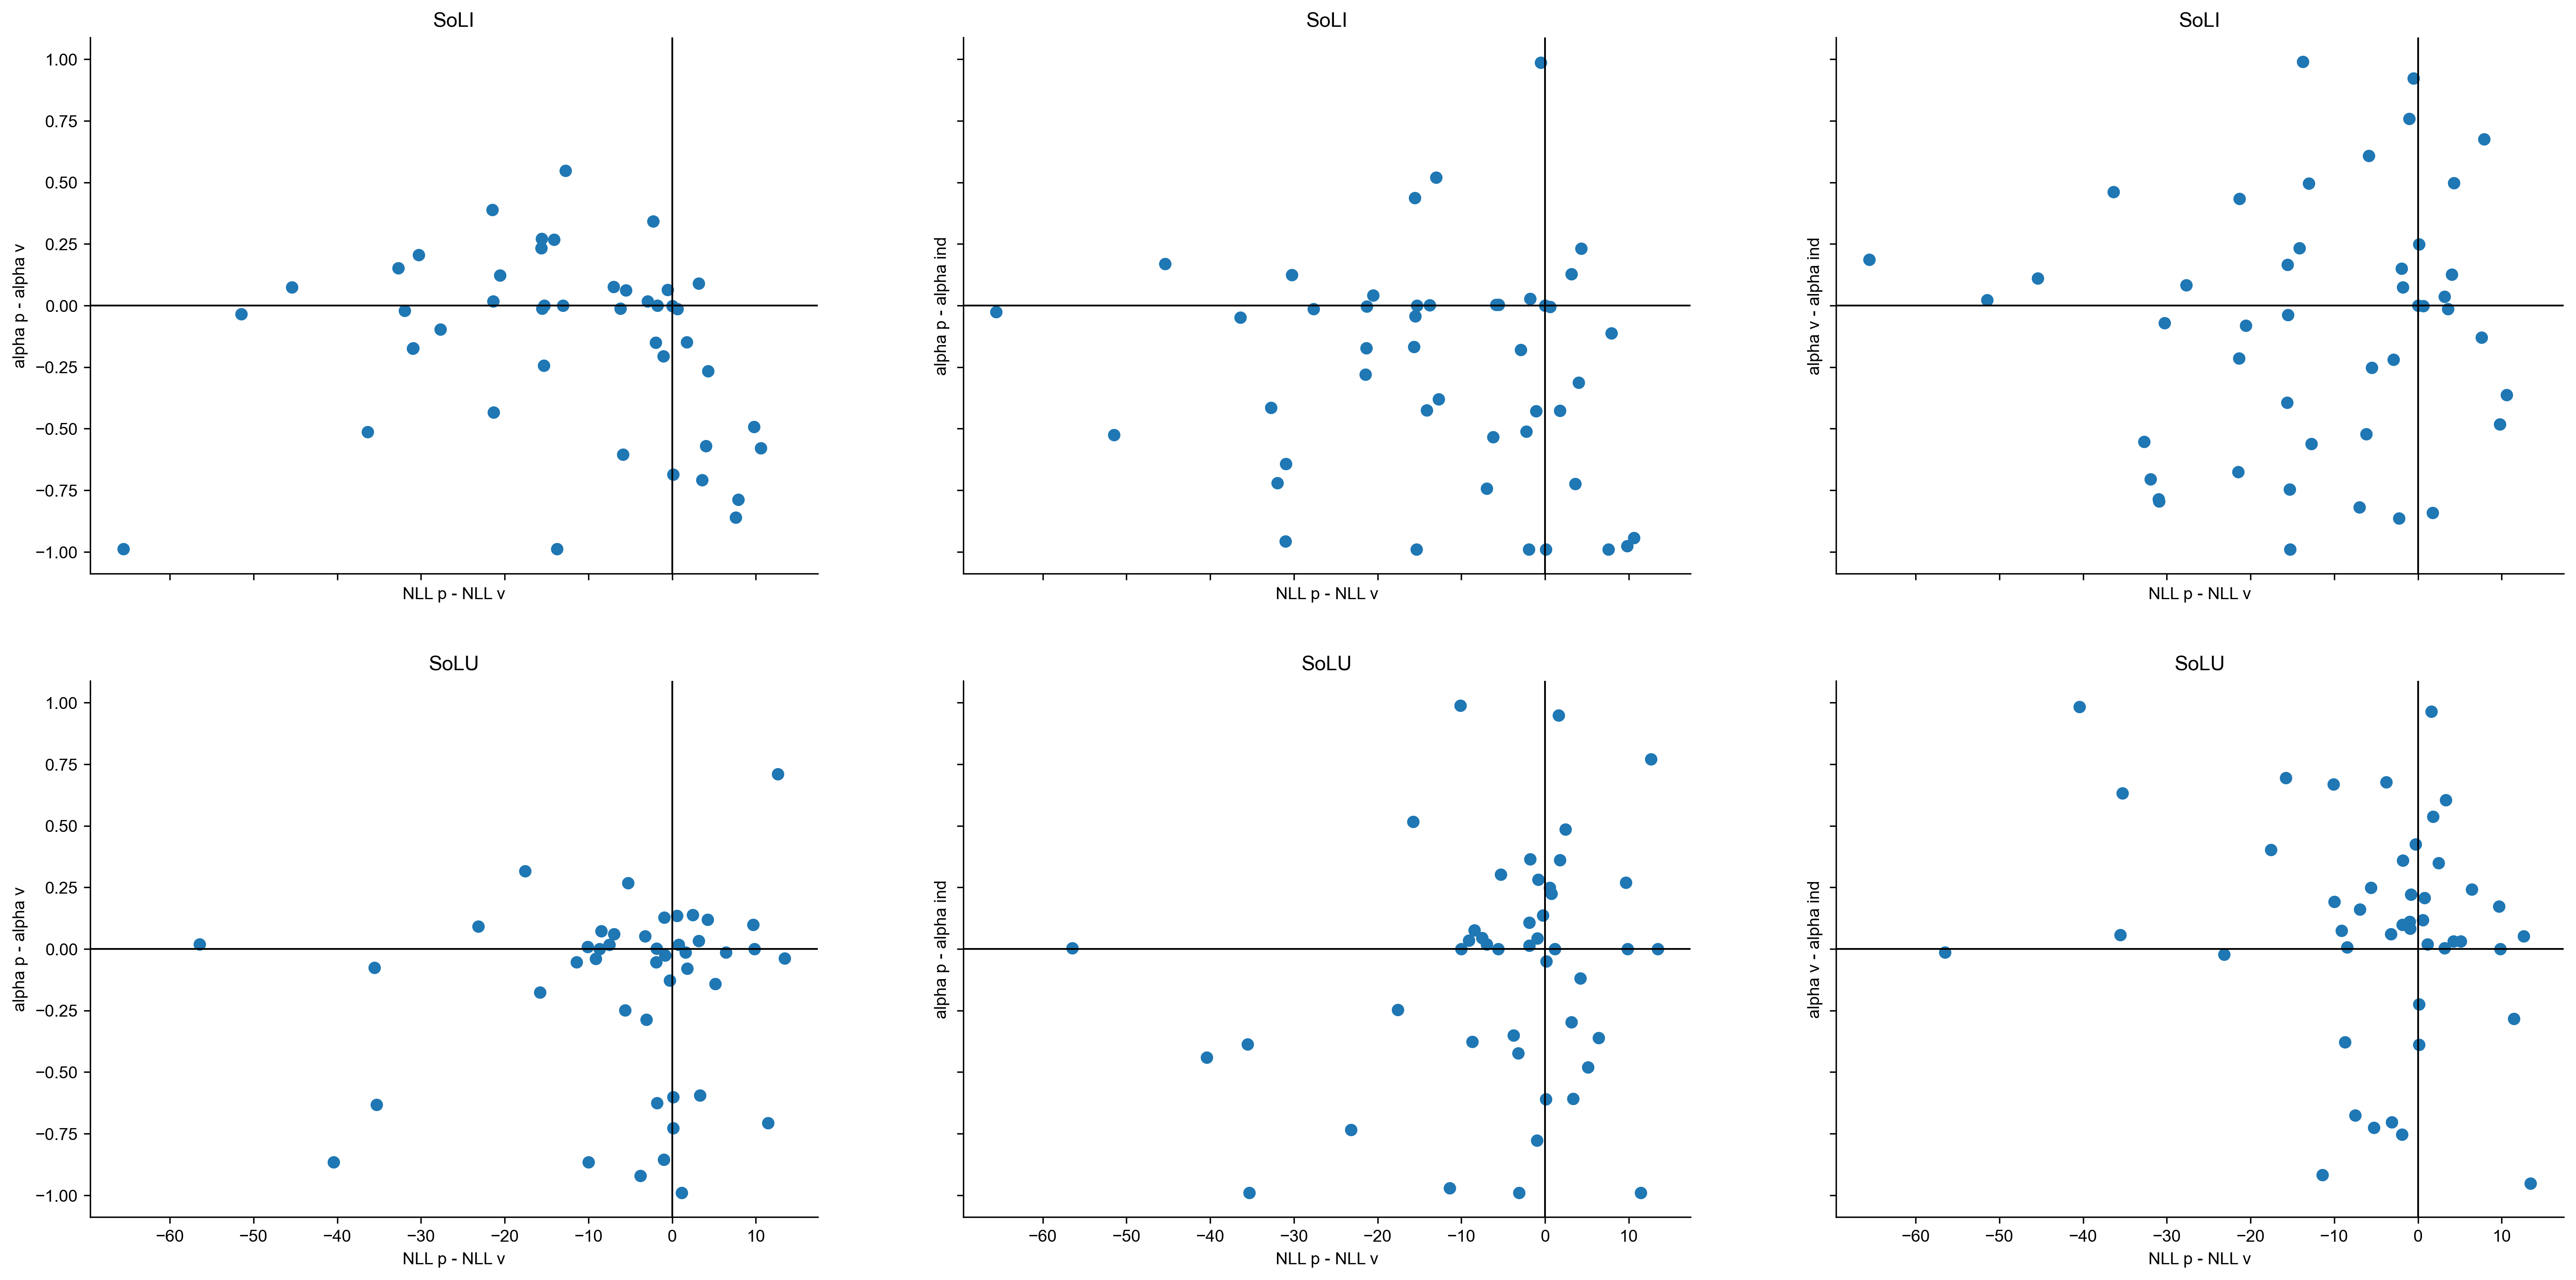

In [52]:
fig, axs = plt.subplots(2, 3, figsize=(25, 12), sharex=True, sharey=True)

# fig.suptitle('Correlations of alphas and betas for the SoLI group')

axs[0, 0].scatter(soli_sorted_diff_nll, soli_pv_diff_alpha)
axs[0, 0].set_xlabel('NLL p - NLL v')
axs[0, 0].set_ylabel('alpha p - alpha v')
axs[0, 0].axhline(0, color='black', linewidth=1)
axs[0, 0].axvline(0, color='black', linewidth=1)
axs[0, 0].set_title('SoLI')

axs[0, 1].scatter(soli_sorted_diff_nll, soli_pi_diff_alpha)
axs[0, 1].set_xlabel('NLL p - NLL v')
axs[0, 1].set_ylabel('alpha p - alpha ind')
axs[0, 1].axhline(0, color='black', linewidth=1)
axs[0, 1].axvline(0, color='black', linewidth=1)
axs[0, 1].set_title('SoLI')

axs[0, 2].scatter(soli_sorted_diff_nll, soli_vi_diff_alpha)
axs[0, 2].set_xlabel('NLL p - NLL v')
axs[0, 2].set_ylabel('alpha v - alpha ind')
axs[0, 2].axhline(0, color='black', linewidth=1)
axs[0, 2].axvline(0, color='black', linewidth=1)
axs[0, 2].set_title('SoLI')


axs[1, 0].scatter(solu_sorted_diff_nll, solu_pv_diff_alpha)
axs[1, 0].set_xlabel('NLL p - NLL v')
axs[1, 0].set_ylabel('alpha p - alpha v')
axs[1, 0].axhline(0, color='black', linewidth=1)
axs[1, 0].axvline(0, color='black', linewidth=1)
axs[1, 0].set_title('SoLU')

axs[1, 1].scatter(solu_sorted_diff_nll, solu_pi_diff_alpha)
axs[1, 1].set_xlabel('NLL p - NLL v')
axs[1, 1].set_ylabel('alpha p - alpha ind')
axs[1, 1].axhline(0, color='black', linewidth=1)
axs[1, 1].axvline(0, color='black', linewidth=1)
axs[1, 1].set_title('SoLU')

axs[1, 2].scatter(solu_sorted_diff_nll, solu_vi_diff_alpha)
axs[1, 2].set_xlabel('NLL p - NLL v')
axs[1, 2].set_ylabel('alpha v - alpha ind')
axs[1, 2].axhline(0, color='black', linewidth=1)
axs[1, 2].axvline(0, color='black', linewidth=1)
axs[1, 2].set_title('SoLU');





Text(0.5, 1.0, 'SoLU')

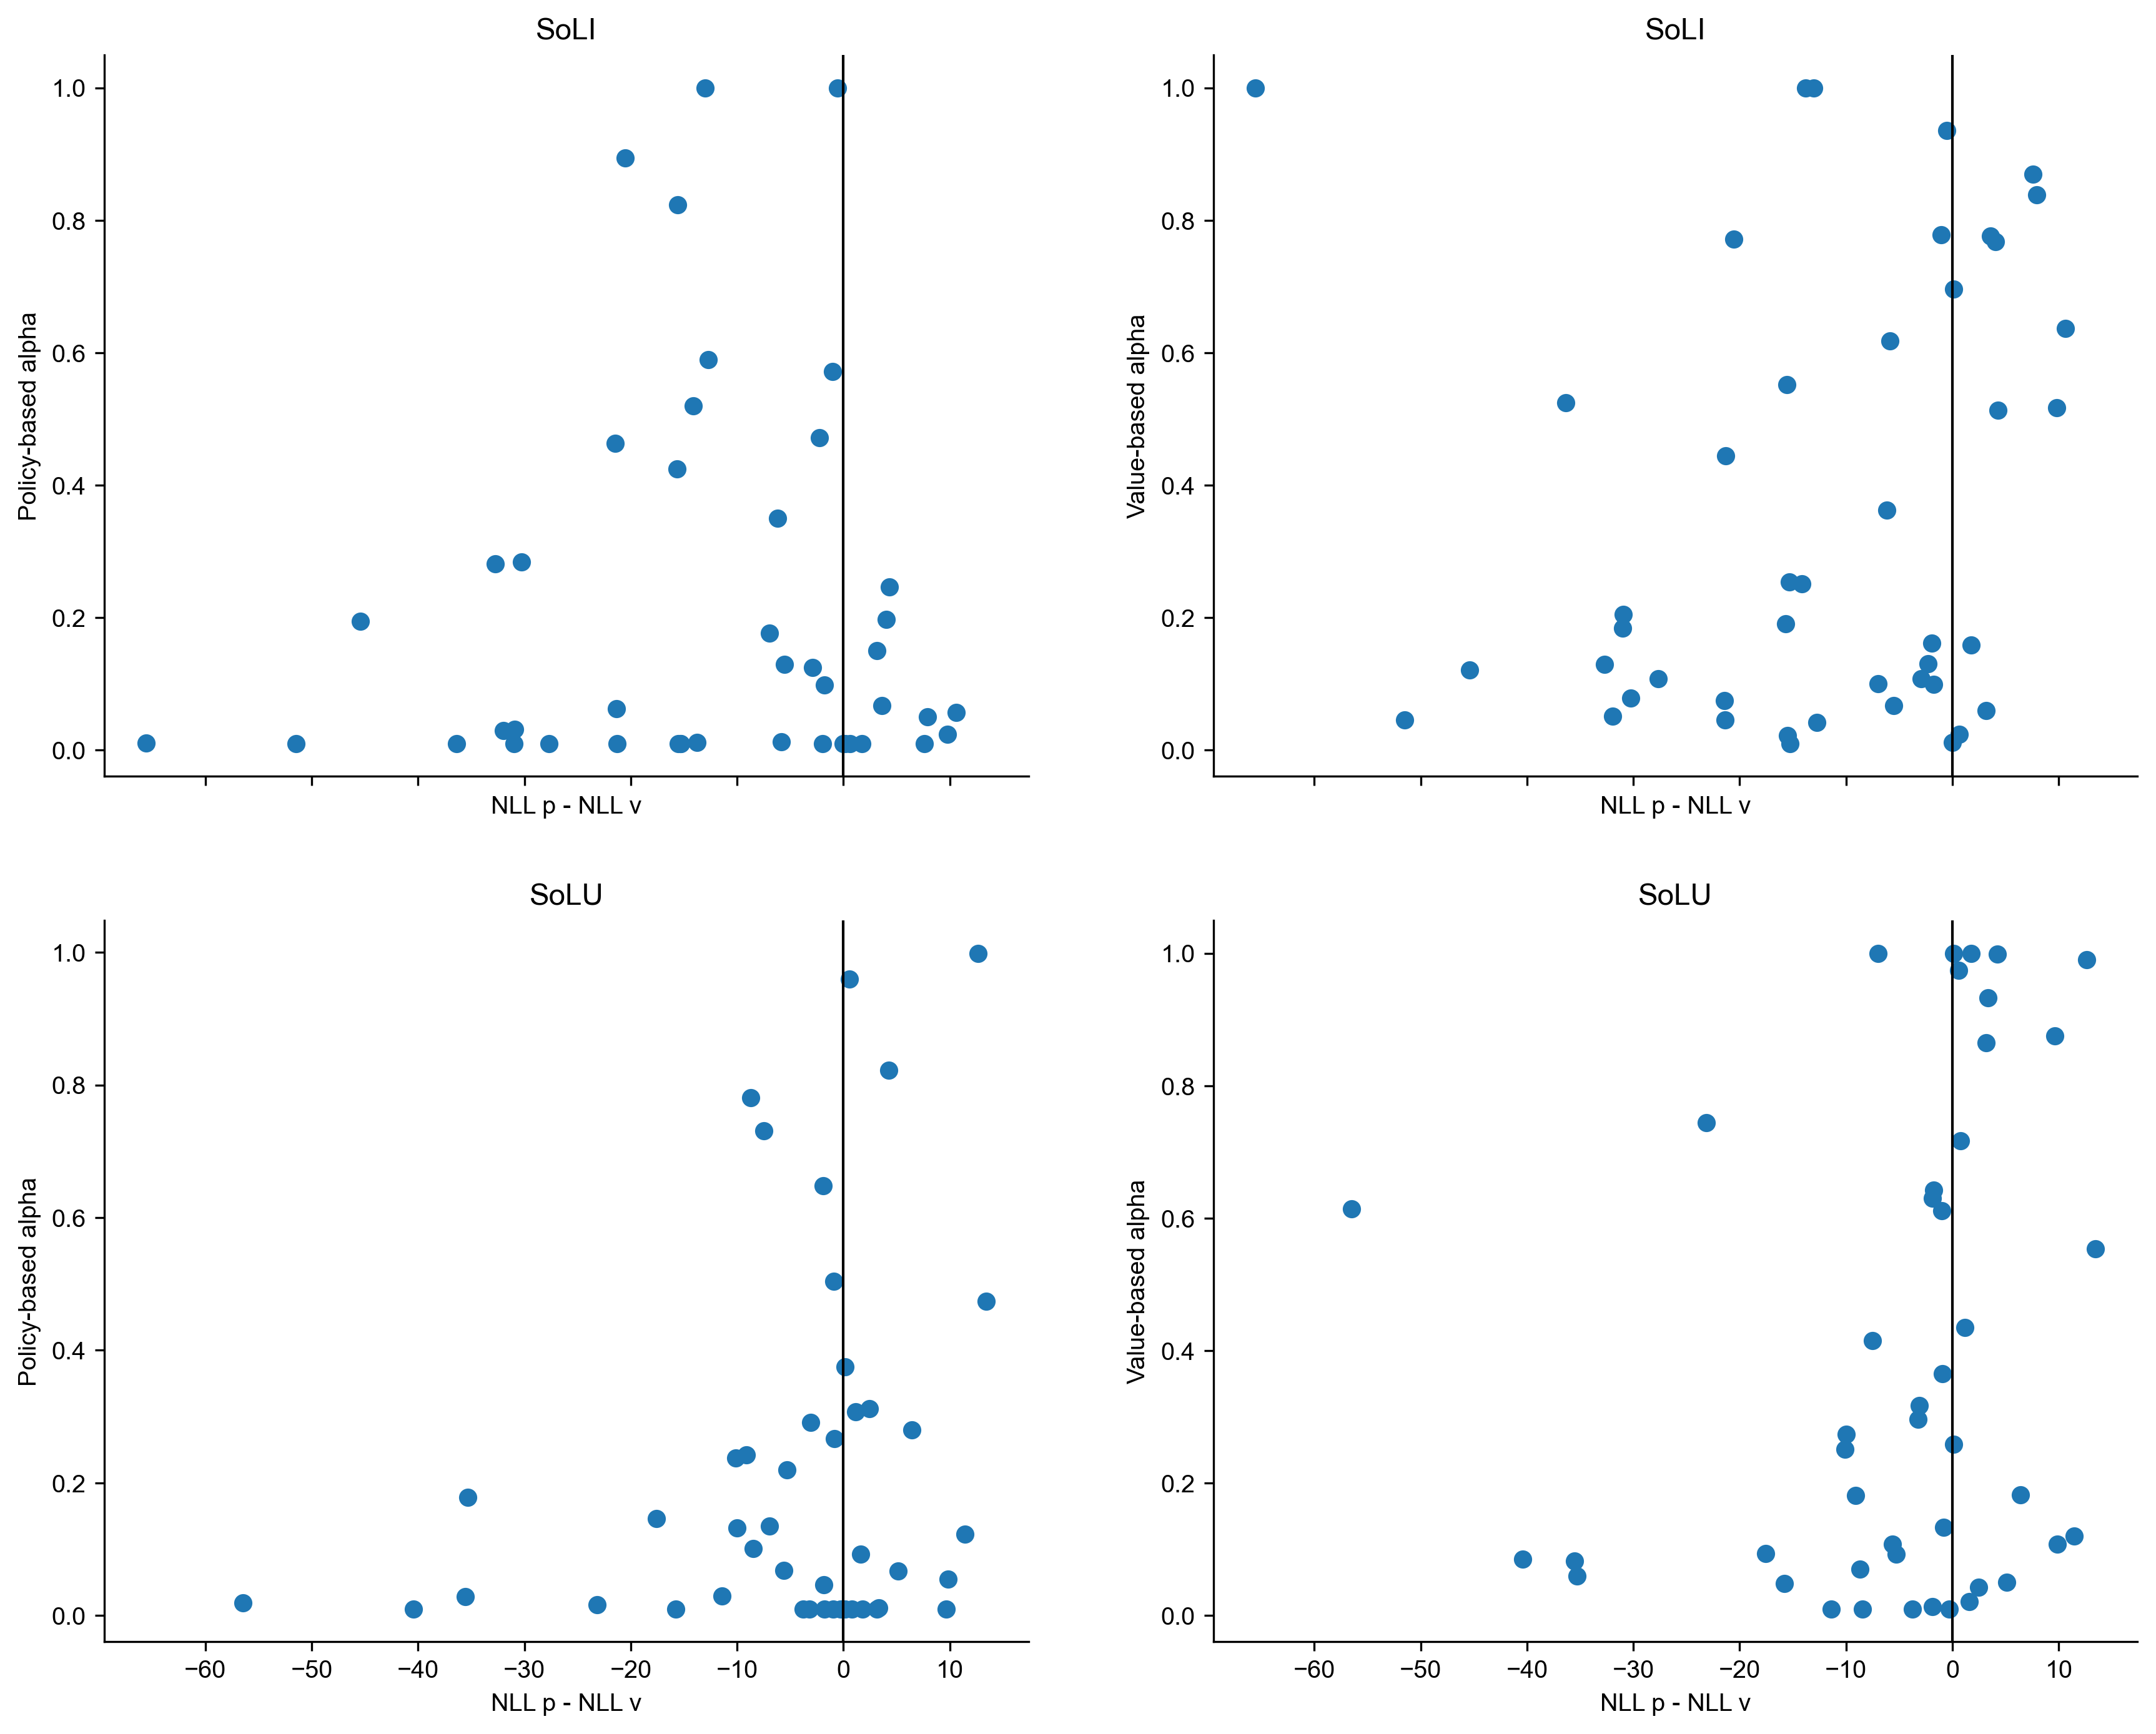

In [53]:
fig, axs = plt.subplots(2, 2, figsize=(14, 11), sharex=True)


# soli_tv_alpha[soli_diff_idx] - soli_cv_alpha[soli_diff_idx]


axs[0, 0].scatter(soli_sorted_diff_nll, soli_tv_alpha[soli_diff_idx])
axs[0, 0].axvline(0, color='black', linewidth=1)
axs[0, 0].set_xlabel('NLL p - NLL v')
axs[0, 0].set_ylabel('Policy-based alpha')
axs[0, 0].set_title('SoLI')

axs[0, 1].scatter(soli_sorted_diff_nll, soli_cv_alpha[soli_diff_idx])
axs[0, 1].axvline(0, color='black', linewidth=1)
axs[0, 1].set_xlabel('NLL p - NLL v')
axs[0, 1].set_ylabel('Value-based alpha')
axs[0, 1].set_title('SoLI')


axs[1, 0].scatter(solu_sorted_diff_nll, solu_tv_alpha[solu_diff_idx])
axs[1, 0].axvline(0, color='black', linewidth=1)
axs[1, 0].set_xlabel('NLL p - NLL v')
axs[1, 0].set_ylabel('Policy-based alpha')
axs[1, 0].set_title('SoLU')

axs[1, 1].scatter(solu_sorted_diff_nll, solu_cv_alpha[solu_diff_idx])
axs[1, 1].axvline(0, color='black', linewidth=1)
axs[1, 1].set_xlabel('NLL p - NLL v')
axs[1, 1].set_ylabel('Value-based alpha')
axs[1, 1].set_title('SoLU')

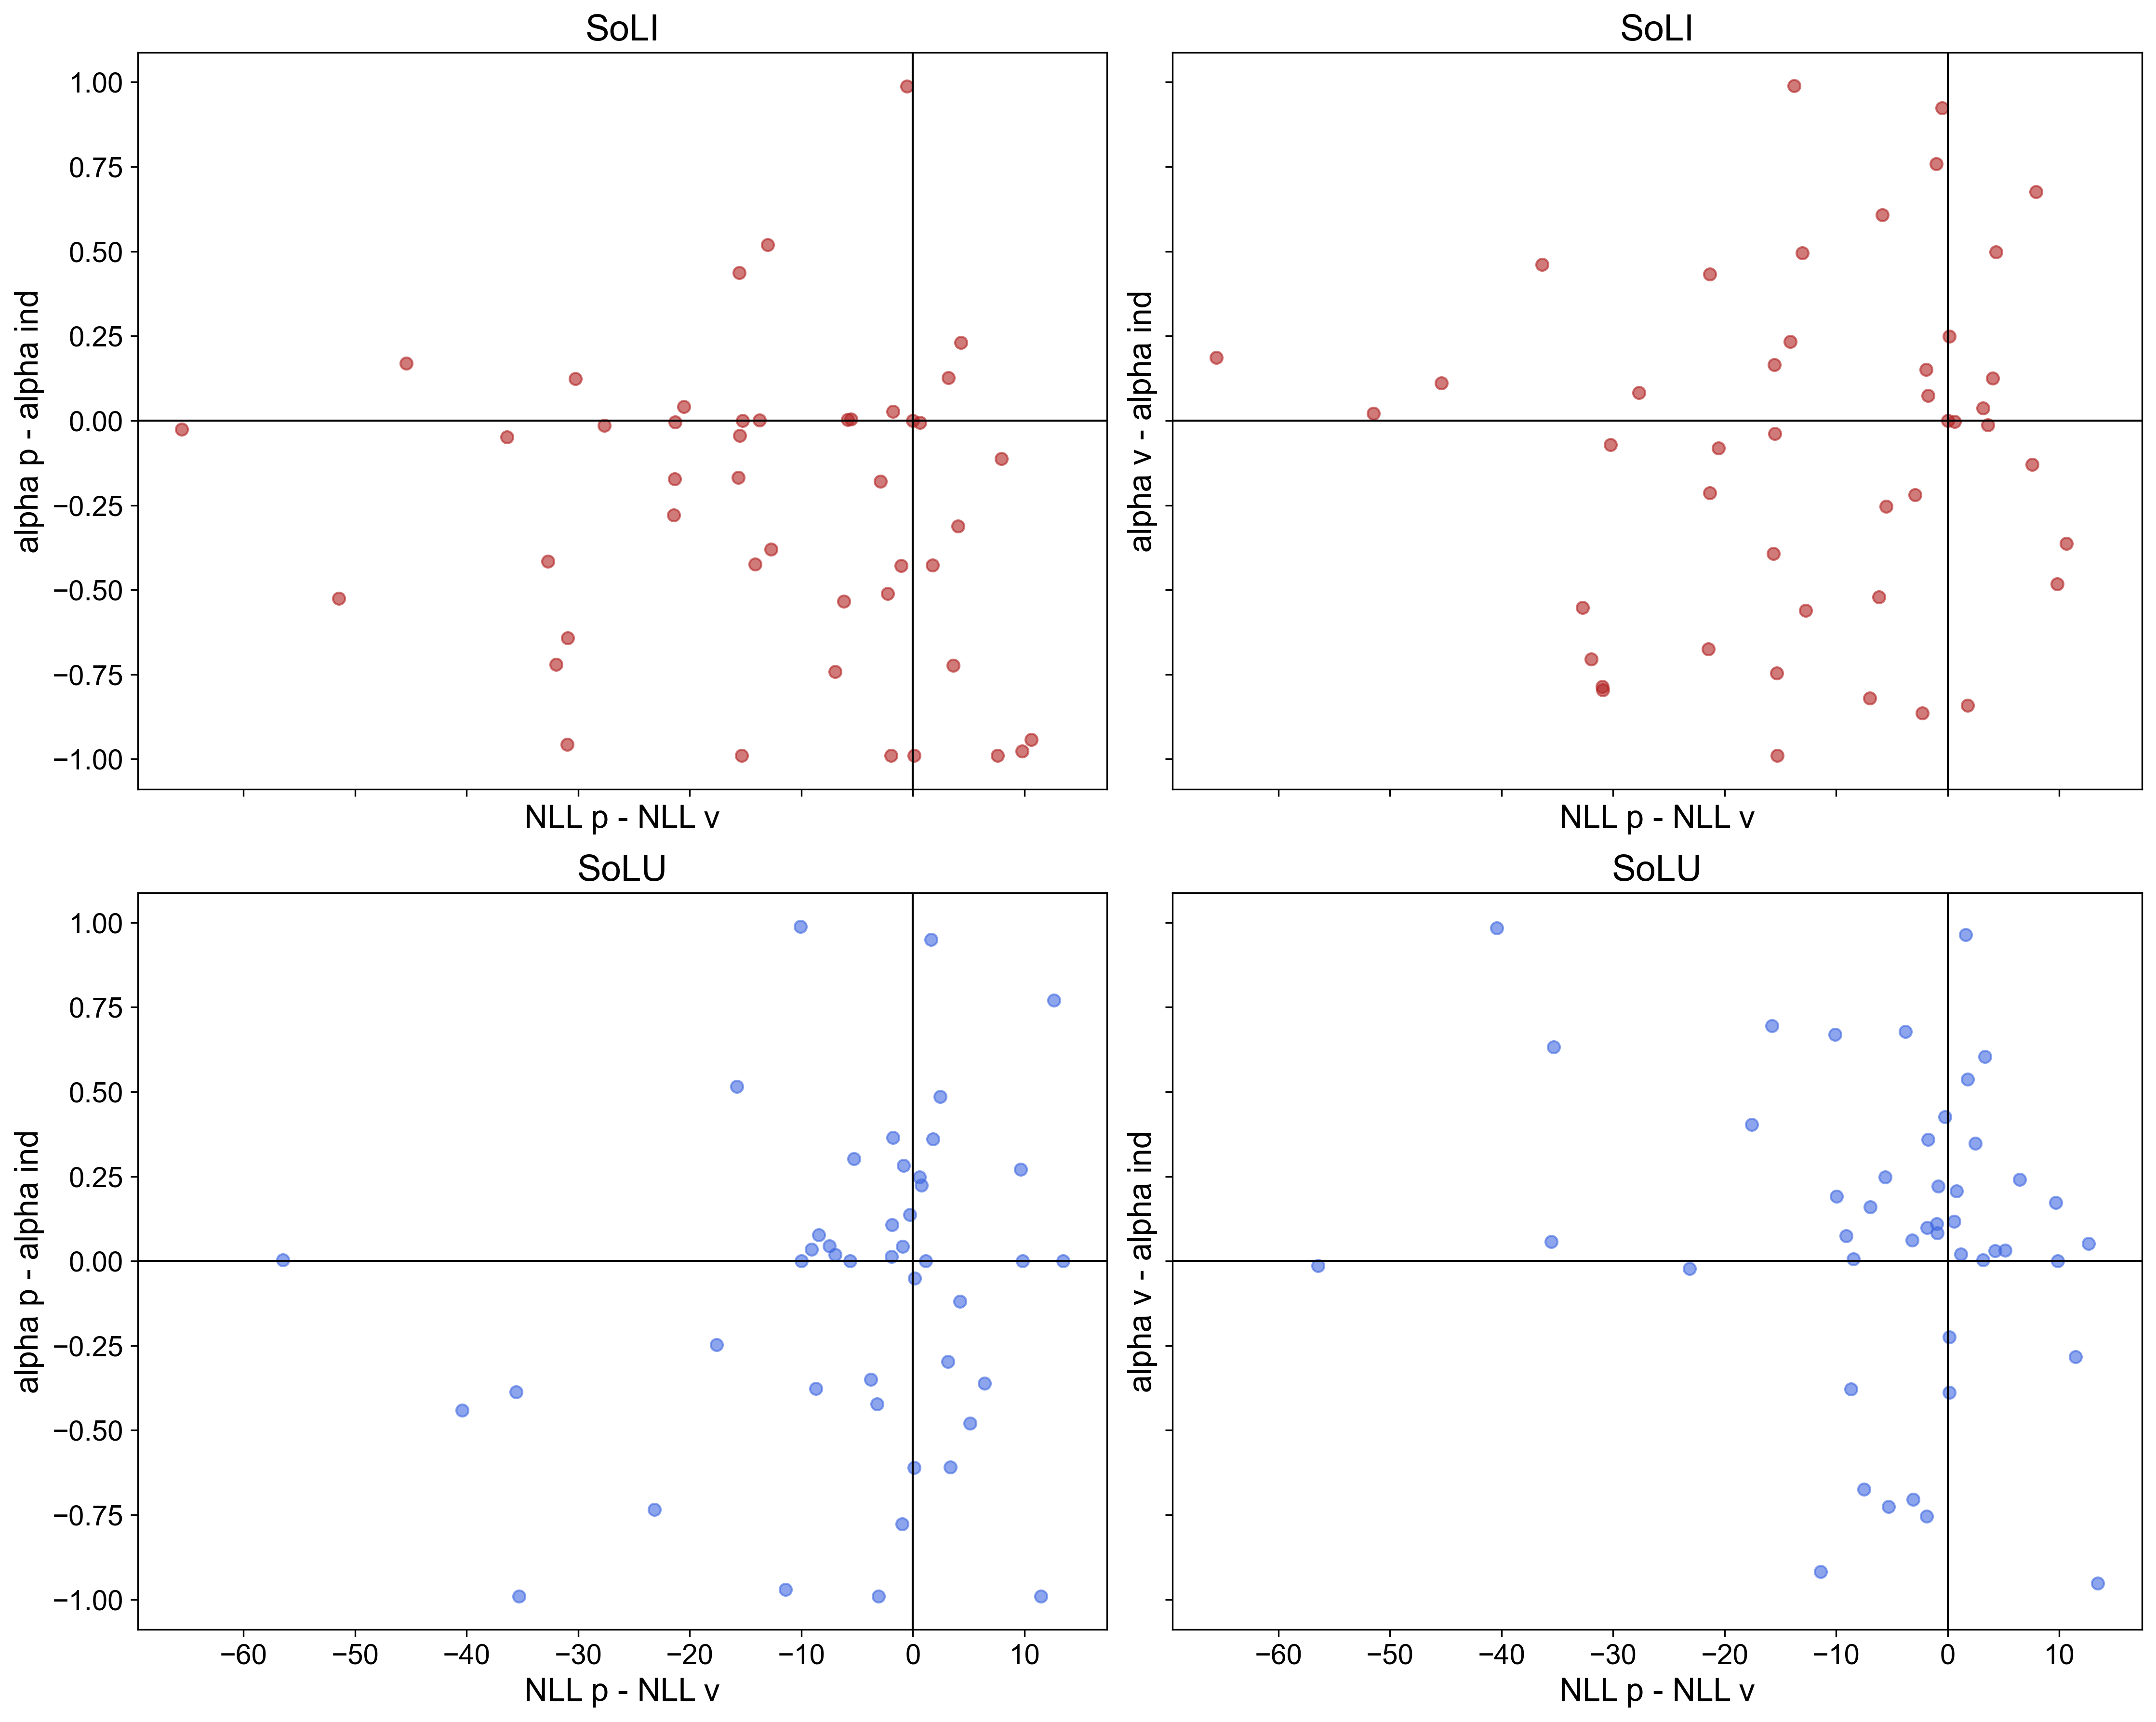

In [54]:
fig, axs = plt.subplots(2, 2, figsize=(15, 12), sharex=True, sharey=True)

label_fs = 16   # axis labels
title_fs = 18   # subplot titles
tick_fs = 14    # tick labels

# top-left (firebrick)
axs[0, 0].scatter(soli_sorted_diff_nll, soli_pi_diff_alpha,
                  color='firebrick', alpha=0.6)
axs[0, 0].set_xlabel('NLL p - NLL v', fontsize=label_fs)
axs[0, 0].set_ylabel('alpha p - alpha ind', fontsize=label_fs)
axs[0, 0].axhline(0, color='black', linewidth=1)
axs[0, 0].axvline(0, color='black', linewidth=1)
axs[0, 0].set_title('SoLI', fontsize=title_fs)

# top-right (firebrick)
axs[0, 1].scatter(soli_sorted_diff_nll, soli_vi_diff_alpha,
                  color='firebrick', alpha=0.6)
axs[0, 1].set_xlabel('NLL p - NLL v', fontsize=label_fs)
axs[0, 1].set_ylabel('alpha v - alpha ind', fontsize=label_fs)
axs[0, 1].axhline(0, color='black', linewidth=1)
axs[0, 1].axvline(0, color='black', linewidth=1)
axs[0, 1].set_title('SoLI', fontsize=title_fs)

# bottom-left (royalblue)
axs[1, 0].scatter(solu_sorted_diff_nll, solu_pi_diff_alpha,
                  color='royalblue', alpha=0.6)
axs[1, 0].set_xlabel('NLL p - NLL v', fontsize=label_fs)
axs[1, 0].set_ylabel('alpha p - alpha ind', fontsize=label_fs)
axs[1, 0].axhline(0, color='black', linewidth=1)
axs[1, 0].axvline(0, color='black', linewidth=1)
axs[1, 0].set_title('SoLU', fontsize=title_fs)

# bottom-right (royalblue)
axs[1, 1].scatter(solu_sorted_diff_nll, solu_vi_diff_alpha,
                  color='royalblue', alpha=0.6)
axs[1, 1].set_xlabel('NLL p - NLL v', fontsize=label_fs)
axs[1, 1].set_ylabel('alpha v - alpha ind', fontsize=label_fs)
axs[1, 1].axhline(0, color='black', linewidth=1)
axs[1, 1].axvline(0, color='black', linewidth=1)
axs[1, 1].set_title('SoLU', fontsize=title_fs)

# shared styling
for ax_row in axs:
    for ax in ax_row:
        ax.spines['top'].set_visible(True)
        ax.spines['right'].set_visible(True)
        ax.spines['left'].set_visible(True)
        ax.spines['bottom'].set_visible(True)
        ax.tick_params(axis='both', which='major', labelsize=tick_fs)

plt.tight_layout()


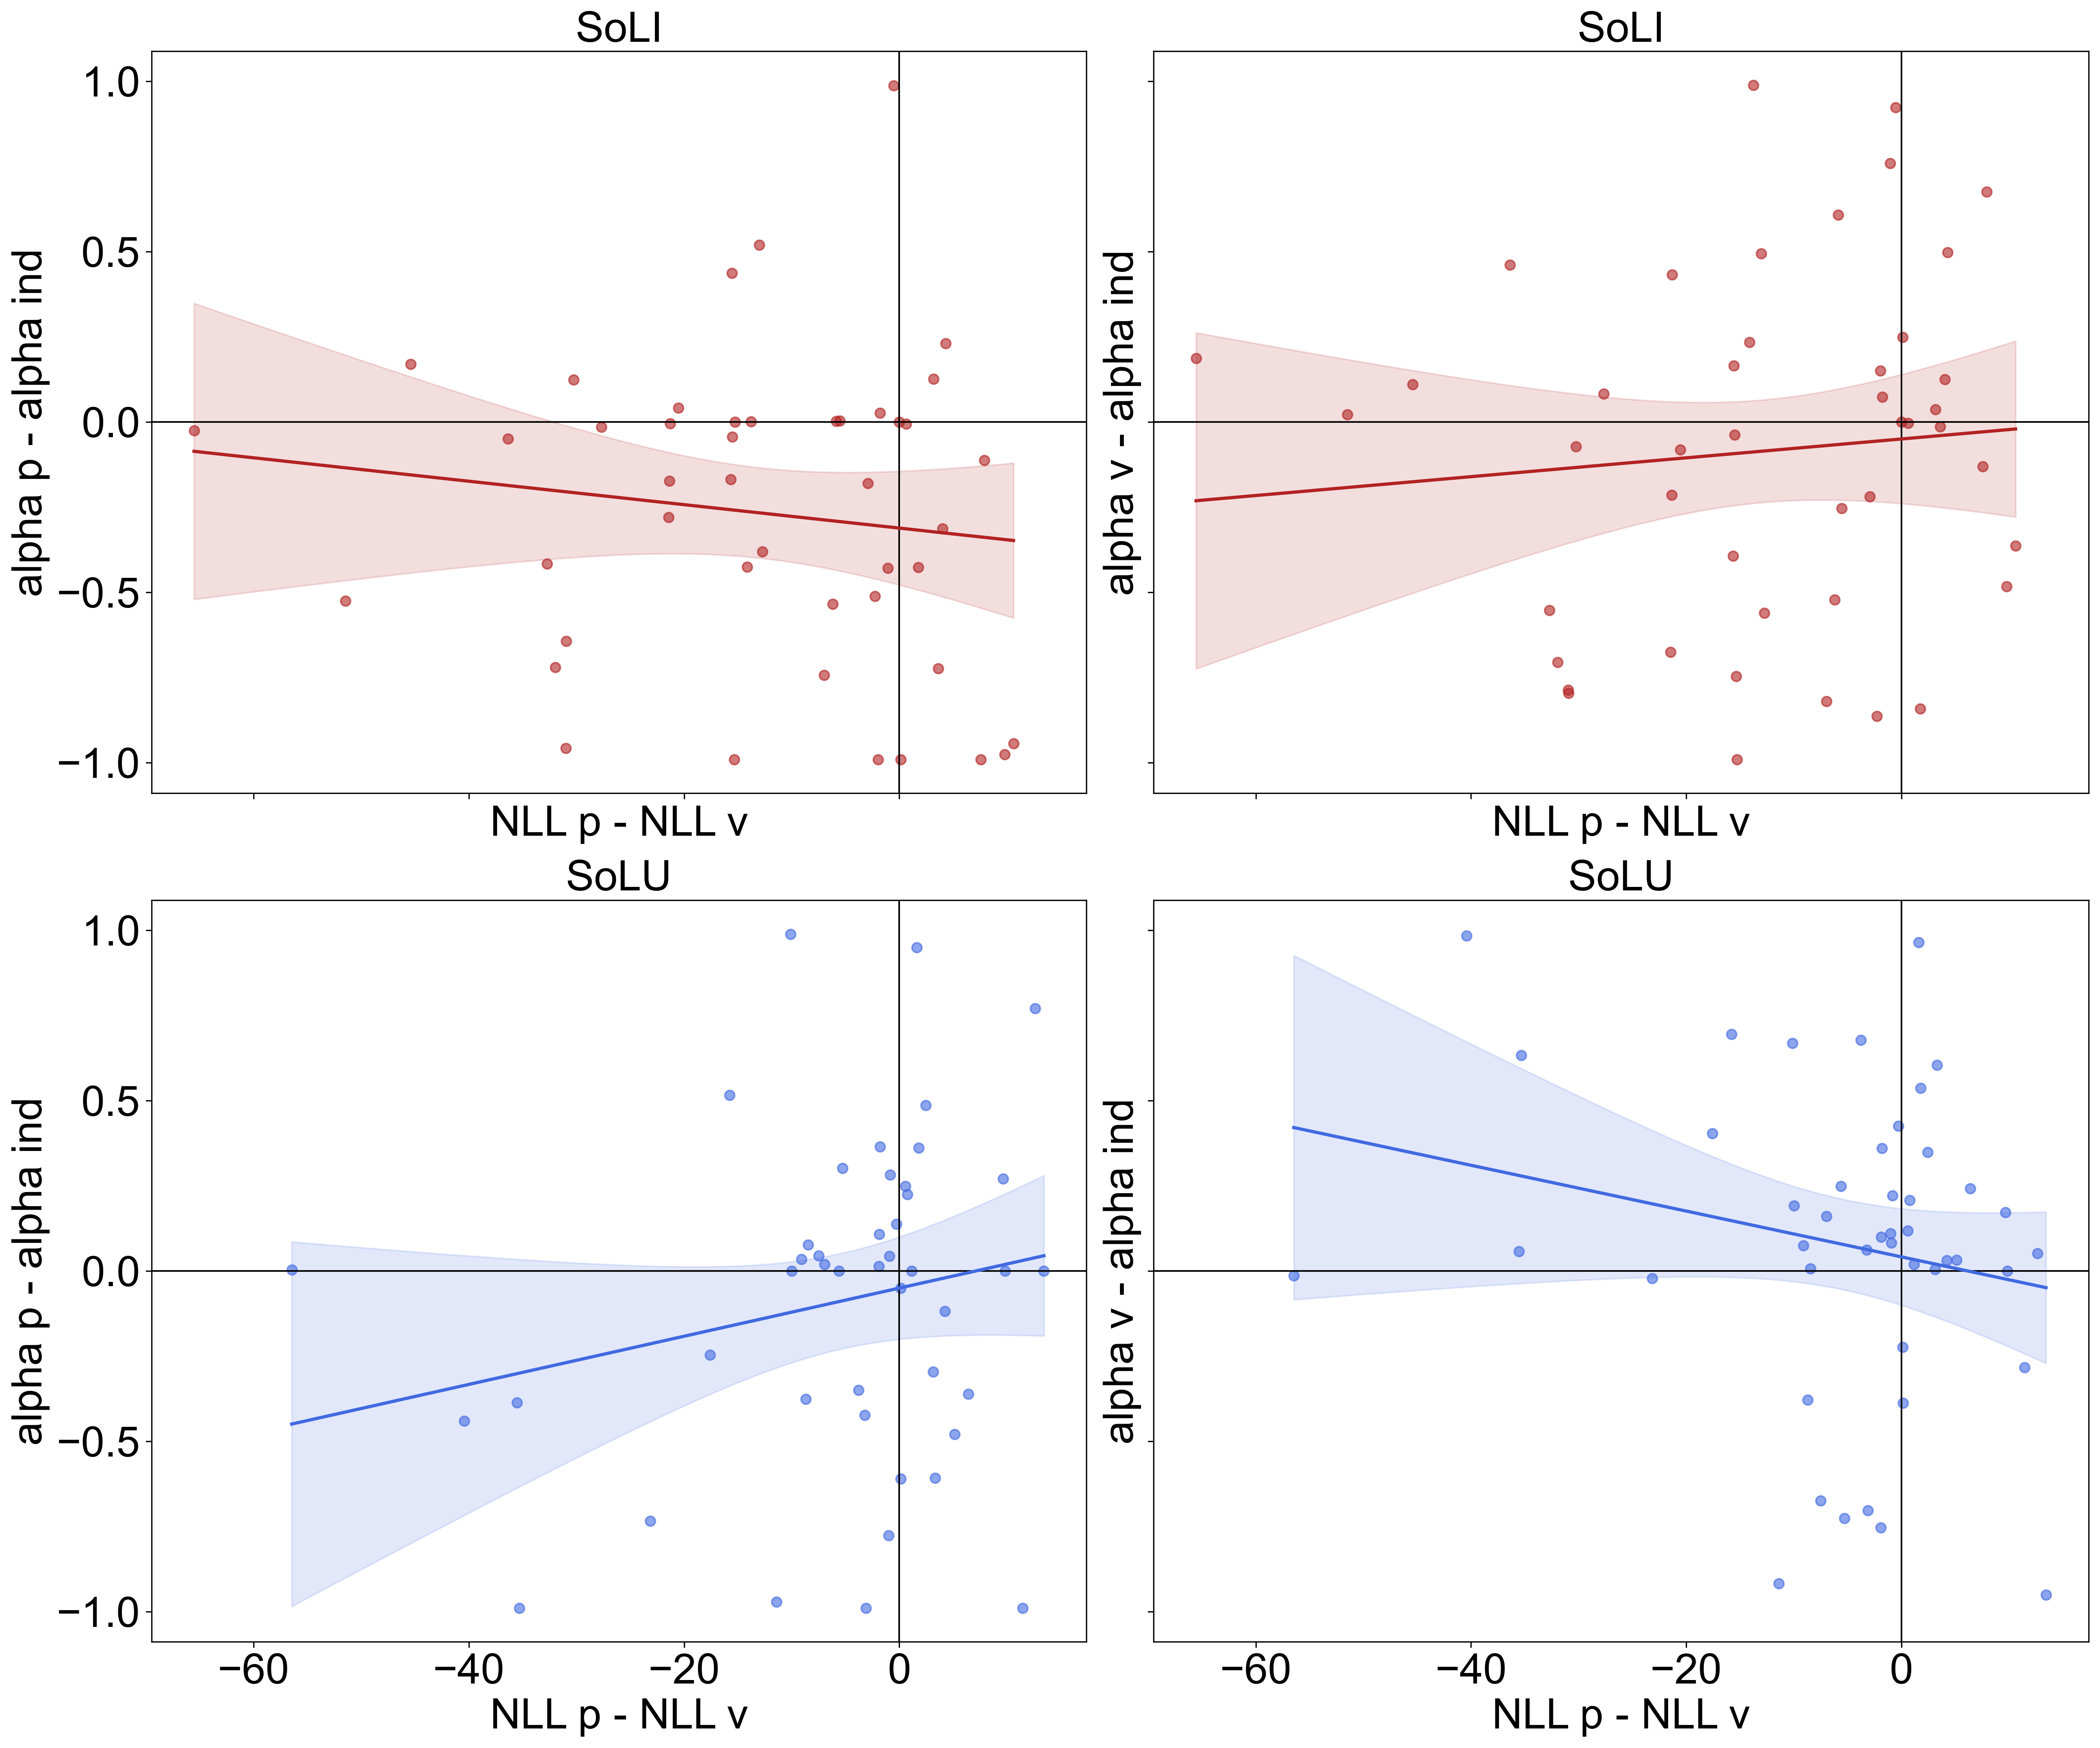

In [55]:
import numpy as np
import matplotlib.pyplot as plt

def add_regression_with_ci(ax, x, y, line_color, ci_alpha=0.15):
    x = np.asarray(x)
    y = np.asarray(y)

    # remove NaNs if any
    mask = ~np.isnan(x) & ~np.isnan(y)
    x = x[mask]
    y = y[mask]

    n = len(x)
    if n < 3:
        return  # not enough points to fit

    # linear regression (least squares)
    x_mean = x.mean()
    y_mean = y.mean()
    Sxx = np.sum((x - x_mean)**2)
    Sxy = np.sum((x - x_mean) * (y - y_mean))
    b1 = Sxy / Sxx
    b0 = y_mean - b1 * x_mean

    # x grid for plotting
    x_fit = np.linspace(x.min(), x.max(), 200)
    y_fit = b0 + b1 * x_fit

    # standard error of estimate
    y_pred = b0 + b1 * x
    s_err = np.sqrt(np.sum((y - y_pred)**2) / (n - 2))

    # 95% CI for mean prediction
    # t ~ 1.96 for large n
    t_val = 1.96
    ci = t_val * s_err * np.sqrt(1/n + (x_fit - x_mean)**2 / Sxx)

    ax.plot(x_fit, y_fit, color=line_color, linewidth=2)
    ax.fill_between(x_fit, y_fit - ci, y_fit + ci,
                    color=line_color, alpha=ci_alpha)


fig, axs = plt.subplots(2, 2, figsize=(18, 15), sharex=True, sharey=True)

label_fs = 26   # axis labels
title_fs = 26   # subplot titles
tick_fs = 26    # tick labels

# top-left (firebrick)
axs[0, 0].scatter(soli_sorted_diff_nll, soli_pi_diff_alpha,
                  color='firebrick', alpha=0.6)
axs[0, 0].set_xlabel('NLL p - NLL v', fontsize=label_fs)
axs[0, 0].set_ylabel('alpha p - alpha ind', fontsize=label_fs)
axs[0, 0].axhline(0, color='black', linewidth=1)
axs[0, 0].axvline(0, color='black', linewidth=1)
axs[0, 0].set_title('SoLI', fontsize=title_fs)
add_regression_with_ci(axs[0, 0],
                       soli_sorted_diff_nll,
                       soli_pi_diff_alpha,
                       line_color='firebrick')

# top-right (firebrick)
axs[0, 1].scatter(soli_sorted_diff_nll, soli_vi_diff_alpha,
                  color='firebrick', alpha=0.6)
axs[0, 1].set_xlabel('NLL p - NLL v', fontsize=label_fs)
axs[0, 1].set_ylabel('alpha v - alpha ind', fontsize=label_fs)
axs[0, 1].axhline(0, color='black', linewidth=1)
axs[0, 1].axvline(0, color='black', linewidth=1)
axs[0, 1].set_title('SoLI', fontsize=title_fs)
add_regression_with_ci(axs[0, 1],
                       soli_sorted_diff_nll,
                       soli_vi_diff_alpha,
                       line_color='firebrick')

# bottom-left (royalblue)
axs[1, 0].scatter(solu_sorted_diff_nll, solu_pi_diff_alpha,
                  color='royalblue', alpha=0.6)
axs[1, 0].set_xlabel('NLL p - NLL v', fontsize=label_fs)
axs[1, 0].set_ylabel('alpha p - alpha ind', fontsize=label_fs)
axs[1, 0].axhline(0, color='black', linewidth=1)
axs[1, 0].axvline(0, color='black', linewidth=1)
axs[1, 0].set_title('SoLU', fontsize=title_fs)
add_regression_with_ci(axs[1, 0],
                       solu_sorted_diff_nll,
                       solu_pi_diff_alpha,
                       line_color='royalblue')

# bottom-right (royalblue)
axs[1, 1].scatter(solu_sorted_diff_nll, solu_vi_diff_alpha,
                  color='royalblue', alpha=0.6)
axs[1, 1].set_xlabel('NLL p - NLL v', fontsize=label_fs)
axs[1, 1].set_ylabel('alpha v - alpha ind', fontsize=label_fs)
axs[1, 1].axhline(0, color='black', linewidth=1)
axs[1, 1].axvline(0, color='black', linewidth=1)
axs[1, 1].set_title('SoLU', fontsize=title_fs)
add_regression_with_ci(axs[1, 1],
                       solu_sorted_diff_nll,
                       solu_vi_diff_alpha,
                       line_color='royalblue')

# shared styling
for ax_row in axs:
    for ax in ax_row:
        ax.spines['top'].set_visible(True)
        ax.spines['right'].set_visible(True)
        ax.spines['left'].set_visible(True)
        ax.spines['bottom'].set_visible(True)
        ax.tick_params(axis='both', which='major', labelsize=tick_fs)

plt.tight_layout()
fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/main/paper draft/Figures/RLdifffinal.svg',  bbox_inches='tight', pad_inches=0.02)

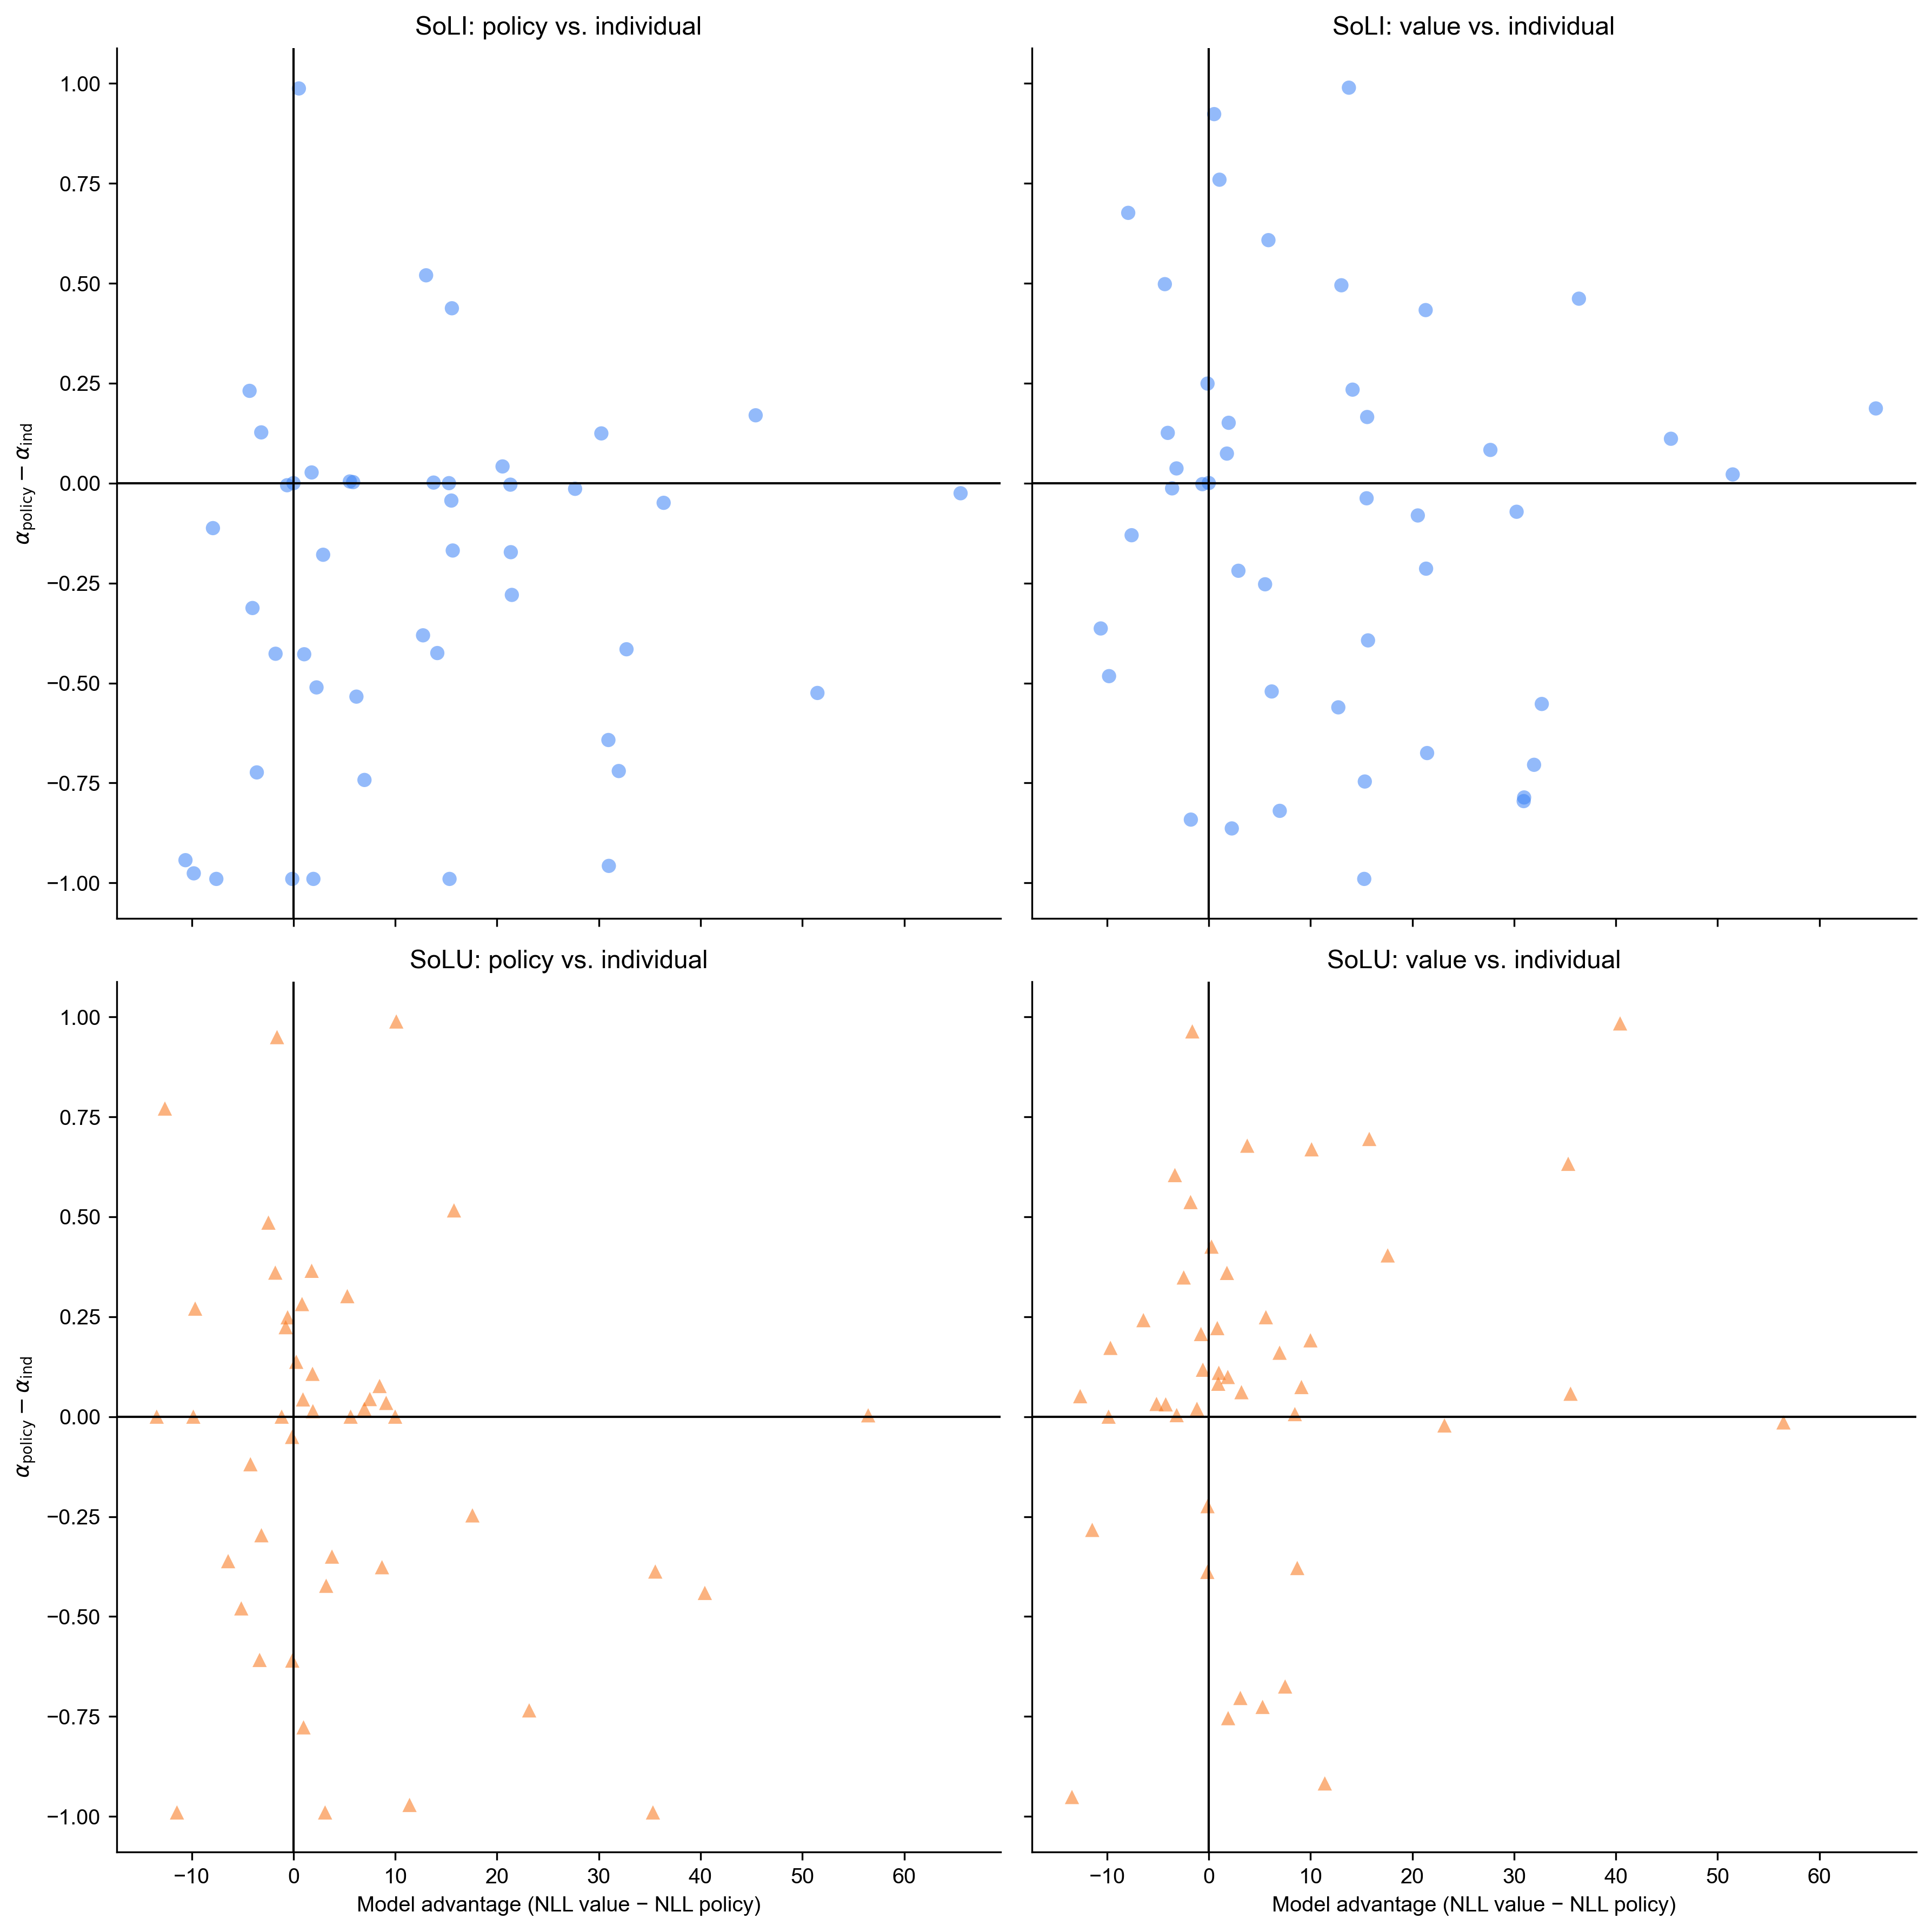

In [56]:
import numpy as np
import matplotlib.pyplot as plt

fig, axs = plt.subplots(2, 2, figsize=(12, 12), sharex=True, sharey=True)

# make "positive = policy better"
# original was (NLL_p - NLL_v); flip sign:
soli_policy_adv = -1 * soli_sorted_diff_nll      # SoLI
solu_policy_adv = -1 * solu_sorted_diff_nll      # SoLU

# SoLI, policy α – individual α
axs[0, 0].scatter(
    soli_policy_adv,
    soli_pi_diff_alpha,
    s=40,
    alpha=0.55,
    color='#3b82f6',   # blue
    edgecolor='none',
    marker='o'
)
axs[0, 0].axhline(0, color='black', linewidth=1)
axs[0, 0].axvline(0, color='black', linewidth=1)
axs[0, 0].set_ylabel(r'$\alpha_{\mathrm{policy}} - \alpha_{\mathrm{ind}}$')
axs[0, 0].set_title('SoLI: policy vs. individual')

# SoLI, value α – individual α
axs[0, 1].scatter(
    soli_policy_adv,
    soli_vi_diff_alpha,
    s=40,
    alpha=0.55,
    color='#3b82f6',
    edgecolor='none',
    marker='o'
)
axs[0, 1].axhline(0, color='black', linewidth=1)
axs[0, 1].axvline(0, color='black', linewidth=1)
axs[0, 1].set_title('SoLI: value vs. individual')

# SoLU, policy α – individual α
axs[1, 0].scatter(
    solu_policy_adv,
    solu_pi_diff_alpha,
    s=40,
    alpha=0.55,
    color='#f97316',   # orange
    edgecolor='none',
    marker='^'
)
axs[1, 0].axhline(0, color='black', linewidth=1)
axs[1, 0].axvline(0, color='black', linewidth=1)
axs[1, 0].set_ylabel(r'$\alpha_{\mathrm{policy}} - \alpha_{\mathrm{ind}}$')
axs[1, 0].set_title('SoLU: policy vs. individual')

# SoLU, value α – individual α
axs[1, 1].scatter(
    solu_policy_adv,
    solu_vi_diff_alpha,
    s=40,
    alpha=0.55,
    color='#f97316',
    edgecolor='none',
    marker='^'
)
axs[1, 1].axhline(0, color='black', linewidth=1)
axs[1, 1].axvline(0, color='black', linewidth=1)
axs[1, 1].set_title('SoLU: value vs. individual')

# shared x-label for bottom row
for ax in axs[1, :]:
    ax.set_xlabel('Model advantage (NLL value − NLL policy)')

plt.tight_layout()



## Model Recovery Analysis — Validation of Model Distinguishability

In [57]:
import ast
import numpy as np
import pandas as pd
import scipy
import matplotlib.pyplot as plt

from scipy.optimize import minimize
from scipy.special import softmax
from pathlib import Path
from IPython.display import display

# Original fitting bounds
RECOVERY_BOUNDS_4 = (
    (0.01, 1.0),
    (0.01, 50.0),
    (0.01, 1.0),
    (0.01, 50.0)
)

RECOVERY_BOUNDS_7 = RECOVERY_BOUNDS_4 + (
    (-1.0, 1.0),
    (-1.0, 1.0),
    (-1.0, 1.0)
)


def get_probabilities(frame):
    """Return the actual card probabilities on each trial."""
    return np.stack([
        np.asarray(
            ast.literal_eval(s) if isinstance(s, str) else s,
            dtype=float
        )
        for s in frame['card probs'].iloc[:105]
    ])


def social_observation_impact(t, ag_choice, chosen_agent, gammas):
    """Social impact matching the original RL likelihoods."""

    impact = np.zeros(4, dtype=float)

    if t < 15 or t % 3 != 0:
        return impact

    if 15 <= t < 45:

        choices = (
            ast.literal_eval(ag_choice)
            if isinstance(ag_choice, str)
            else ag_choice
        )

        for j, c in enumerate(choices):
            impact[int(c)] += gammas[j]

    elif t >= 45 and chosen_agent in ('A', 'B', 'C'):

        agent_index = {
            'A': 0,
            'B': 1,
            'C': 2
        }[chosen_agent]

        try:
            c = int(ag_choice)

            if 0 <= c < 4:
                impact[c] += gammas[agent_index]

        except (ValueError, TypeError):
            pass

    return impact


def simulate_full_original_model(kind, true_parameters, frame, rng):
    """
    Simulate 105 trials using the original RL model.

    Models:
      Baseline
      Value-based
      Policy-based

    Preserves the original block boundaries,
    Q-value resets, and social observation schedule.
    """

    params = np.asarray(true_parameters, dtype=float)

    probabilities = get_probabilities(frame)

    agent_choices = frame[
        'agent_choices'
    ].iloc[:105].tolist()

    selected_agents = frame[
        'chosen_agent'
    ].iloc[:105].tolist()

    Q = np.zeros(4, dtype=float)

    actions = np.empty(105, dtype=int)
    rewards = np.empty(105, dtype=int)
    log_probs = np.empty(105, dtype=float)

    obs_impact = np.zeros(4, dtype=float)

    for t in range(105):

        if kind == 'Baseline':

            # Original baseline uses t <= 15.
            # It does not reset Q between blocks.
            alpha = params[0] if t <= 15 else params[2]
            beta = params[1] if t <= 15 else params[3]

            decision_Q = Q

        else:

            # Original social models reset Q.
            if t in (15, 45):
                Q[:] = Q.mean()

            if t < 15:

                alpha = params[0]
                beta = params[1]

                decision_Q = Q

            else:

                alpha = params[2]
                beta = params[3]

                if t % 3 == 0:

                    obs_impact = social_observation_impact(
                        t,
                        agent_choices[t],
                        selected_agents[t],
                        params[4:7]
                    )

                    if kind == 'Value-based':
                        Q += obs_impact

                if kind == 'Policy-based':
                    decision_Q = Q + obs_impact
                else:
                    decision_Q = Q

        choice_probabilities = softmax(
            beta * decision_Q
        )

        action = int(
            rng.choice(4, p=choice_probabilities)
        )

        reward = int(
            rng.random() < probabilities[t, action]
        )

        actions[t] = action
        rewards[t] = reward

        log_probs[t] = np.log(
            max(choice_probabilities[action], 1e-300)
        )

        Q[action] += alpha * (reward - Q[action])

    original_functions = {
        'Baseline': Q_4arms,
        'Value-based': core_value_Qmean_model,
        'Policy-based': temporary_value_Qmean_model
    }

    if kind == 'Baseline':
        args = (actions, rewards)
    else:
        args = (
            actions,
            rewards,
            agent_choices,
            selected_agents
        )

    # Verify that simulation matches the original likelihood.
    original_nll = float(
        original_functions[kind](params, *args)
    )

    generated_nll = -float(
        np.sum(log_probs[1:])
    )

    if not np.isclose(
        original_nll,
        generated_nll,
        atol=1e-7,
        rtol=0
    ):
        raise AssertionError(
            f'Generator mismatch for {kind}: '
            f'{original_nll} vs {generated_nll}'
        )

    return args


def full_parameter_matrix(kind):
    """
    Collect fitted parameters from the original notebook.
    Rows 0-44: SoLI
    Rows 45-89: SoLU
    """

    if kind == 'Value-based':

        return np.column_stack((
            all_cv_alpha_ind_Qmean,
            all_cv_epsilon_ind_Qmean,
            all_cv_alpha_Qmean,
            all_cv_epsilon_Qmean,
            np.asarray(all_cv_gamma_Qmean)
        ))

    if kind == 'Policy-based':

        return np.column_stack((
            all_tv_alpha_ind_Qmean,
            all_tv_beta_ind_Qmean,
            all_tv_alpha_Qmean,
            all_tv_beta_Qmean,
            np.asarray(all_tv_gamma_Qmean)
        ))

    if kind == 'Baseline':

        return np.column_stack((
            np.r_[
                all_soli_simple_alpha_ind,
                all_solu_simple_alpha_ind
            ],
            np.r_[
                all_soli_simple_beta_ind,
                all_solu_simple_beta_ind
            ],
            np.r_[
                all_soli_simple_alpha,
                all_solu_simple_alpha
            ],
            np.r_[
                all_soli_simple_beta,
                all_solu_simple_beta
            ]
        ))

    raise ValueError(f'Unknown model: {kind}')


print("Cell 1 complete: simulation functions defined.")


Cell 1 complete: simulation functions defined.


In [58]:

# MODEL RECOVERY — CELL 2/5
# Configuration and fitted-parameter checks


MR_N_PER_GROUP_MODEL = 90
MR_N_STARTS = 3
MR_SEED = 2026


MR_MODELS = (
    'Baseline',
    'Value-based',
    'Policy-based'
)

MR_GROUPS = (
    ('SoLI', 0, 45),
    ('SoLU', 45, 90)
)

MR_PARAMETER_COUNT = {
    'Baseline': 4,
    'Value-based': 7,
    'Policy-based': 7
}

MR_OBJECTIVES = {
    'Baseline': Q_4arms,
    'Value-based': core_value_Qmean_model,
    'Policy-based': temporary_value_Qmean_model
}

MR_BOUNDS = {
    'Baseline': RECOVERY_BOUNDS_4,
    'Value-based': RECOVERY_BOUNDS_7,
    'Policy-based': RECOVERY_BOUNDS_7
}

MR_TAG = (
    f'N{MR_N_PER_GROUP_MODEL}_'
    f'S{MR_N_STARTS}_'
    f'seed{MR_SEED}'
)

MR_CHECKPOINT = Path(
    f'model_recovery_checkpoint_{MR_TAG}.csv'
)

# Check participant data
assert len(all_sub_df) == 90, (
    "Expected 90 participants: 45 SoLI + 45 SoLU."
)

# Get fitted parameter vectors from original RL fits
MR_GENERATING_PARAMS = {
    model: np.asarray(
        full_parameter_matrix(model),
        dtype=float
    )
    for model in MR_MODELS
}

for model in MR_MODELS:

    parameter_matrix = MR_GENERATING_PARAMS[model]

    expected_shape = (
        90,
        MR_PARAMETER_COUNT[model]
    )

    assert parameter_matrix.shape == expected_shape, (
        model,
        parameter_matrix.shape,
        expected_shape
    )

    assert np.isfinite(parameter_matrix).all()

    print(
        model,
        "parameter matrix:",
        parameter_matrix.shape
    )

# Optional CPU acceleration
try:
    from numba import njit
    MR_USE_NUMBA = True
except ImportError:
    MR_USE_NUMBA = False
    print(
        "Numba is not installed. "
        "The model fitting will be slower."
    )

print()
print("Configuration validated.")
print("Numba available:", MR_USE_NUMBA)
print(
    "Number of simulated datasets:",
    2 * 3 * MR_N_PER_GROUP_MODEL
)
print("Checkpoint:", MR_CHECKPOINT)


Baseline parameter matrix: (90, 4)
Value-based parameter matrix: (90, 7)
Policy-based parameter matrix: (90, 7)
Numba is not installed. The model fitting will be slower.

Configuration validated.
Numba available: False
Number of simulated datasets: 540
Checkpoint: model_recovery_checkpoint_N90_S3_seed2026.csv


In [59]:

# MODEL RECOVERY — CELL 3/5
# Accelerated likelihood and validation

def mr_parse_social_schedule(frame):

    observed = np.full(
        (105, 3), -1, dtype=np.int64
    )

    chosen = np.full(
        105, -1, dtype=np.int64
    )

    observed_single = np.full(
        105, -1, dtype=np.int64
    )

    agent_choices = frame[
        'agent_choices'
    ].iloc[:105].tolist()

    selected_agents = frame[
        'chosen_agent'
    ].iloc[:105].tolist()

    for t in range(15, 105, 3):

        raw = agent_choices[t]

        obj = (
            ast.literal_eval(raw)
            if isinstance(raw, str) and raw != '-'
            else raw
        )

        if t < 45:

            if not isinstance(obj, (list, tuple)):
                raise ValueError(
                    f'Invalid agent choices at trial {t}'
                )

            observed[t] = np.asarray(
                obj, dtype=np.int64
            )

            if not np.all(
                (observed[t] >= 0)
                & (observed[t] < 4)
            ):
                raise ValueError(
                    f'Invalid card indices at trial {t}'
                )

        else:

            chosen[t] = {
                'A': 0,
                'B': 1,
                'C': 2
            }.get(selected_agents[t], -1)

            try:
                c = int(obj)

                if 0 <= c < 4:
                    observed_single[t] = c

            except (TypeError, ValueError):
                pass

    return observed, chosen, observed_single


def mr_fast_nll(
    theta, actions, rewards,
    obs3, chosen, obs1, kind
):
    """
    kind=0: Baseline
    kind=1: Value-based
    kind=2: Policy-based
    """

    Q = np.zeros(4, dtype=np.float64)
    impact = np.zeros(4, dtype=np.float64)

    loss = 0.0

    for t in range(actions.shape[0]):

        if kind > 0 and (t == 15 or t == 45):
            Q[:] = Q.mean()

        if kind == 0:

            alpha = theta[0] if t <= 15 else theta[2]
            beta = theta[1] if t <= 15 else theta[3]

        else:

            alpha = theta[0] if t < 15 else theta[2]
            beta = theta[1] if t < 15 else theta[3]

            if t >= 15 and t % 3 == 0:

                impact[:] = 0.0

                if t < 45:

                    for j in range(3):
                        impact[obs3[t, j]] += theta[4 + j]

                else:

                    j = chosen[t]
                    c = obs1[t]

                    if j >= 0 and c >= 0:
                        impact[c] += theta[4 + j]

                if kind == 1:
                    Q += impact

        logits = np.empty(4, dtype=np.float64)

        for a in range(4):

            if kind == 2 and t >= 15:
                decision_value = Q[a] + impact[a]
            else:
                decision_value = Q[a]

            logits[a] = beta * decision_value

        maximum = np.max(logits)

        normalizer = 0.0

        for a in range(4):
            normalizer += np.exp(
                logits[a] - maximum
            )

        action = actions[t]

        # Original likelihood omits the first trial
        if t > 0:
            loss += (
                maximum
                + np.log(normalizer)
                - logits[action]
            )

        Q[action] += alpha * (
            rewards[t] - Q[action]
        )

    return loss


# Compile with Numba if available
if MR_USE_NUMBA:
    mr_fast_nll = njit(cache=False)(mr_fast_nll)


def mr_objective(
    theta, actions, rewards,
    obs3, chosen, obs1, kind
):
    return mr_fast_nll(
        theta,
        actions,
        rewards,
        obs3,
        chosen,
        obs1,
        kind
    )


# VALIDATION AGAINST ORIGINAL RL FUNCTIONS

for index in (0, 44, 45, 89):

    frame = all_sub_df[index]

    actions = np.asarray(
        frame['choice'].iloc[:105],
        dtype=np.int64
    )

    rewards = (
        frame['outcome'].iloc[:105].to_numpy()
        == 'win'
    ).astype(np.float64)

    agent_choices = frame[
        'agent_choices'
    ].iloc[:105]

    selected_agents = frame[
        'chosen_agent'
    ].iloc[:105]

    obs3, chosen, obs1 = mr_parse_social_schedule(frame)

    for k, model in enumerate(MR_MODELS):

        parameters = MR_GENERATING_PARAMS[
            model
        ][index]

        if model == 'Baseline':
            original_args = (
                actions,
                rewards
            )
        else:
            original_args = (
                actions,
                rewards,
                agent_choices,
                selected_agents
            )

        original_nll = float(
            MR_OBJECTIVES[model](
                parameters,
                *original_args
            )
        )

        fast_nll = float(
            mr_objective(
                parameters,
                actions,
                rewards,
                obs3,
                chosen,
                obs1,
                k
            )
        )

        assert np.isclose(
            original_nll,
            fast_nll,
            atol=1e-8,
            rtol=0
        ), (
            f'Likelihood mismatch: {model}, '
            f'participant {index}'
        )

print(
    "PASS: All three accelerated likelihoods "
    "match the original RL models."
)


PASS: All three accelerated likelihoods match the original RL models.


In [60]:

# MODEL RECOVERY — CELL 4/5
# Generate simulated behavior and fit all candidate models

def mr_initial_points(candidate, rng, n_starts):

    if candidate == 'Baseline':
        fixed = [0.2, 20.0, 0.2, 20.0]
    else:
        fixed = [
            0.2, 20.0,
            0.2, 20.0,
            0.2, 0.2, 0.2
        ]

    starts = [
        np.asarray(fixed, dtype=float)
    ]

    for _ in range(n_starts - 1):

        x = [
            rng.uniform(0.05, 0.95),
            np.exp(rng.uniform(np.log(0.5), np.log(40))),
            rng.uniform(0.05, 0.95),
            np.exp(rng.uniform(np.log(0.5), np.log(40)))
        ]

        if candidate != 'Baseline':
            x.extend(
                rng.uniform(-0.8, 0.8, 3)
            )

        starts.append(
            np.asarray(x, dtype=float)
        )

    return starts


def mr_fit_one(
    candidate, actions, rewards,
    social_arrays, rng
):

    kind = MR_MODELS.index(candidate)

    obs3, chosen, obs1 = social_arrays

    fits = []

    for x0 in mr_initial_points(
        candidate, rng, MR_N_STARTS
    ):

        result = minimize(
            mr_objective,
            x0,
            args=(
                actions,
                rewards,
                obs3,
                chosen,
                obs1,
                kind
            ),
            method='L-BFGS-B',
            bounds=MR_BOUNDS[candidate]
        )

        if np.isfinite(result.fun):
            fits.append(result)

    if not fits:
        raise RuntimeError(
            f'No finite fits for {candidate}'
        )

    converged = [
        result
        for result in fits
        if result.success
    ]

    best = min(
        converged if converged else fits,
        key=lambda result: result.fun
    )

    return (
        float(best.fun),
        bool(best.success),
        np.asarray(best.x, dtype=float)
    )


# Restore previously completed simulations
if MR_CHECKPOINT.exists():

    mr_records = pd.read_csv(
        MR_CHECKPOINT
    ).to_dict('records')

    print(
        "Resuming from",
        len(mr_records),
        "completed simulations."
    )

else:
    mr_records = []


completed = {
    (
        row['group'],
        row['generator'],
        int(row['simulation'])
    )
    for row in mr_records
}


for group_index, (group, lo, hi) in enumerate(MR_GROUPS):

    for model_index, generator in enumerate(MR_MODELS):

        template_rng = np.random.default_rng(
            [MR_SEED, 11, group_index, model_index]
        )

        templates = template_rng.choice(
            np.arange(lo, hi),
            size=MR_N_PER_GROUP_MODEL,
            replace=MR_N_PER_GROUP_MODEL > (hi - lo)
        )

        for sim in range(MR_N_PER_GROUP_MODEL):

            ident = (group, generator, sim)

            if ident in completed:
                continue

            subject = int(templates[sim])

            frame = all_sub_df[subject]

            true_parameters = MR_GENERATING_PARAMS[
                generator
            ][subject]

            simulation_rng = np.random.default_rng(
                [MR_SEED, 22, group_index, model_index, sim]
            )

            fitting_rng = np.random.default_rng(
                [MR_SEED, 33, group_index, model_index, sim]
            )

            # Simulate data from the generating model
            generated_args = simulate_full_original_model(
                generator,
                true_parameters,
                frame,
                simulation_rng
            )

            actions = generated_args[0]
            rewards = generated_args[1]

            social_arrays = mr_parse_social_schedule(frame)

            row = {
                'group': group,
                'generator': generator,
                'simulation': sim,
                'subject_template': subject
            }

            # Fit ALL candidate models to the SAME data
            for candidate in MR_MODELS:

                nll, success, fitted_parameters = mr_fit_one(
                    candidate,
                    actions,
                    rewards,
                    social_arrays,
                    fitting_rng
                )

                # Verify against original likelihood
                if candidate == 'Baseline':
                    original_args = (
                        actions,
                        rewards
                    )
                else:
                    original_args = (
                        actions,
                        rewards,
                        frame['agent_choices'].iloc[:105],
                        frame['chosen_agent'].iloc[:105]
                    )

                original_nll = float(
                    MR_OBJECTIVES[candidate](
                        fitted_parameters,
                        *original_args
                    )
                )

                assert np.isclose(
                    nll,
                    original_nll,
                    atol=1e-7,
                    rtol=0
                )

                k = MR_PARAMETER_COUNT[candidate]

                row[f'NLL_{candidate}'] = nll
                row[f'AIC_{candidate}'] = 2*k + 2*nll

                # Original fitting includes 104 choice terms
                row[f'BIC_{candidate}'] = (
                    np.log(104)*k + 2*nll
                )

                row[f'converged_{candidate}'] = success

            # Selected model among all three
            row['winner_AIC'] = min(
                MR_MODELS,
                key=lambda model: row[f'AIC_{model}']
            )

            row['winner_BIC'] = min(
                MR_MODELS,
                key=lambda model: row[f'BIC_{model}']
            )

            # Selected model between the two social models
            row['winner_social_AIC'] = min(
                MR_MODELS[1:],
                key=lambda model: row[f'AIC_{model}']
            )

            mr_records.append(row)
            completed.add(ident)

            # Save after each simulated dataset
            pd.DataFrame(
                mr_records
            ).to_csv(
                MR_CHECKPOINT,
                index=False
            )

            if (
                (sim + 1) % 5 == 0
                or sim + 1 == MR_N_PER_GROUP_MODEL
            ):

                print(
                    f'{group} | Generating: {generator} | '
                    f'{sim+1}/{MR_N_PER_GROUP_MODEL} | '
                    f'Total: {len(mr_records)}',
                    flush=True
                )


mr_trials = pd.DataFrame(mr_records)

assert len(mr_trials) == (
    2 * 3 * MR_N_PER_GROUP_MODEL
)

print()
print("MODEL RECOVERY COMPLETE")
print("Results saved to:", MR_CHECKPOINT)


Resuming from 540 completed simulations.

MODEL RECOVERY COMPLETE
Results saved to: model_recovery_checkpoint_N90_S3_seed2026.csv


Baseline optimization success: 100.0%
Value-based optimization success: 100.0%
Policy-based optimization success: 100.0%

GROUP: SoLI

Three-model recovery (AIC):


winner_AIC,Baseline,Value-based,Policy-based
generator,,,
Baseline,87.8%,7.8%,4.4%
Value-based,1.1%,95.6%,3.3%
Policy-based,1.1%,7.8%,91.1%



Three-model recovery (BIC):


winner_BIC,Baseline,Value-based,Policy-based
generator,,,
Baseline,97.8%,1.1%,1.1%
Value-based,10.0%,86.7%,3.3%
Policy-based,11.1%,5.6%,83.3%



VALUE-BASED vs POLICY-BASED RECOVERY


winner_social_AIC,Value-based,Policy-based
generator,,
Value-based,96.7%,3.3%
Policy-based,8.9%,91.1%


Correct policy recovery: 91.1%
Value misclassified as policy: 3.3%


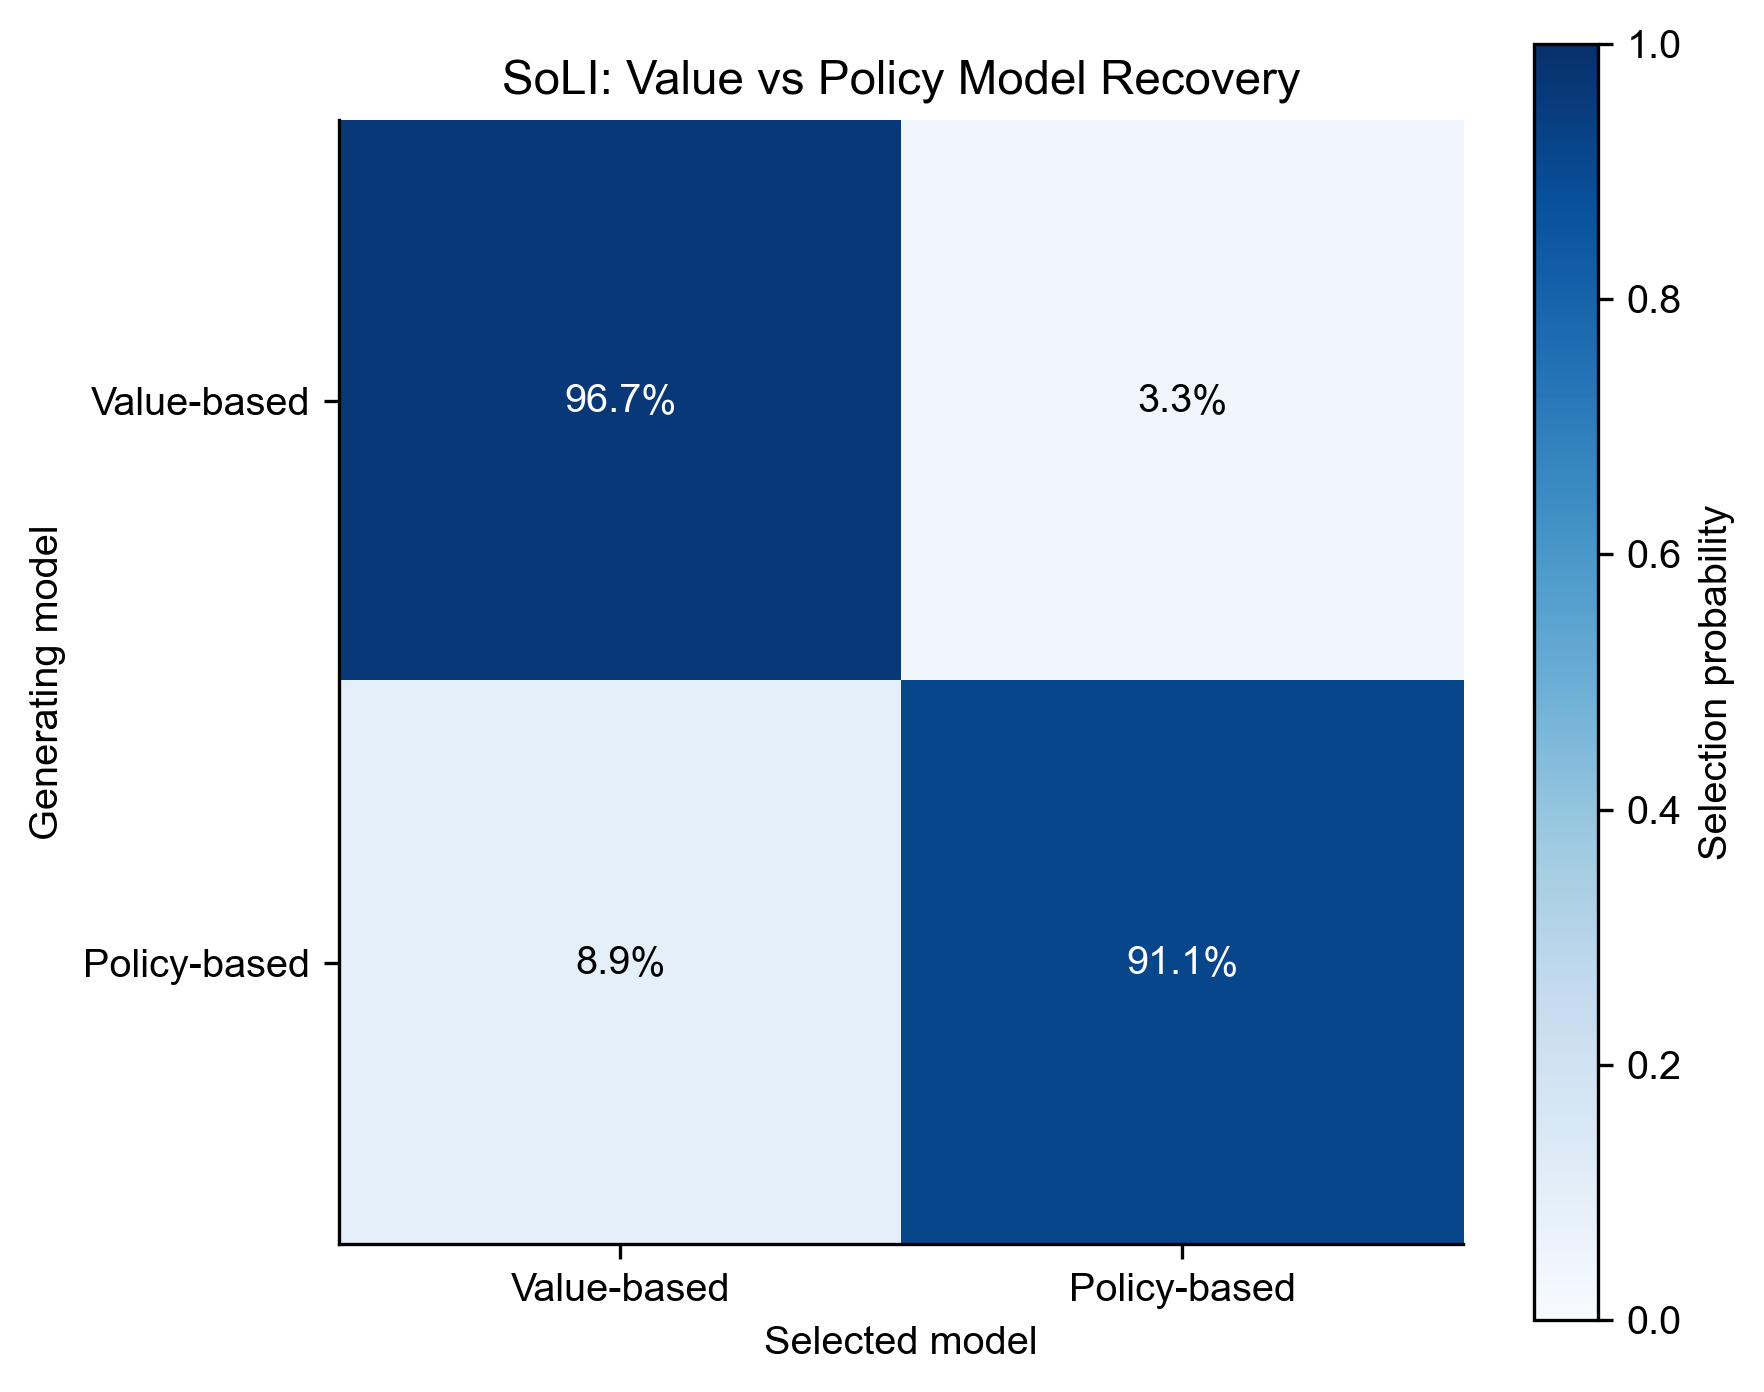

Saved: model_recovery_SoLI_N90_S3_seed2026.png

GROUP: SoLU

Three-model recovery (AIC):


winner_AIC,Baseline,Value-based,Policy-based
generator,,,
Baseline,87.8%,10.0%,2.2%
Value-based,11.1%,81.1%,7.8%
Policy-based,12.2%,10.0%,77.8%



Three-model recovery (BIC):


winner_BIC,Baseline,Value-based,Policy-based
generator,,,
Baseline,100.0%,0.0%,0.0%
Value-based,32.2%,63.3%,4.4%
Policy-based,28.9%,5.6%,65.6%



VALUE-BASED vs POLICY-BASED RECOVERY


winner_social_AIC,Value-based,Policy-based
generator,,
Value-based,91.1%,8.9%
Policy-based,13.3%,86.7%


Correct policy recovery: 86.7%
Value misclassified as policy: 8.9%


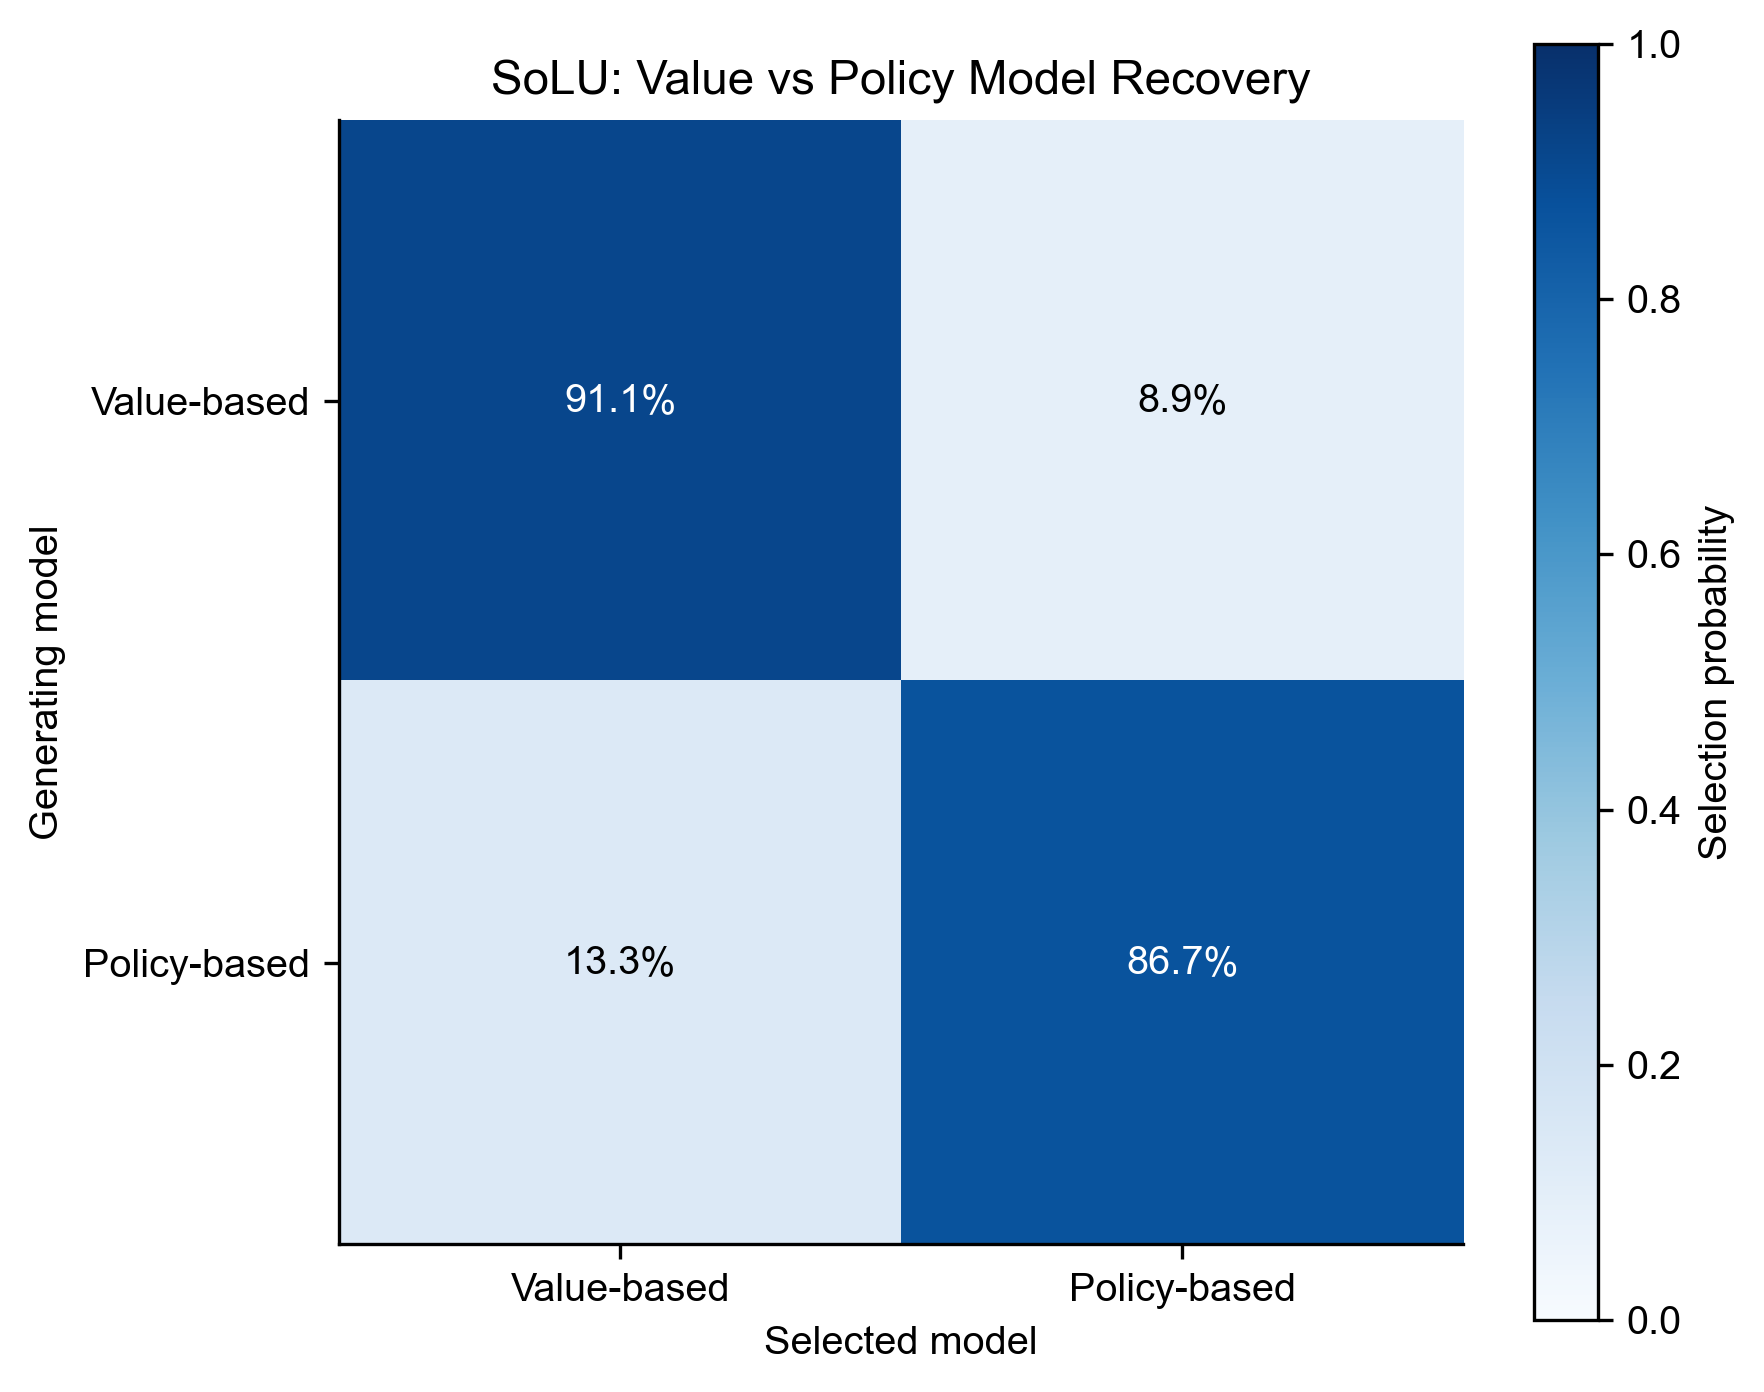

Saved: model_recovery_SoLU_N90_S3_seed2026.png

All model-recovery summaries saved.


In [61]:

# MODEL RECOVERY — CELL 5/5
# Confusion matrices and model distinguishability

mr_trials = pd.read_csv(MR_CHECKPOINT)

assert len(mr_trials) == (
    2 * 3 * MR_N_PER_GROUP_MODEL
)

# Optimization success
for model in MR_MODELS:

    success_rate = (
        mr_trials[f'converged_{model}']
        .astype(str)
        .str.lower()
        .eq('true')
        .mean()
    )

    print(
        f'{model} optimization success: '
        f'{100*success_rate:.1f}%'
    )


all_three_model_results = []
all_social_pair_results = []

for group, _, _ in MR_GROUPS:

    sub = mr_trials[
        mr_trials['group'] == group
    ]

    print("\n" + "="*60)
    print("GROUP:", group)
    print("="*60)

    for criterion in ('AIC', 'BIC'):

        table = pd.crosstab(
            sub['generator'],
            sub[f'winner_{criterion}']
        )

        table = table.reindex(
            index=MR_MODELS,
            columns=MR_MODELS,
            fill_value=0
        )

        rates = table.div(
            table.sum(axis=1),
            axis=0
        )

        print(
            f'\nThree-model recovery ({criterion}):'
        )

        display(
            (100*rates).round(1).astype(str) + '%'
        )

        for generating in MR_MODELS:

            for selected in MR_MODELS:

                all_three_model_results.append({
                    'group': group,
                    'criterion': criterion,
                    'generating': generating,
                    'selected': selected,
                    'count': int(
                        table.loc[generating, selected]
                    ),
                    'proportion': float(
                        rates.loc[generating, selected]
                    )
                })

    # Focused comparison: Value-based vs Policy-based
    social = sub[
        sub['generator'].isin(MR_MODELS[1:])
    ]

    pair = pd.crosstab(
        social['generator'],
        social['winner_social_AIC']
    )

    pair = pair.reindex(
        index=MR_MODELS[1:],
        columns=MR_MODELS[1:],
        fill_value=0
    )

    pair_rates = pair.div(
        pair.sum(axis=1),
        axis=0
    )

    print("\nVALUE-BASED vs POLICY-BASED RECOVERY")

    display(
        (100*pair_rates).round(1).astype(str) + '%'
    )

    print(
        "Correct policy recovery:",
        f"{100*pair_rates.loc['Policy-based', 'Policy-based']:.1f}%"
    )

    print(
        "Value misclassified as policy:",
        f"{100*pair_rates.loc['Value-based', 'Policy-based']:.1f}%"
    )

    for generating in MR_MODELS[1:]:

        for selected in MR_MODELS[1:]:

            all_social_pair_results.append({
                'group': group,
                'generating': generating,
                'selected': selected,
                'count': int(
                    pair.loc[generating, selected]
                ),
                'proportion': float(
                    pair_rates.loc[generating, selected]
                )
            })

    # Plot the focused confusion matrix
    fig, ax = plt.subplots(figsize=(6, 5))

    image = ax.imshow(
        pair_rates.values,
        vmin=0,
        vmax=1,
        cmap='Blues'
    )

    labels = MR_MODELS[1:]

    ax.set_xticks(range(2))
    ax.set_xticklabels(labels)

    ax.set_yticks(range(2))
    ax.set_yticklabels(labels)

    ax.set_xlabel("Selected model")
    ax.set_ylabel("Generating model")

    ax.set_title(
        f"{group}: Value vs Policy Model Recovery"
    )

    for i in range(2):

        for j in range(2):

            value = pair_rates.iloc[i, j]

            ax.text(
                j, i,
                f"{100*value:.1f}%",
                ha='center',
                va='center',
                color='white' if value > 0.55 else 'black'
            )

    fig.colorbar(
        image,
        ax=ax,
        label="Selection probability"
    )

    plt.tight_layout()

    filename = (
        f'model_recovery_{group}_{MR_TAG}.png'
    )

    plt.savefig(
        filename,
        dpi=200,
        bbox_inches='tight'
    )

    plt.show()

    print("Saved:", filename)


# Save summary tables
pd.DataFrame(
    all_three_model_results
).to_csv(
    f'model_recovery_three_models_{MR_TAG}.csv',
    index=False
)

pd.DataFrame(
    all_social_pair_results
).to_csv(
    f'model_recovery_value_vs_policy_{MR_TAG}.csv',
    index=False
)

print("\nAll model-recovery summaries saved.")


## Behavioral Simulation

In [62]:

# Load fitted parameters and original task schedules

import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display

# =========================
# SETTINGS
# =========================

PPC_GROUPS = {
    'SoLI': np.arange(0, 45),
    'SoLU': np.arange(45, 90)
}

PPC_MODELS = ('Value-based', 'Policy-based')


PPC_N_REPS = 200

PPC_SEED = 2026

# Four-trial trailing moving average, restarted at each block.
PPC_WINDOW = 4

PPC_OUTDIR = Path('PPC_Reviewer2')
PPC_OUTDIR.mkdir(parents=True, exist_ok=True)


# =========================
# CHECK EXISTING VARIABLES
# =========================

required = [
    'all_sub_df',
    'all_cv_alpha_ind_Qmean',
    'all_cv_epsilon_ind_Qmean',
    'all_cv_alpha_Qmean',
    'all_cv_epsilon_Qmean',
    'all_cv_gamma_Qmean',
    'all_tv_alpha_ind_Qmean',
    'all_tv_beta_ind_Qmean',
    'all_tv_alpha_Qmean',
    'all_tv_beta_Qmean',
    'all_tv_gamma_Qmean',
    'core_value_Qmean_model',
    'temporary_value_Qmean_model'
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        'Run the original RL fitting cells first. Missing: '
        + ', '.join(missing)
    )

if len(all_sub_df) != 90:
    raise ValueError(
        f'Expected 90 social-group participants, '
        f'found {len(all_sub_df)}'
    )


# =========================
# RECOVER FITTED PARAMETERS
# =========================

PPC_PARAMS = {
    'Value-based': np.column_stack([
        all_cv_alpha_ind_Qmean,
        all_cv_epsilon_ind_Qmean,
        all_cv_alpha_Qmean,
        all_cv_epsilon_Qmean,
        np.asarray(all_cv_gamma_Qmean, dtype=float)
    ]),

    'Policy-based': np.column_stack([
        all_tv_alpha_ind_Qmean,
        all_tv_beta_ind_Qmean,
        all_tv_alpha_Qmean,
        all_tv_beta_Qmean,
        np.asarray(all_tv_gamma_Qmean, dtype=float)
    ])
}

for name, arr in PPC_PARAMS.items():
    if arr.shape != (90, 7) or not np.isfinite(arr).all():
        raise ValueError(
            f'Invalid {name} parameter matrix: {arr.shape}'
        )


# =========================
# PREPARE EXPERIMENTAL DATA
# =========================

PPC_PROBS = np.empty((90, 105, 4), dtype=float)

PPC_REAL_ACTIONS = np.empty((90, 105), dtype=int)
PPC_REAL_REWARDS = np.empty((90, 105), dtype=int)

# Three observed agents in Block 2
PPC_OBS3 = np.full((90, 105, 3), -1, dtype=int)

# Selected agent's demonstrated card in Block 3
PPC_OBS_SINGLE = np.full((90, 105), -1, dtype=int)

# Selected agent identity in Block 3
PPC_SELECTED_AGENT = np.full((90, 105), -1, dtype=int)


for i, frame in enumerate(all_sub_df):

    if len(frame) < 105:
        raise ValueError(
            f'Participant {i} has fewer than 105 trials'
        )

    for t in range(105):

        # Read reward probabilities
        raw_p = frame['card probs'].iloc[t]

        if isinstance(raw_p, str):
            p = ast.literal_eval(raw_p)
        else:
            p = raw_p

        PPC_PROBS[i, t] = np.asarray(p, dtype=float)

        if (
            len(p) != 4
            or not np.allclose(sorted(p), [.4, .5, .6, .7])
        ):
            raise ValueError(
                f'Unexpected reward probabilities '
                f'at participant {i}, trial {t}'
            )

        # Social observation events
        if t >= 15 and t % 3 == 0:

            raw_choice = frame['agent_choices'].iloc[t]

            # Block 2: observe three agents
            if t < 45:

                if isinstance(raw_choice, str):
                    triplet = ast.literal_eval(raw_choice)
                else:
                    triplet = raw_choice

                triplet = np.asarray(triplet, dtype=int)

                if (
                    triplet.shape != (3,)
                    or not np.all(
                        (triplet >= 0) & (triplet < 4)
                    )
                ):
                    raise ValueError(
                        f'Invalid Block-2 observations, '
                        f'participant {i}, trial {t}'
                    )

                PPC_OBS3[i, t] = triplet

            # Block 3: observe selected agent
            else:

                label = str(
                    frame['chosen_agent'].iloc[t]
                ).strip()

                agent_id = {
                    'A': 0,
                    'B': 1,
                    'C': 2
                }.get(label, -1)

                PPC_SELECTED_AGENT[i, t] = agent_id

                if agent_id >= 0:

                    try:
                        card = int(raw_choice)
                    except (ValueError, TypeError):
                        raise ValueError(
                            f'Invalid selected-agent card '
                            f'for {i}, trial {t}: {raw_choice!r}'
                        )

                    if not (0 <= card < 4):
                        raise ValueError(
                            f'Invalid card index: {card}'
                        )

                    PPC_OBS_SINGLE[i, t] = card

    # Real participant choices
    PPC_REAL_ACTIONS[i] = np.asarray(
        frame['choice'].iloc[:105],
        dtype=int
    )

    # Real participant rewards
    PPC_REAL_REWARDS[i] = (
        frame['outcome'].iloc[:105].to_numpy() == 'win'
    ).astype(int)


if not np.all(
    (PPC_REAL_ACTIONS >= 0)
    & (PPC_REAL_ACTIONS < 4)
):
    raise ValueError('Unexpected action values')


# Card rank:
# 0 = optimal
# 1 = second-best
# 2 = third-best
# 3 = worst

PPC_RANK = np.argsort(
    np.argsort(-PPC_PROBS, axis=2),
    axis=2
)


print('PPC inputs ready.')
print('Participants:', len(all_sub_df))
print('Trials:', 105)
print('Models:', PPC_MODELS)

print(
    'Fixed Block-3 observation cycles:',
    int((PPC_SELECTED_AGENT[:, 45::3] >= 0).sum())
)

print(
    'Simulation repetitions per model/group:',
    PPC_N_REPS
)

print('Output folder:', PPC_OUTDIR.resolve())

PPC inputs ready.
Participants: 90
Trials: 105
Models: ('Value-based', 'Policy-based')
Fixed Block-3 observation cycles: 1520
Simulation repetitions per model/group: 200
Output folder: D:\University\University of Tehran\MSc\Thesis\paper draft\main\paper draft\paper\New version\Submission\Code\PPC_Reviewer2


In [63]:

# Exact model simulation and likelihood validation


def ppc_social_impact(params, ids, t):
    """
    Calculate social influence at an observation event.

    Returns:
        array of shape (n_participants, 4)
    """

    n = len(ids)

    impact = np.zeros((n, 4), dtype=float)

    if t < 15 or t % 3 != 0:
        return impact

    row = np.arange(n)

    # Block 2: observe all three agents
    if t < 45:

        for j in range(3):

            cards = PPC_OBS3[ids, t, j]

            np.add.at(
                impact,
                (row, cards),
                params[:, 4 + j]
            )

    # Block 3: observe the selected agent
    else:

        agents = PPC_SELECTED_AGENT[ids, t]
        cards = PPC_OBS_SINGLE[ids, t]

        good = (
            (agents >= 0)
            & (cards >= 0)
        )

        if np.any(good):

            impact[
                row[good],
                cards[good]
            ] += params[
                row[good],
                4 + agents[good]
            ]

    return impact


def ppc_simulate(model, ids, rng):
    """
    Generate choices and rewards from the fitted RL model.

    Original model mechanics:
    - Q-values reset to their mean at t=15 and t=45.
    - Individual parameters are used for t<15.
    - Value-based social influence modifies Q-values.
    - Policy-based social influence modifies decision values
      without directly modifying underlying Q-values.
    - Social influence is updated every three trials.

    Returns:
        acts:    (n_participants, 105)
        rewards: (n_participants, 105)
        nll:     (n_participants,)
    """

    params = PPC_PARAMS[model][ids]

    n = len(ids)
    row = np.arange(n)

    Q = np.zeros((n, 4), dtype=float)

    influence = np.zeros((n, 4), dtype=float)

    acts = np.empty((n, 105), dtype=int)
    rewards = np.empty((n, 105), dtype=int)

    logp = np.zeros(n, dtype=float)

    for t in range(105):

        # Reset learned values after reshuffling
        if t in (15, 45):
            Q[:] = Q.mean(axis=1, keepdims=True)

        # Individual-learning block
        if t < 15:

            alpha = params[:, 0]
            beta = params[:, 1]

            decision_Q = Q

        # Social-learning blocks
        else:

            alpha = params[:, 2]
            beta = params[:, 3]

            # New social observation
            if t % 3 == 0:

                influence = ppc_social_impact(
                    params, ids, t
                )

                # Persistent value modification
                if model == 'Value-based':
                    Q += influence

            # Temporary decision bias
            if model == 'Policy-based':
                decision_Q = Q + influence
            else:
                decision_Q = Q

        # =========================
        # SOFTMAX ACTION SELECTION
        # =========================

        z = beta[:, None] * decision_Q

        z -= z.max(axis=1, keepdims=True)

        probs = np.exp(z)

        probs /= probs.sum(
            axis=1,
            keepdims=True
        )

        # Sample a card choice
        uniforms = rng.random(n)

        cumulative = np.cumsum(
            probs,
            axis=1
        )

        a = np.minimum(
            (uniforms[:, None] > cumulative).sum(axis=1),
            3
        )

        # Sample new rewards using original probabilities
        r = (
            rng.random(n)
            < PPC_PROBS[ids, t, a]
        ).astype(int)

        acts[:, t] = a
        rewards[:, t] = r

        # Original notebook omits trial 0 from likelihood
        if t > 0:

            logp += np.log(
                np.maximum(
                    probs[row, a],
                    1e-300
                )
            )

        # Private reinforcement-learning update
        Q[row, a] += alpha * (
            r - Q[row, a]
        )

    return acts, rewards, -logp


# =========================
# VALIDATION AGAINST
# ORIGINAL NOTEBOOK FUNCTIONS
# =========================

original_funcs = {
    'Value-based': core_value_Qmean_model,
    'Policy-based': temporary_value_Qmean_model
}

for model in PPC_MODELS:

    for subject in (0, 44, 45, 89):

        a, r, sim_nll = ppc_simulate(
            model,
            np.array([subject]),
            np.random.default_rng(2026 + subject)
        )

        frame = all_sub_df[subject]

        orig_nll = float(
            original_funcs[model](
                PPC_PARAMS[model][subject],
                a[0],
                r[0],
                frame['agent_choices'].iloc[:105],
                frame['chosen_agent'].iloc[:105]
            )
        )

        if not np.isclose(
            orig_nll,
            sim_nll[0],
            atol=1e-8,
            rtol=0
        ):

            raise AssertionError(
                f'Generator-likelihood mismatch for '
                f'{model}, participant {subject}: '
                f'{orig_nll} vs {sim_nll[0]}'
            )

print(
    'PASS: predictive-check simulations match '
    'the original value-based and policy-based '
    'model likelihoods in both groups.'
)

PASS: predictive-check simulations match the original value-based and policy-based model likelihoods in both groups.


In [64]:

# Repeated simulation and behavioral measurements


PPC_OBSERVED = {}
PPC_RESULTS = {}


def ppc_summarize(acts, rewards, ids):
    """
    Calculate comparable behavioral measures
    for real and simulated datasets.
    """

    n = len(ids)

    # =========================
    # CARD RANK
    # =========================

    chosen_rank = PPC_RANK[
        ids[:, None],
        np.arange(105)[None, :],
        acts
    ]

    # Optimal-card choice probability at each trial
    optimal_by_trial = (
        chosen_rank == 0
    ).mean(axis=0)

    # Card rank distribution in Block 3
    rank_b3 = np.array([
        (chosen_rank[:, 45:] == rank).mean()
        for rank in range(4)
    ])

    # =========================
    # BLOCK-WISE PERFORMANCE
    # =========================

    blocks = (
        (0, 15),
        (15, 45),
        (45, 105)
    )

    block_optimal = np.array([
        (chosen_rank[:, lo:hi] == 0).mean()
        for lo, hi in blocks
    ])

    block_reward = np.array([
        rewards[:, lo:hi].mean()
        for lo, hi in blocks
    ])

    # =========================
    # SOCIAL CHOICE MATCHING
    # =========================

    # Does the participant choose the card
    # demonstrated by the selected agent?
    #
    # lag 0 = first choice after observation
    # lag 1 = second choice
    # lag 2 = third choice
    #
    # Equal participant weighting.
    #
    # This is a descriptive measure rather
    # than a causal estimate of influence.

    lag_match = np.full(3, np.nan)

    for lag in range(3):

        within_subject = []

        for local_i, subject in enumerate(ids):

            events = np.arange(
                45, 105, 3
            )

            demonstrated = PPC_OBS_SINGLE[
                subject,
                events
            ]

            eligible = demonstrated >= 0

            if eligible.any():

                matching = (
                    acts[
                        local_i,
                        events[eligible] + lag
                    ]
                    == demonstrated[eligible]
                )

                within_subject.append(
                    np.mean(matching)
                )

        if within_subject:

            lag_match[lag] = np.mean(
                within_subject
            )

    # =========================
    # SOCIAL CUE SWITCHING
    # =========================

    # Look for consecutive observation events
    # in which the demonstrated cards differ.
    #
    # At the new observation event:
    # - Does the participant select the new card?
    # - Or the previously demonstrated card?

    switch_new = []
    switch_old = []

    for local_i, subject in enumerate(ids):

        starts = np.arange(
            45, 102, 3
        )

        old_card = PPC_OBS_SINGLE[
            subject,
            starts
        ]

        new_card = PPC_OBS_SINGLE[
            subject,
            starts + 3
        ]

        eligible = (
            (old_card >= 0)
            & (new_card >= 0)
            & (old_card != new_card)
        )

        if eligible.any():

            choices_at_new = acts[
                local_i,
                starts[eligible] + 3
            ]

            switch_new.append(
                np.mean(
                    choices_at_new
                    == new_card[eligible]
                )
            )

            switch_old.append(
                np.mean(
                    choices_at_new
                    == old_card[eligible]
                )
            )

    switch_align = np.array([
        np.mean(switch_new),
        np.mean(switch_old)
    ])

    return {
        'optimal_by_trial': optimal_by_trial,
        'rank_b3': rank_b3,
        'block_optimal': block_optimal,
        'block_reward': block_reward,
        'lag_match': lag_match,
        'switch_align': switch_align
    }


# =========================
# CHECKPOINT FILES
# =========================

def ppc_file(group, model):

    return PPC_OUTDIR / (
        f'ppc_{group}_'
        f'{model.lower().replace("-", "_")}_'
        f'N{PPC_N_REPS}_seed{PPC_SEED}.npz'
    )


# =========================
# RUN SIMULATIONS
# =========================

metric_keys = (
    'optimal_by_trial',
    'rank_b3',
    'block_optimal',
    'block_reward',
    'lag_match',
    'switch_align'
)

for gi, (group, ids) in enumerate(
    PPC_GROUPS.items()
):

    # Real participant behavior
    PPC_OBSERVED[group] = ppc_summarize(
        PPC_REAL_ACTIONS[ids],
        PPC_REAL_REWARDS[ids],
        ids
    )

    for mi, model in enumerate(PPC_MODELS):

        fname = ppc_file(
            group,
            model
        )

        # Resume from saved simulations
        if fname.exists():

            saved = np.load(fname)

            output = {
                k: saved[k].copy()
                for k in metric_keys
            }

            count = len(
                output['optimal_by_trial']
            )

            print(
                'Resuming',
                group,
                model,
                'at',
                count,
                '/',
                PPC_N_REPS
            )

        else:

            output = {
                k: []
                for k in metric_keys
            }

            count = 0

        # Run remaining simulation repetitions
        for rep in range(count, PPC_N_REPS):

            rng = np.random.default_rng([
                PPC_SEED,
                100,
                gi,
                mi,
                rep
            ])

            acts, rewards, _ = ppc_simulate(
                model,
                ids,
                rng
            )

            metrics = ppc_summarize(
                acts,
                rewards,
                ids
            )

            for key in output:

                if isinstance(output[key], list):

                    output[key].append(
                        metrics[key]
                    )

                else:

                    output[key] = np.concatenate(
                        (
                            output[key],
                            metrics[key][None, :]
                        ),
                        axis=0
                    )

            # Save checkpoints
            if (
                (rep + 1) % 25 == 0
                or rep + 1 == PPC_N_REPS
            ):

                np.savez_compressed(
                    fname,
                    **{
                        k: np.asarray(v)
                        for k, v in output.items()
                    }
                )

                print(
                    f'{group} | {model} | '
                    f'{rep + 1}/{PPC_N_REPS}',
                    flush=True
                )

        PPC_RESULTS[(group, model)] = {
            k: np.asarray(v)
            for k, v in output.items()
        }

        if len(
            PPC_RESULTS[
                (group, model)
            ]['optimal_by_trial']
        ) != PPC_N_REPS:

            raise RuntimeError(
                'Incorrect saved simulation count'
            )


print()
print('All predictive simulations completed.')

print(
    'Results saved in:',
    PPC_OUTDIR.resolve()
)

Resuming SoLI Value-based at 200 / 200
Resuming SoLI Policy-based at 200 / 200
Resuming SoLU Value-based at 200 / 200
Resuming SoLU Policy-based at 200 / 200

All predictive simulations completed.
Results saved in: D:\University\University of Tehran\MSc\Thesis\paper draft\main\paper draft\paper\New version\Submission\Code\PPC_Reviewer2


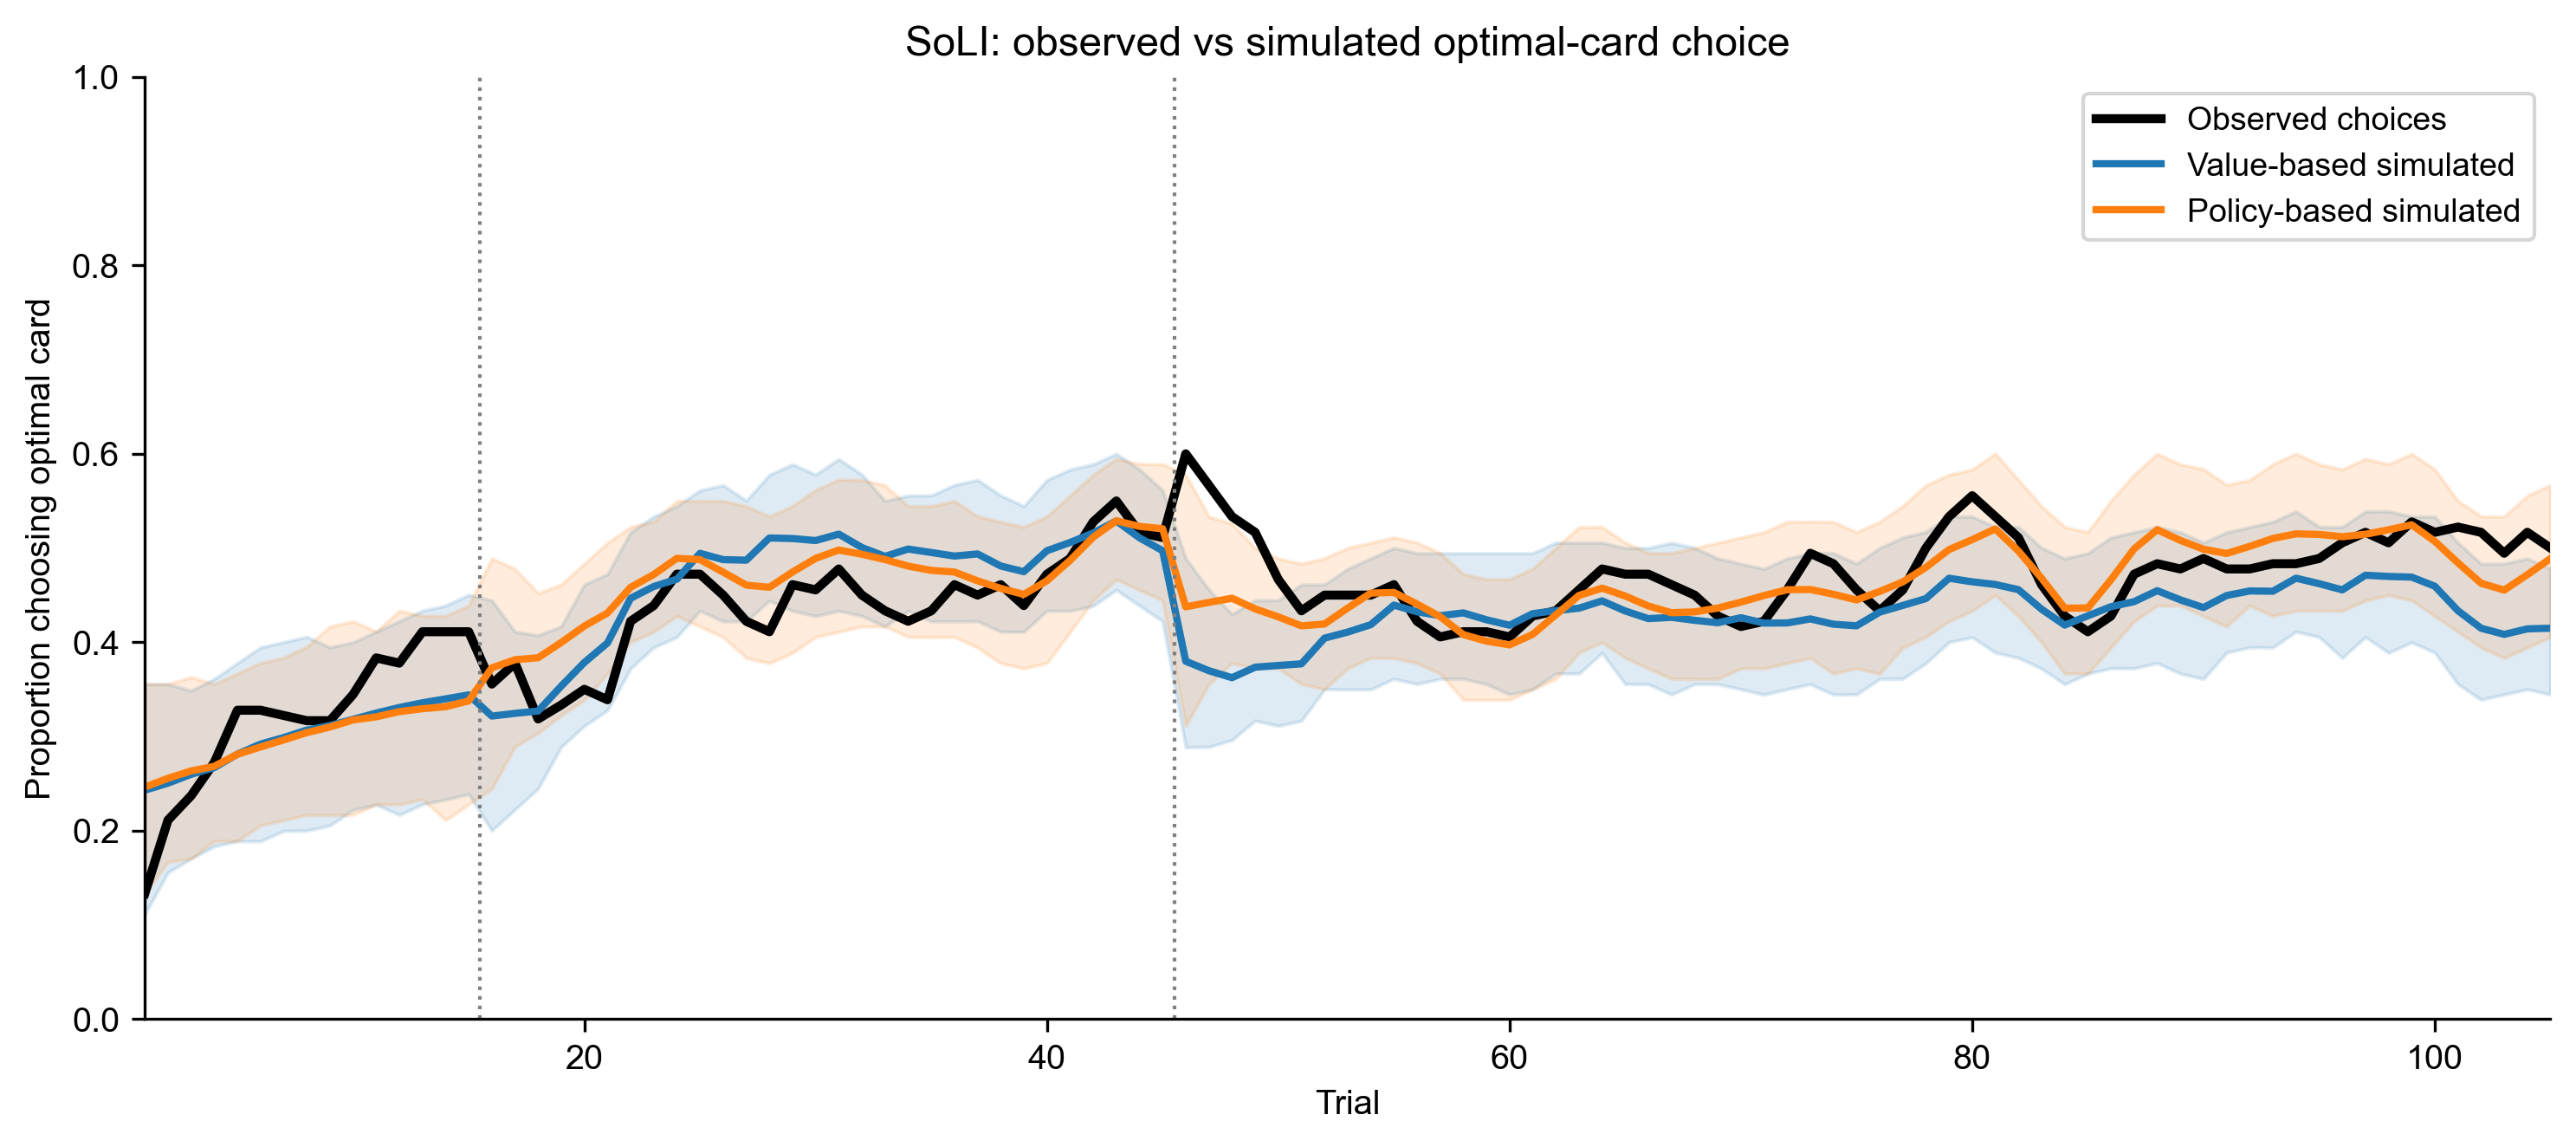

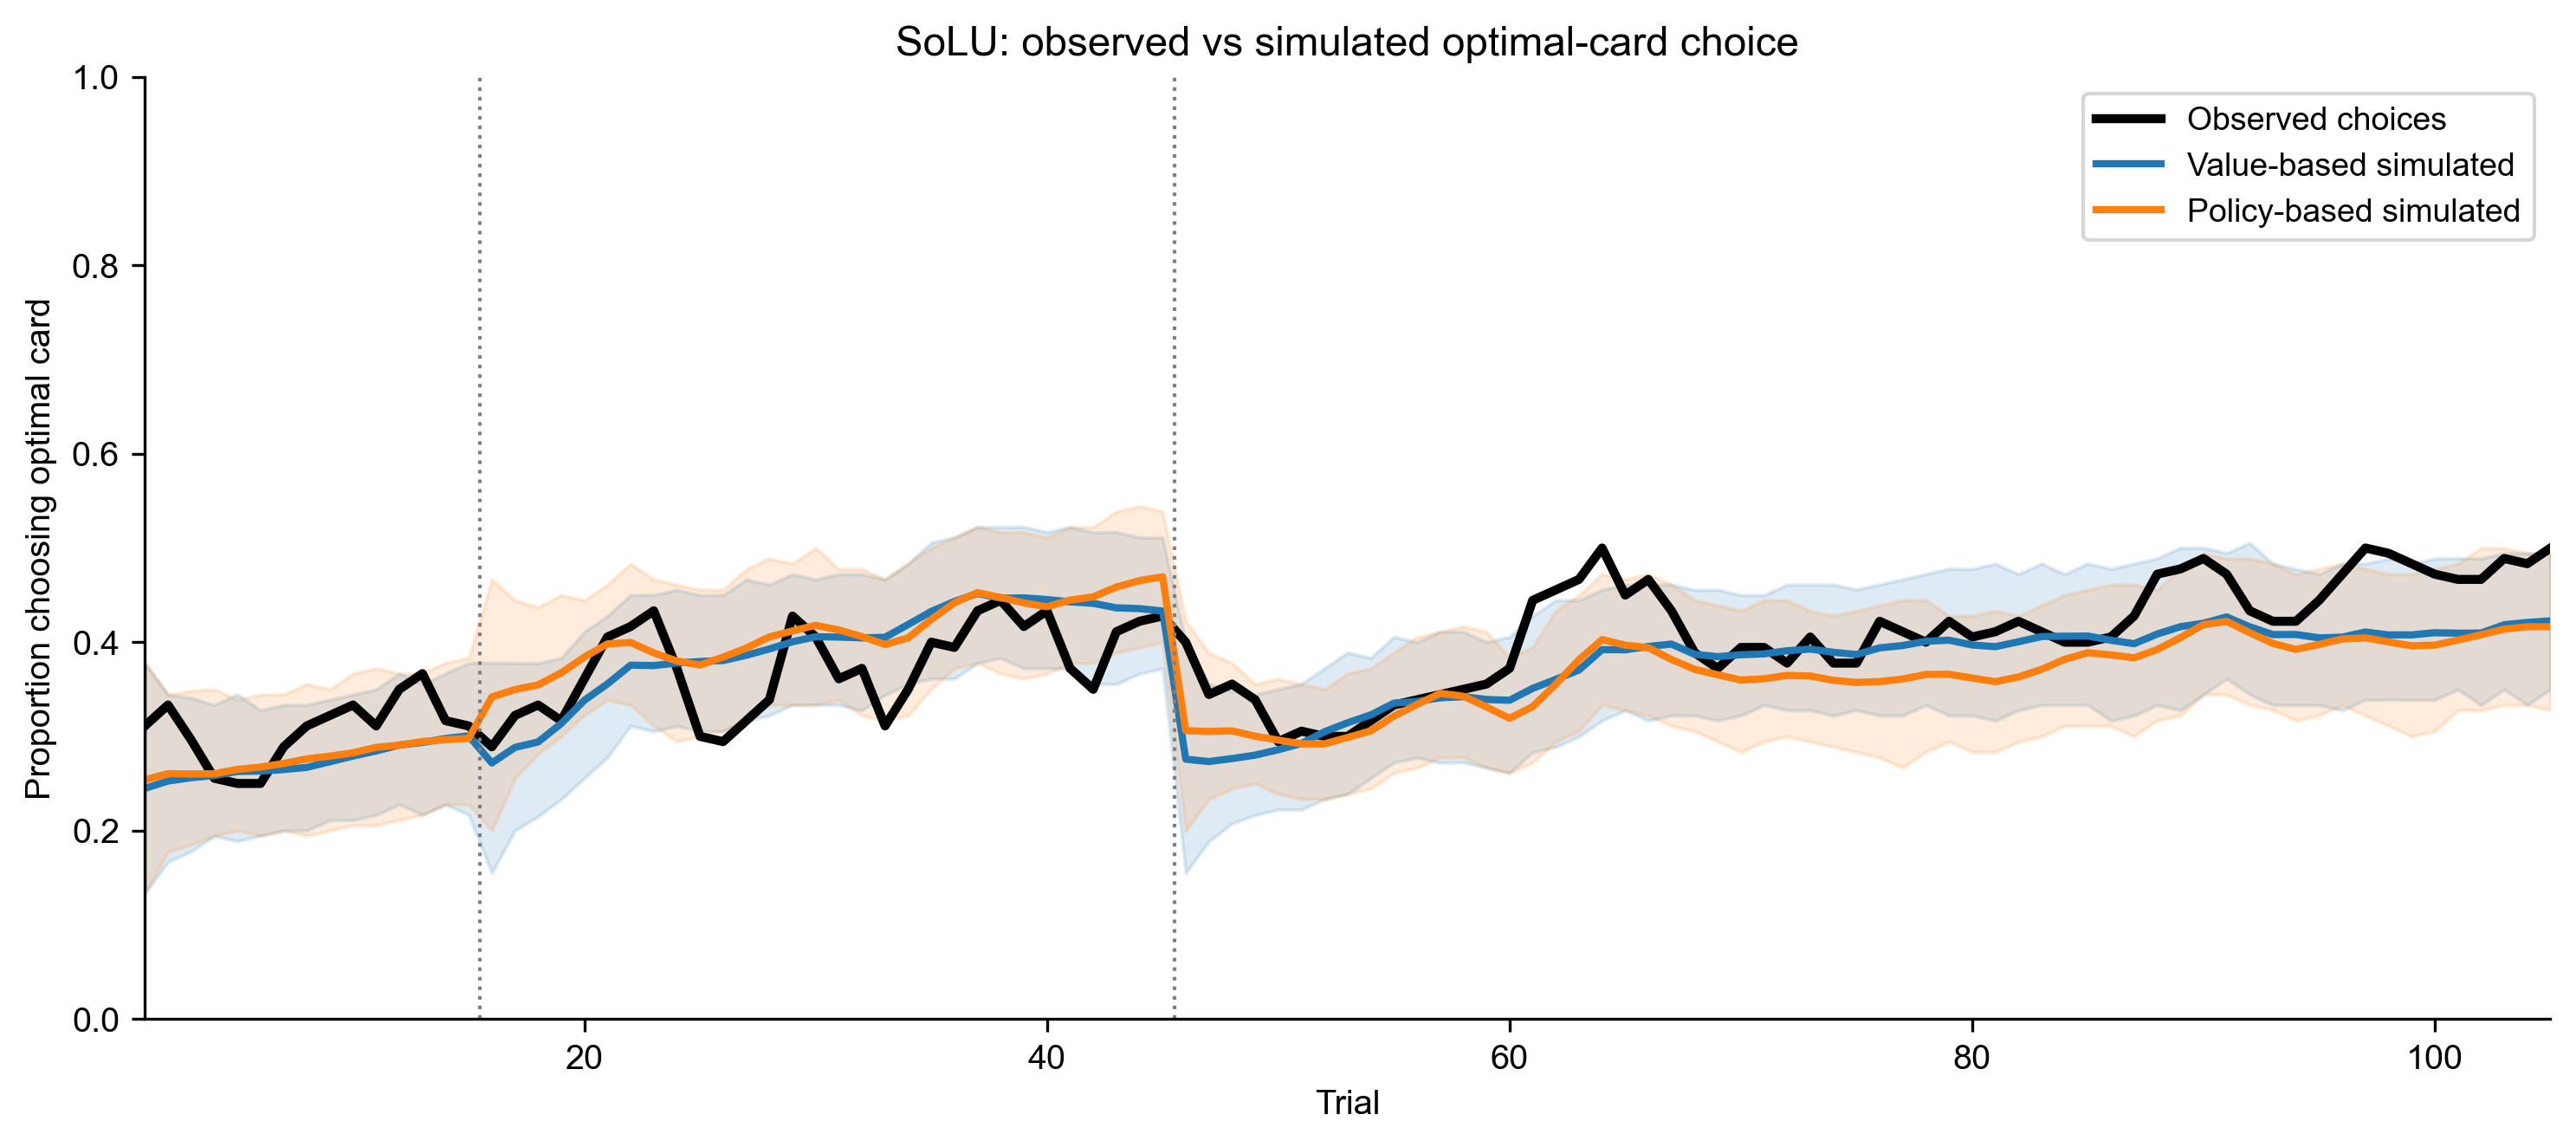

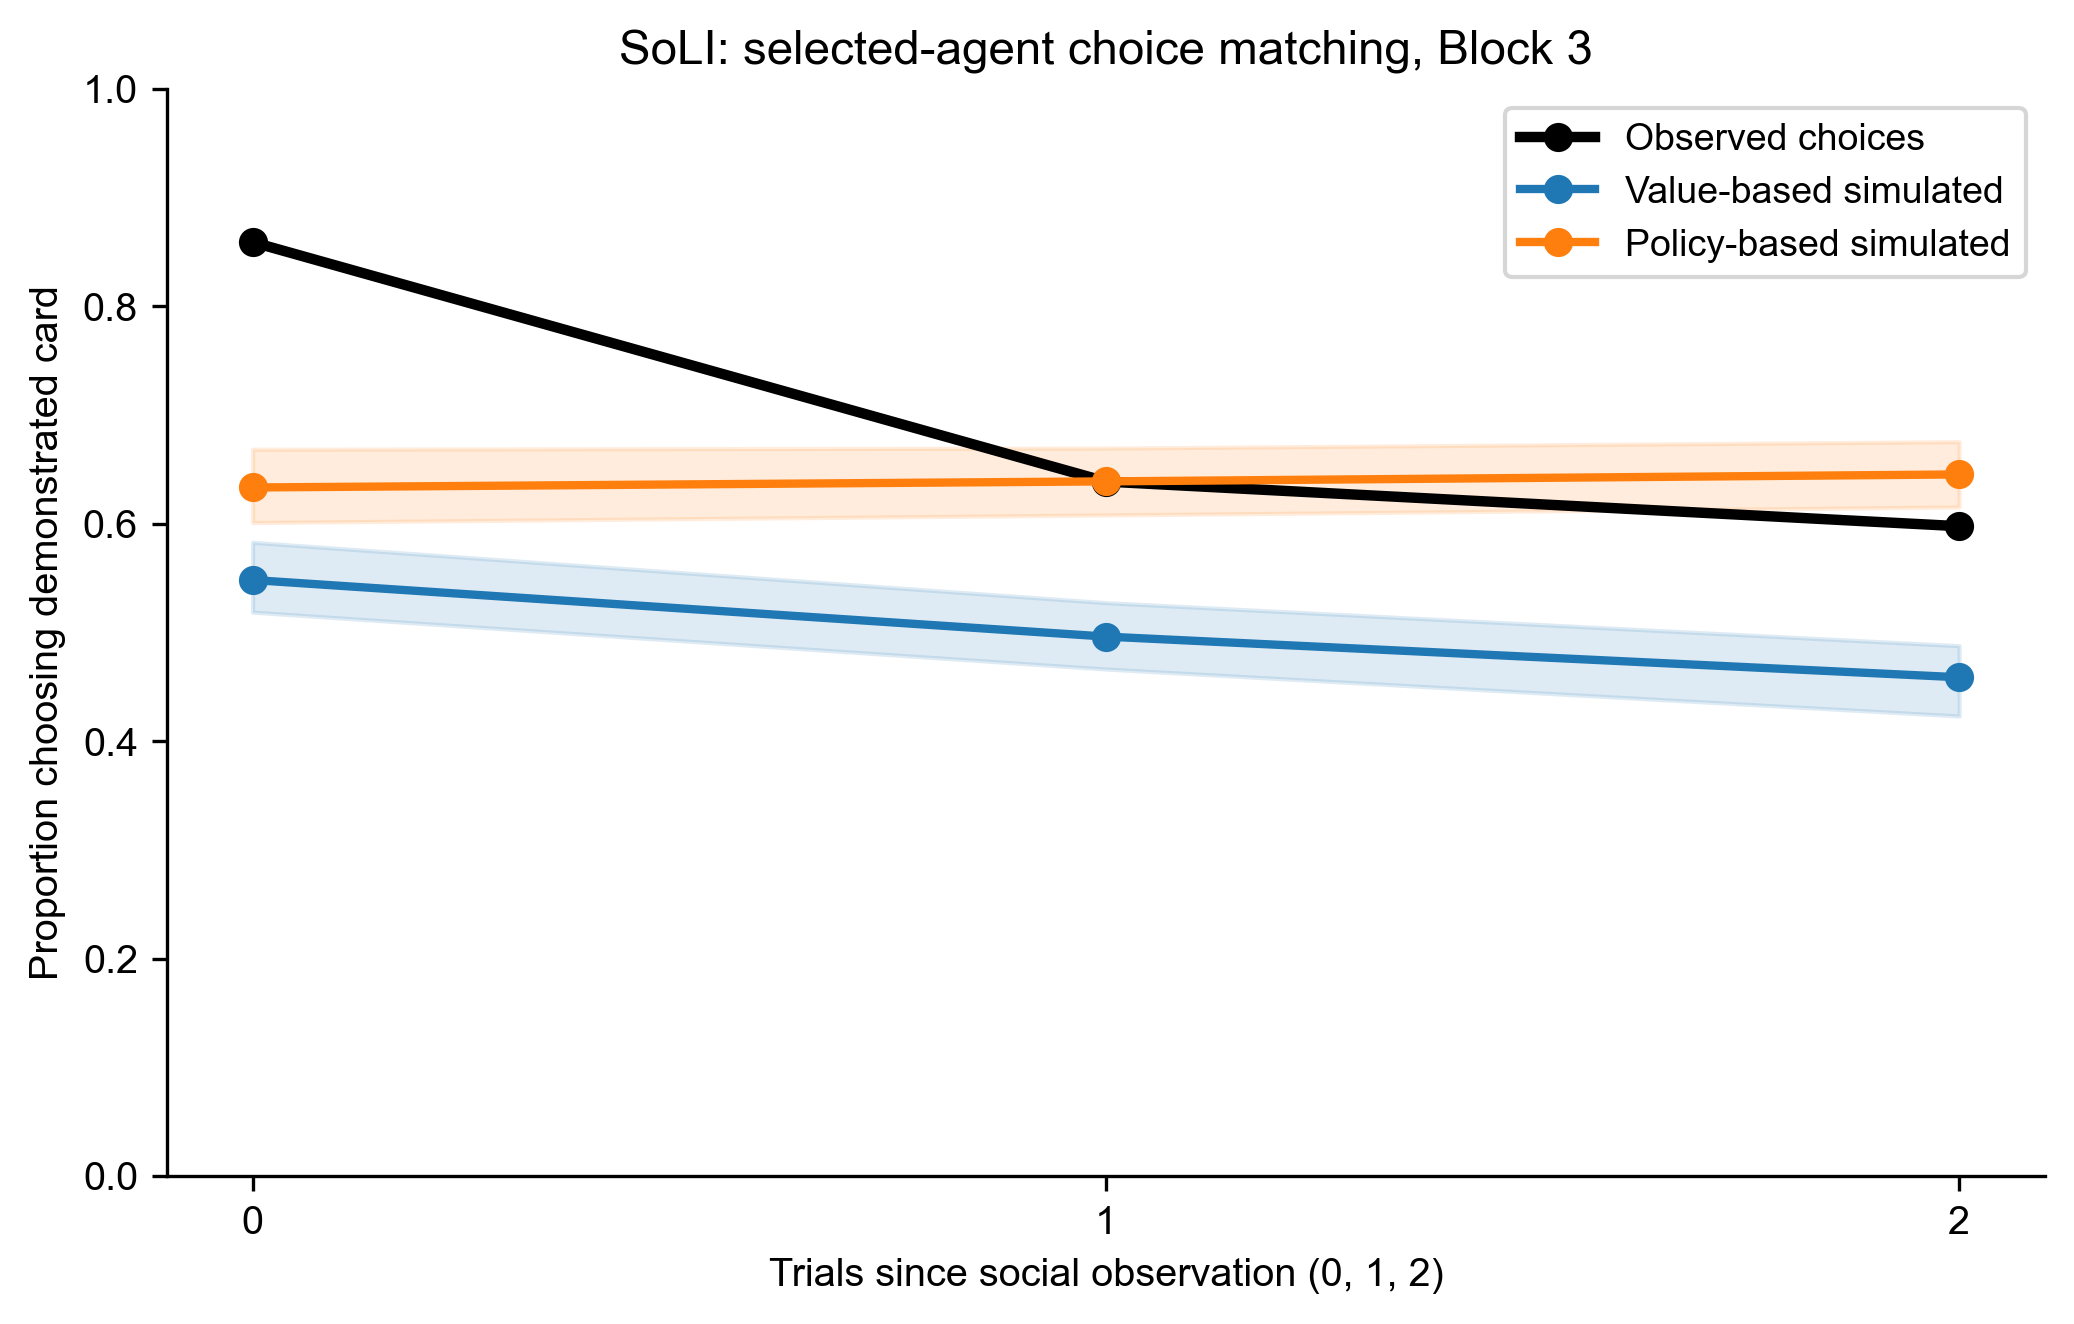

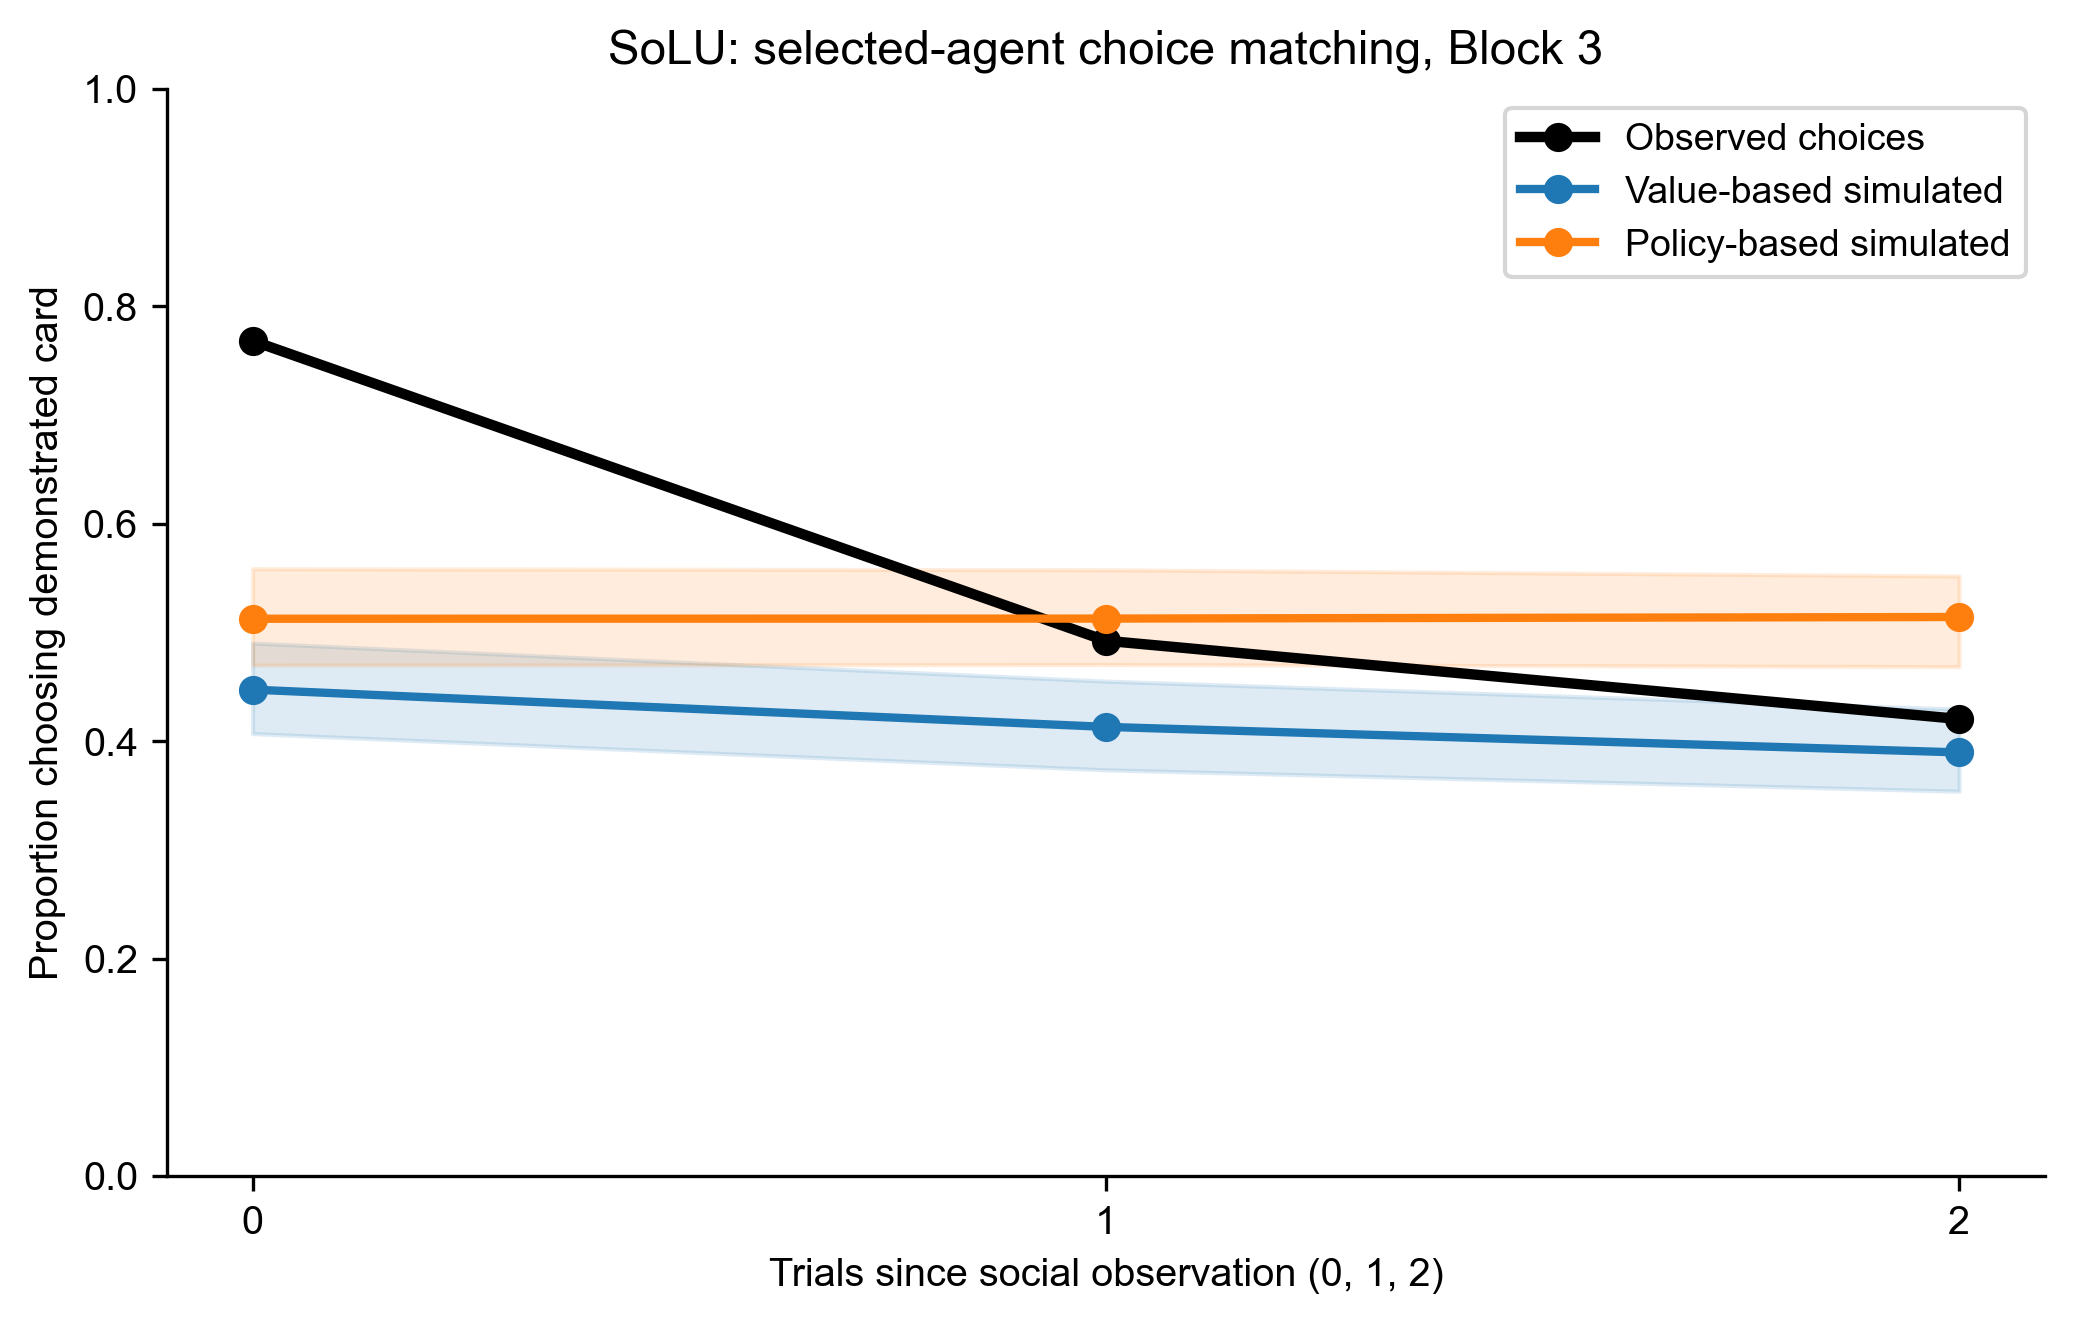

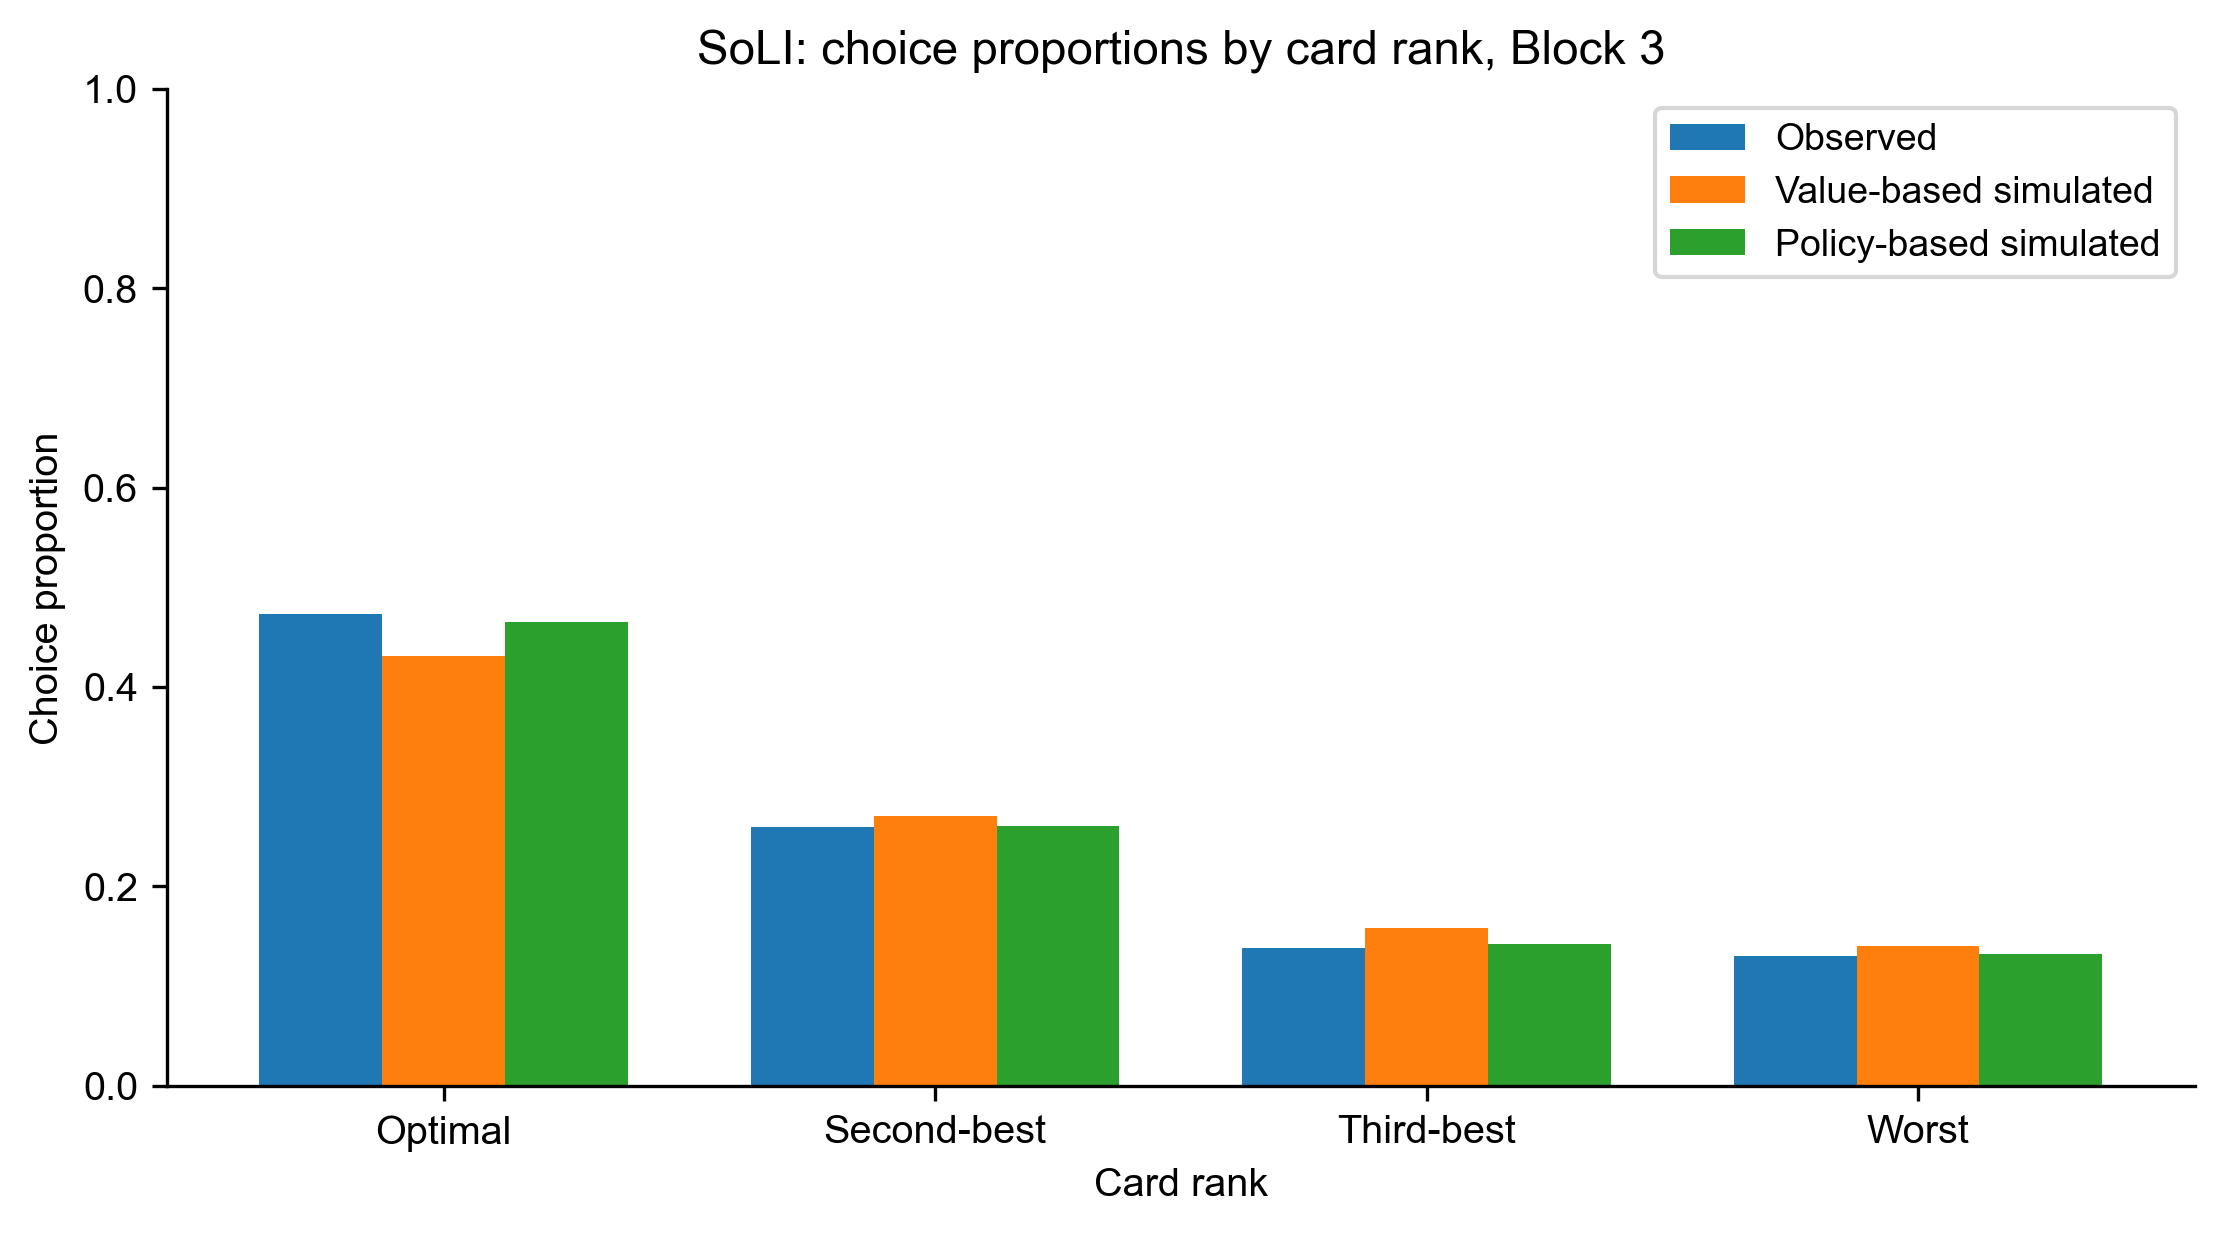

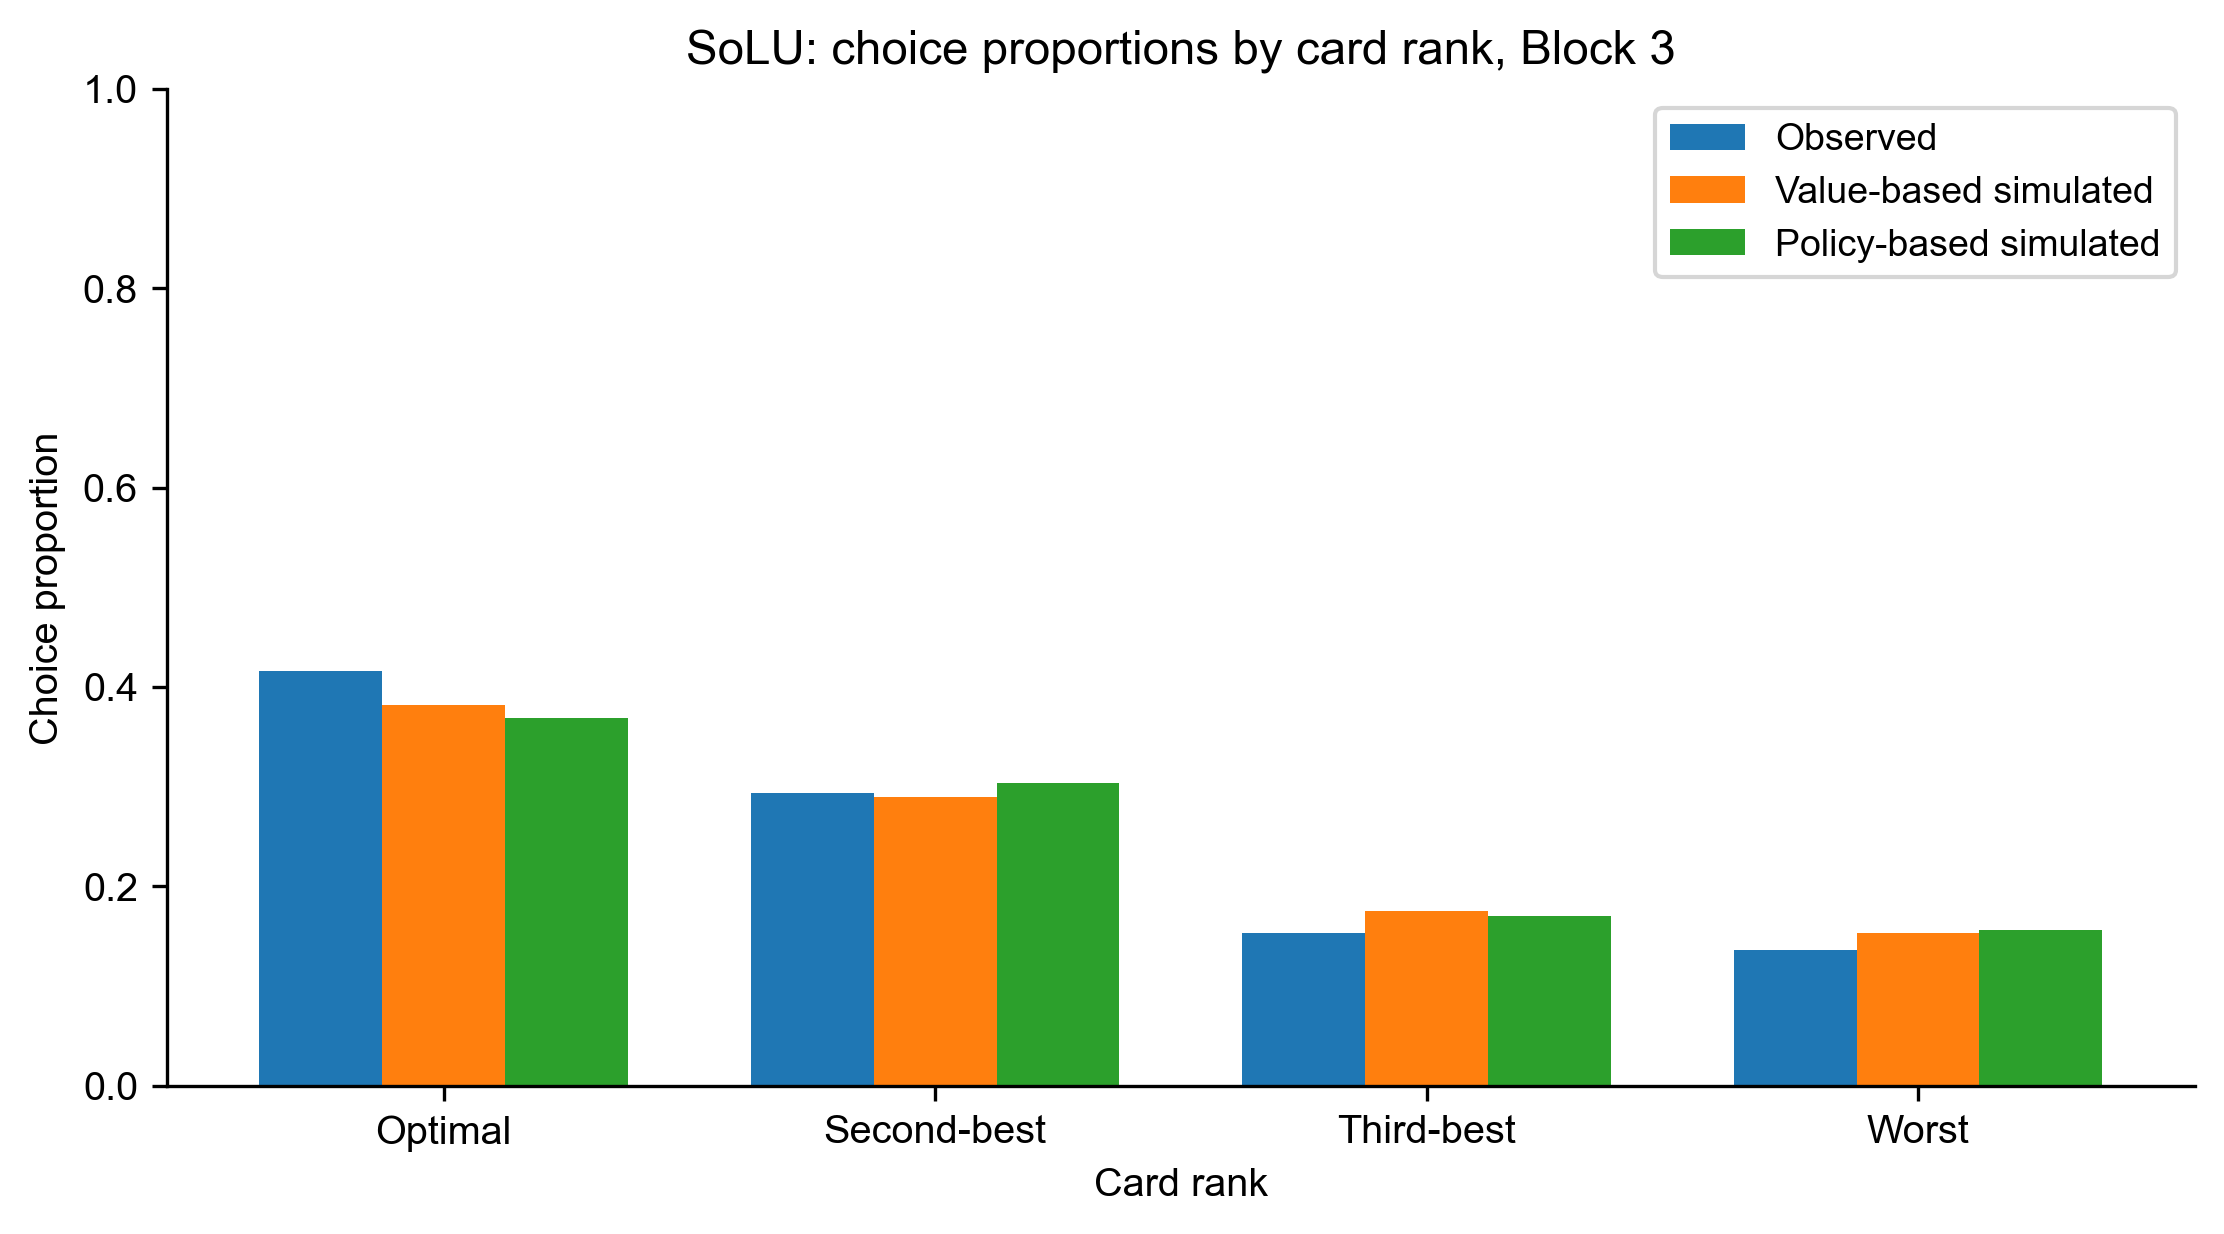

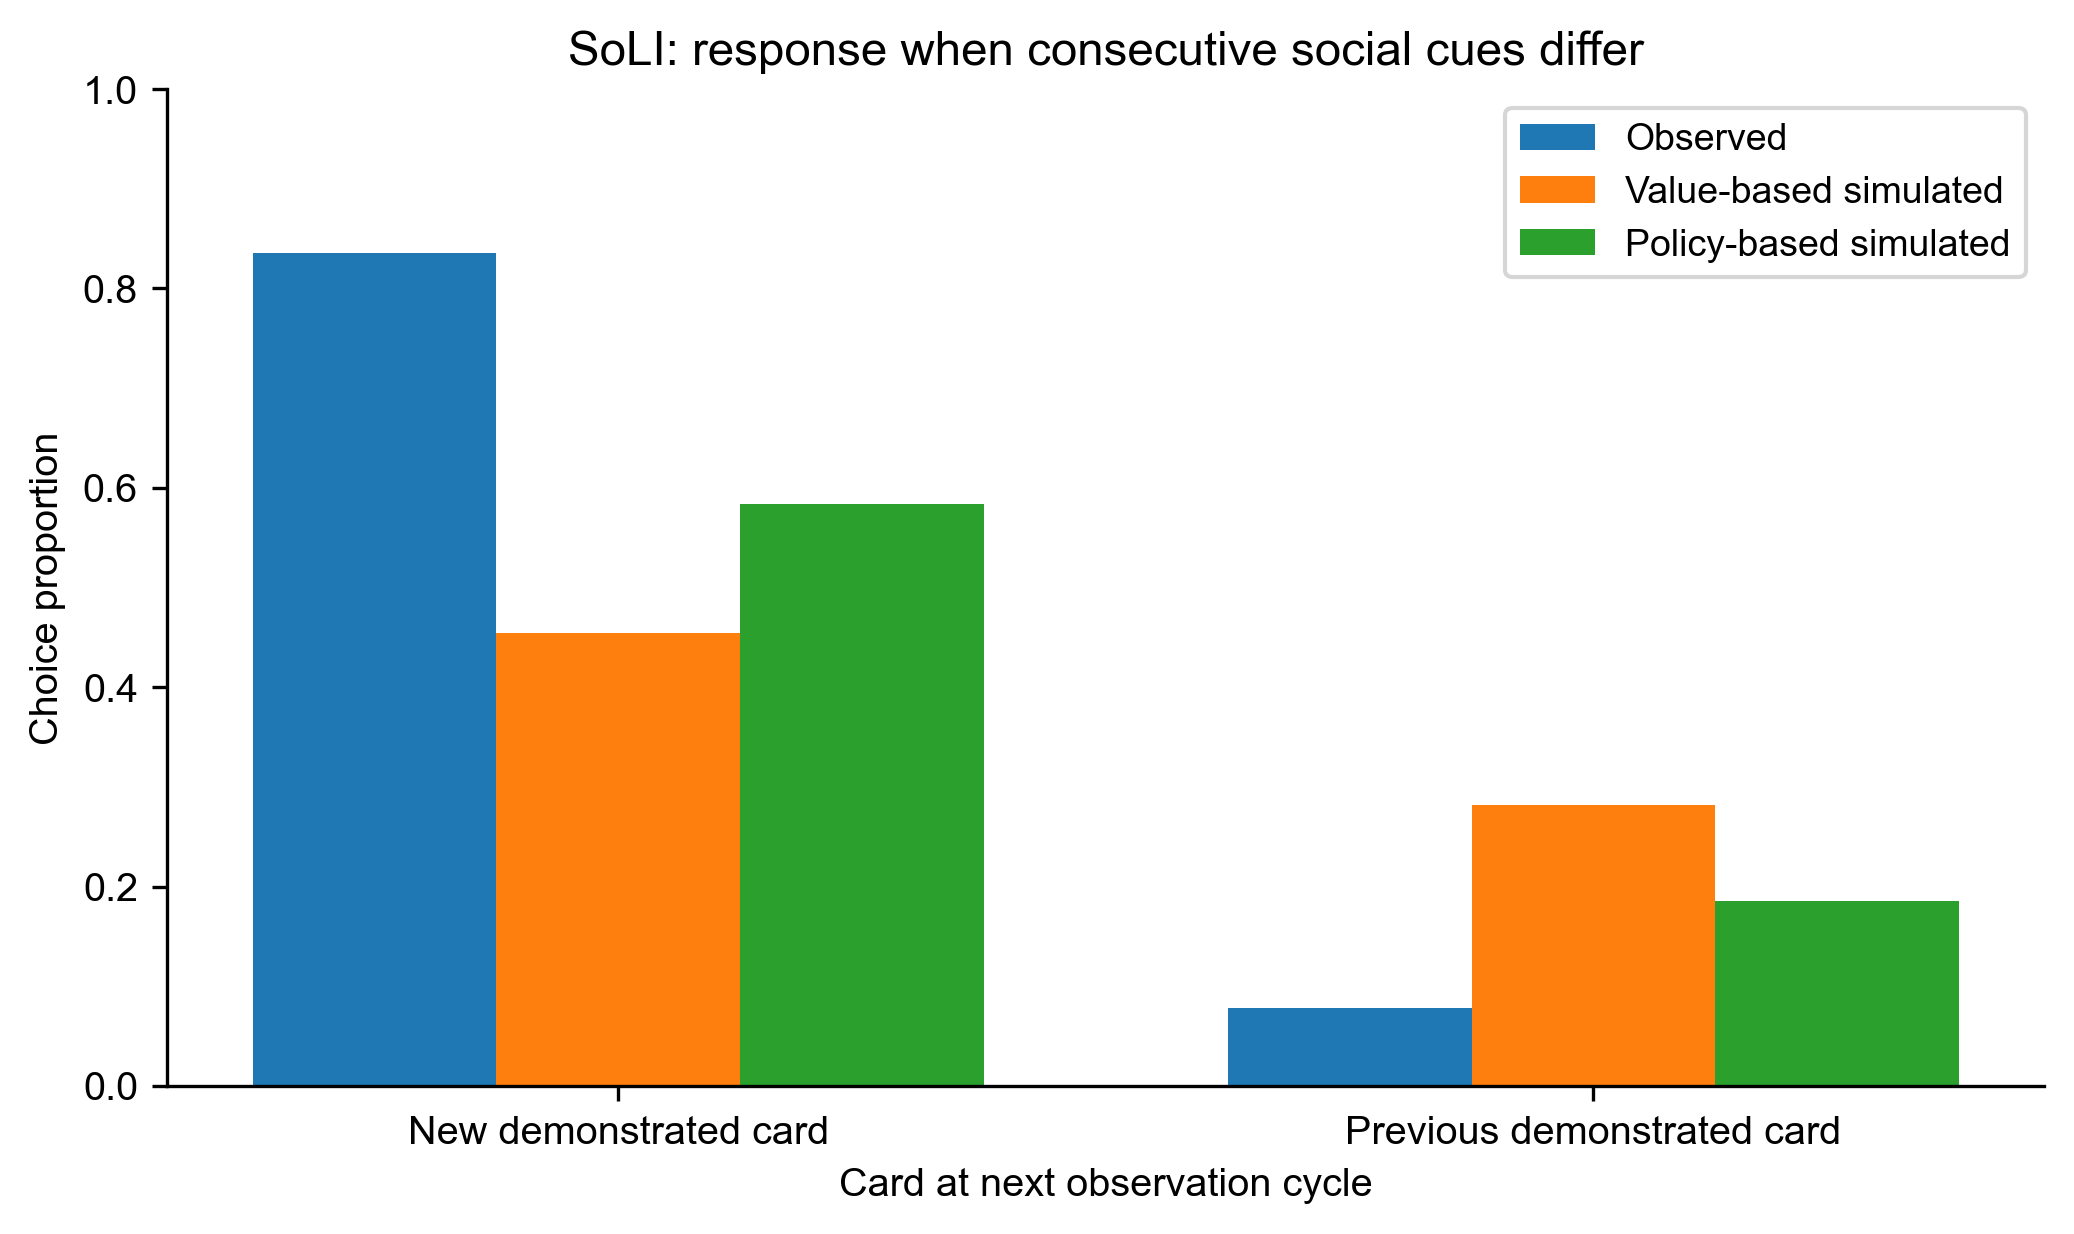

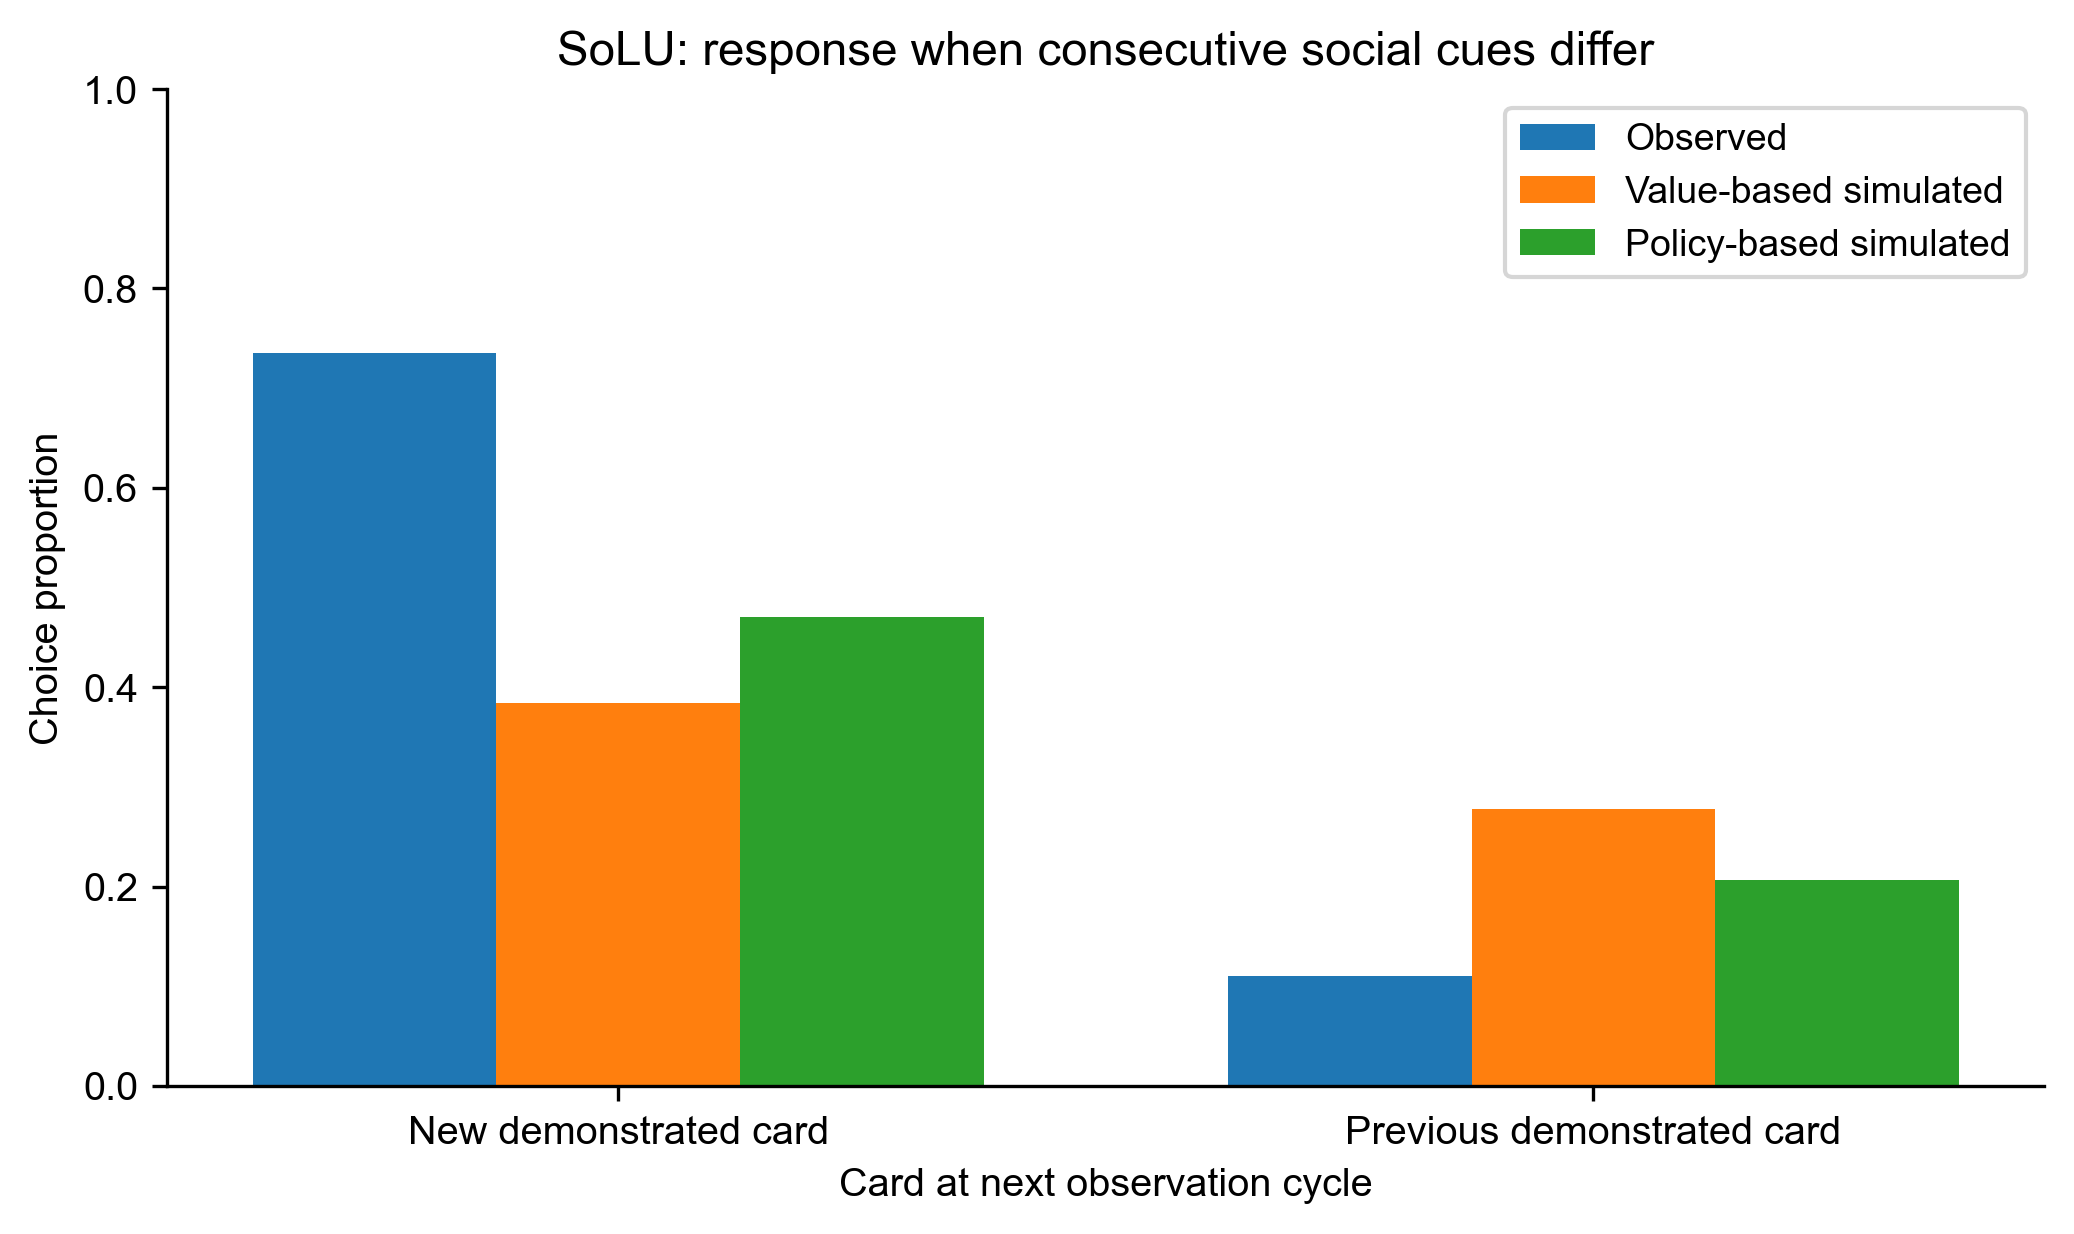

,Group,Model,Measure,Observed,Simulated_mean,Simulated_2_5,Simulated_97_5,Absolute_discrepancy
0,SoLI,Value-based,Block 1 optimal choice,0.345,0.310,0.218,0.381,0.035
1,SoLI,Value-based,Block 2 optimal choice,0.446,0.474,0.433,0.516,0.028
2,SoLI,Value-based,Block 3 optimal choice,0.473,0.431,0.404,0.460,0.042
3,SoLI,Value-based,Block 1 reward rate,0.559,0.567,0.527,0.609,0.009
4,SoLI,Value-based,Block 2 reward rate,0.606,0.611,0.584,0.642,0.005
5,SoLI,Value-based,Block 3 reward rate,0.594,0.599,0.578,0.618,0.005
6,SoLI,Value-based,Block 3 optimal choice,0.473,0.431,0.404,0.460,0.042
7,SoLI,Value-based,Block 3 second-best choice,0.259,0.270,0.243,0.299,0.011
8,SoLI,Value-based,Block 3 third-best choice,0.138,0.158,0.137,0.182,0.021
9,SoLI,Value-based,Block 3 worst choice,0.130,0.140,0.126,0.161,0.010



Analysis completed.
Saved 8 figures and summary CSV in:
D:\University\University of Tehran\MSc\Thesis\paper draft\main\paper draft\paper\New version\Submission\Code\PPC_Reviewer2

NOTE: These are in-sample predictive checks conditional on observed agent selections.
Social matching by lag is descriptive, not a causal estimate of persistence.


In [65]:

# Generate figures and observed-vs-simulated summaries


def ppc_smooth_blocks(x, width=4):
    """
    Trailing moving average calculated separately
    within each experimental block.
    """

    x = np.asarray(x, dtype=float)

    result = np.empty_like(x)

    blocks = (
        (0, 15),
        (15, 45),
        (45, 105)
    )

    for lo, hi in blocks:

        for t in range(lo, hi):

            result[..., t] = x[
                ...,
                max(lo, t - width + 1):t + 1
            ].mean(axis=-1)

    return result


# =========================
# FIGURE 1:
# OPTIMAL-CARD CHOICE TRAJECTORIES
# =========================

for group in PPC_GROUPS:

    observed = PPC_OBSERVED[group]

    x = np.arange(1, 106)

    fig, ax = plt.subplots(
        figsize=(10, 4.5)
    )

    observed_curve = ppc_smooth_blocks(
        observed['optimal_by_trial'],
        PPC_WINDOW
    )

    ax.plot(
        x,
        observed_curve,
        label='Observed choices',
        color='black',
        lw=2.5
    )

    for model in PPC_MODELS:

        sims = ppc_smooth_blocks(
            PPC_RESULTS[
                (group, model)
            ]['optimal_by_trial'],
            PPC_WINDOW
        )

        pred_mean = sims.mean(axis=0)

        lower, upper = np.quantile(
            sims,
            [.025, .975],
            axis=0
        )

        line, = ax.plot(
            x,
            pred_mean,
            lw=2,
            label=model + ' simulated'
        )

        ax.fill_between(
            x,
            lower,
            upper,
            alpha=.14,
            color=line.get_color()
        )

    for cut in (15.5, 45.5):

        ax.axvline(
            cut,
            linestyle=':',
            linewidth=1,
            color='gray'
        )

    ax.set(
        xlabel='Trial',
        ylabel='Proportion choosing optimal card',
        title=(
            f'{group}: observed vs simulated '
            f'optimal-card choice'
        ),
        ylim=(0, 1),
        xlim=(1, 105)
    )

    ax.legend(
        loc='best',
        fontsize=9
    )

    fig.tight_layout()

    fig.savefig(
        PPC_OUTDIR
        / f'{group}_optimal_choice_trajectories.png',
        dpi=200
    )

    plt.show()


# =========================
# FIGURE 2:
# SOCIAL OBSERVATION MATCHING
# =========================

for group in PPC_GROUPS:

    observed = PPC_OBSERVED[group]

    fig, ax = plt.subplots(
        figsize=(7, 4.5)
    )

    xs = np.arange(3)

    ax.plot(
        xs,
        observed['lag_match'],
        'o-',
        color='black',
        lw=2.5,
        label='Observed choices'
    )

    for model in PPC_MODELS:

        vals = PPC_RESULTS[
            (group, model)
        ]['lag_match']

        mean = np.mean(
            vals,
            axis=0
        )

        lower, upper = np.quantile(
            vals,
            [.025, .975],
            axis=0
        )

        line, = ax.plot(
            xs,
            mean,
            'o-',
            lw=2,
            label=model + ' simulated'
        )

        ax.fill_between(
            xs,
            lower,
            upper,
            alpha=.14,
            color=line.get_color()
        )

    ax.set(
        xlabel='Trials since social observation (0, 1, 2)',
        ylabel='Proportion choosing demonstrated card',
        title=(
            f'{group}: selected-agent '
            f'choice matching, Block 3'
        ),
        xticks=xs,
        ylim=(0, 1)
    )

    ax.legend(
        loc='best',
        fontsize=9
    )

    fig.tight_layout()

    fig.savefig(
        PPC_OUTDIR
        / f'{group}_agent_matching_by_lag.png',
        dpi=200
    )

    plt.show()


# =========================
# FIGURE 3:
# CARD-RANK CHOICE DISTRIBUTION
# =========================

for group in PPC_GROUPS:

    observed = PPC_OBSERVED[group]

    fig, ax = plt.subplots(
        figsize=(7.5, 4.2)
    )

    cats = [
        'Optimal',
        'Second-best',
        'Third-best',
        'Worst'
    ]

    pos = np.arange(4)

    width = .25

    ax.bar(
        pos - width,
        observed['rank_b3'],
        width,
        label='Observed'
    )

    for j, model in enumerate(PPC_MODELS):

        vals = PPC_RESULTS[
            (group, model)
        ]['rank_b3']

        ax.bar(
            pos + j * width,
            vals.mean(axis=0),
            width,
            label=model + ' simulated'
        )

    ax.set(
        xlabel='Card rank',
        ylabel='Choice proportion',
        title=(
            f'{group}: choice proportions '
            f'by card rank, Block 3'
        ),
        xticks=pos,
        xticklabels=cats,
        ylim=(0, 1)
    )

    ax.legend(fontsize=9)

    fig.tight_layout()

    fig.savefig(
        PPC_OUTDIR
        / f'{group}_block3_card_rank.png',
        dpi=200
    )

    plt.show()


# =========================
# FIGURE 4:
# RESPONSE TO CHANGING SOCIAL CUES
# =========================

for group in PPC_GROUPS:

    observed = PPC_OBSERVED[
        group
    ]['switch_align']

    fig, ax = plt.subplots(
        figsize=(7, 4.2)
    )

    xpos = np.arange(2)

    width = .25

    ax.bar(
        xpos - width,
        observed,
        width,
        label='Observed'
    )

    for j, model in enumerate(PPC_MODELS):

        vals = PPC_RESULTS[
            (group, model)
        ]['switch_align']

        ax.bar(
            xpos + j * width,
            vals.mean(axis=0),
            width,
            label=model + ' simulated'
        )

    ax.set(
        xlabel='Card at next observation cycle',
        ylabel='Choice proportion',
        title=(
            f'{group}: response when '
            f'consecutive social cues differ'
        ),
        xticks=xpos,
        xticklabels=[
            'New demonstrated card',
            'Previous demonstrated card'
        ],
        ylim=(0, 1)
    )

    ax.legend(fontsize=9)

    fig.tight_layout()

    fig.savefig(
        PPC_OUTDIR
        / f'{group}_social_cue_switch.png',
        dpi=200
    )

    plt.show()


# =========================
# SUMMARY TABLE:
# OBSERVED VS SIMULATED
# =========================

labels = {
    'block_optimal': [
        'Block 1 optimal choice',
        'Block 2 optimal choice',
        'Block 3 optimal choice'
    ],

    'block_reward': [
        'Block 1 reward rate',
        'Block 2 reward rate',
        'Block 3 reward rate'
    ],

    'rank_b3': [
        'Block 3 optimal choice',
        'Block 3 second-best choice',
        'Block 3 third-best choice',
        'Block 3 worst choice'
    ],

    'lag_match': [
        'Agent-match at lag 0',
        'Agent-match at lag 1',
        'Agent-match at lag 2'
    ],

    'switch_align': [
        'On cue switch: choose newly demonstrated card',
        'On cue switch: choose previously demonstrated card'
    ]
}


rows = []

for group in PPC_GROUPS:

    for model in PPC_MODELS:

        for key, metric_labels in labels.items():

            obs = PPC_OBSERVED[
                group
            ][key]

            sims = PPC_RESULTS[
                (group, model)
            ][key]

            mean = sims.mean(axis=0)

            lo, hi = np.quantile(
                sims,
                [.025, .975],
                axis=0
            )

            for j, label in enumerate(metric_labels):

                rows.append({
                    'Group': group,
                    'Model': model,
                    'Measure': label,
                    'Observed': obs[j],
                    'Simulated_mean': mean[j],
                    'Simulated_2_5': lo[j],
                    'Simulated_97_5': hi[j],
                    'Absolute_discrepancy': abs(
                        obs[j] - mean[j]
                    )
                })


PPC_SUMMARY = pd.DataFrame(rows)

PPC_SUMMARY.to_csv(
    PPC_OUTDIR
    / 'PPC_observed_vs_simulated_summary.csv',
    index=False
)

display(
    PPC_SUMMARY.round(3)
)

print()
print('Analysis completed.')
print('Saved 8 figures and summary CSV in:')
print(PPC_OUTDIR.resolve())

print()
print(
    'NOTE: These are in-sample predictive checks '
    'conditional on observed agent selections.'
)

print(
    'Social matching by lag is descriptive, '
    'not a causal estimate of persistence.'
)

In [66]:

# Uses each participant's actual choices and rewards.

import numpy as np
from scipy.special import logsumexp


def ppc_one_step_probabilities(model, subject):

    theta = PPC_PARAMS[model][subject]

    alpha_ind, beta_ind, alpha_social, beta_social = theta[:4]
    gamma = theta[4:7]

    Q = np.zeros(4, dtype=float)
    social_impact = np.zeros(4, dtype=float)

    probabilities = np.empty((105, 4), dtype=float)

    for t in range(105):

        # Match original block-transition handling.
        if t in (15, 45):
            Q[:] = Q.mean()

        if t < 15:

            alpha, beta = alpha_ind, beta_ind
            decision_Q = Q

        else:

            alpha, beta = alpha_social, beta_social

            if t % 3 == 0:

                social_impact[:] = 0.0

                if t < 45:

                    # Three observed agents.
                    for j in range(3):

                        card = PPC_OBS3[subject, t, j]

                        assert 0 <= card < 4

                        social_impact[card] += gamma[j]

                else:

                    # Selected agent in Block 3.
                    agent = PPC_SELECTED_AGENT[subject, t]
                    card = PPC_OBS_SINGLE[subject, t]

                    if agent >= 0:

                        assert 0 <= agent < 3
                        assert 0 <= card < 4

                        social_impact[card] += gamma[agent]

                    else:

                        assert card == -1

                if model == 'Value-based':
                    Q += social_impact

            if model == 'Policy-based':
                decision_Q = Q + social_impact
            else:
                decision_Q = Q

        # Predict choice probabilities.
        log_weights = beta * decision_Q

        probabilities[t] = np.exp(
            log_weights - logsumexp(log_weights)
        )

        # Update using ACTUAL choices and rewards.
        action = PPC_REAL_ACTIONS[subject, t]
        reward = PPC_REAL_REWARDS[subject, t]

        Q[action] += alpha * (reward - Q[action])

    return probabilities


PPC_ONESTEP = {}

model_functions = {
    'Value-based': core_value_Qmean_model,
    'Policy-based': temporary_value_Qmean_model
}

for model in PPC_MODELS:

    predictions = np.stack([
        ppc_one_step_probabilities(model, i)
        for i in range(90)
    ])

    PPC_ONESTEP[model] = predictions

    # Check all 90 participants against original NLL.
    for i, frame in enumerate(all_sub_df):

        actions = PPC_REAL_ACTIONS[i]
        rewards = PPC_REAL_REWARDS[i]

        predicted_nll = -np.log(
            predictions[i, np.arange(1, 105), actions[1:]]
        ).sum()

        original_nll = model_functions[model](
            PPC_PARAMS[model][i],
            actions,
            rewards,
            frame['agent_choices'].iloc[:105],
            frame['chosen_agent'].iloc[:105]
        )

        assert np.isclose(
            predicted_nll,
            original_nll,
            atol=1e-8,
            rtol=0
        ), f'Mismatch: {model}, subject {i}'

    print(f'{model}: all 90 participant likelihoods verified.')

print('PASS: one-step predictions match original RL models.')

Value-based: all 90 participant likelihoods verified.
Policy-based: all 90 participant likelihoods verified.
PASS: one-step predictions match original RL models.


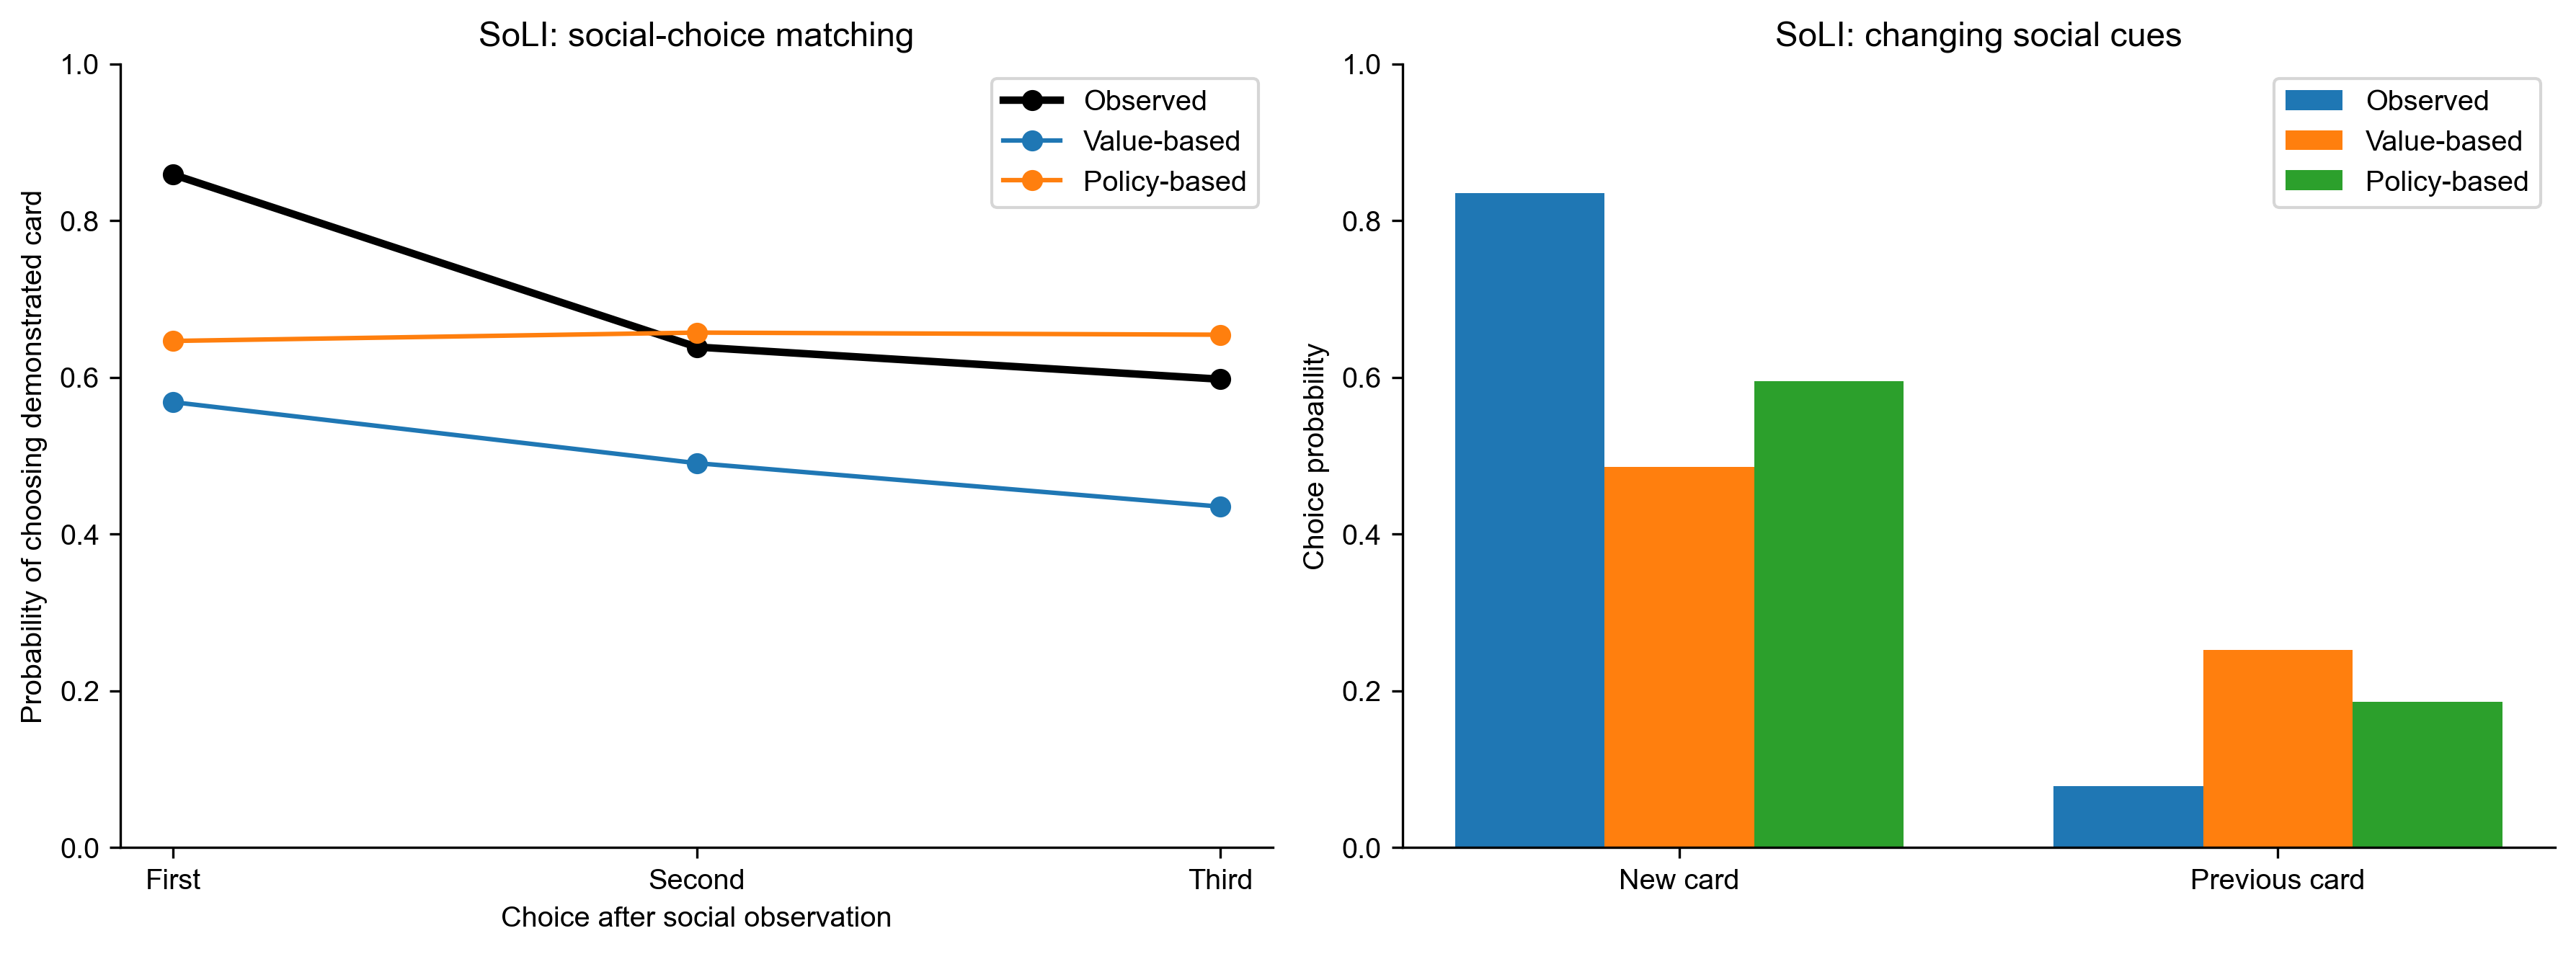

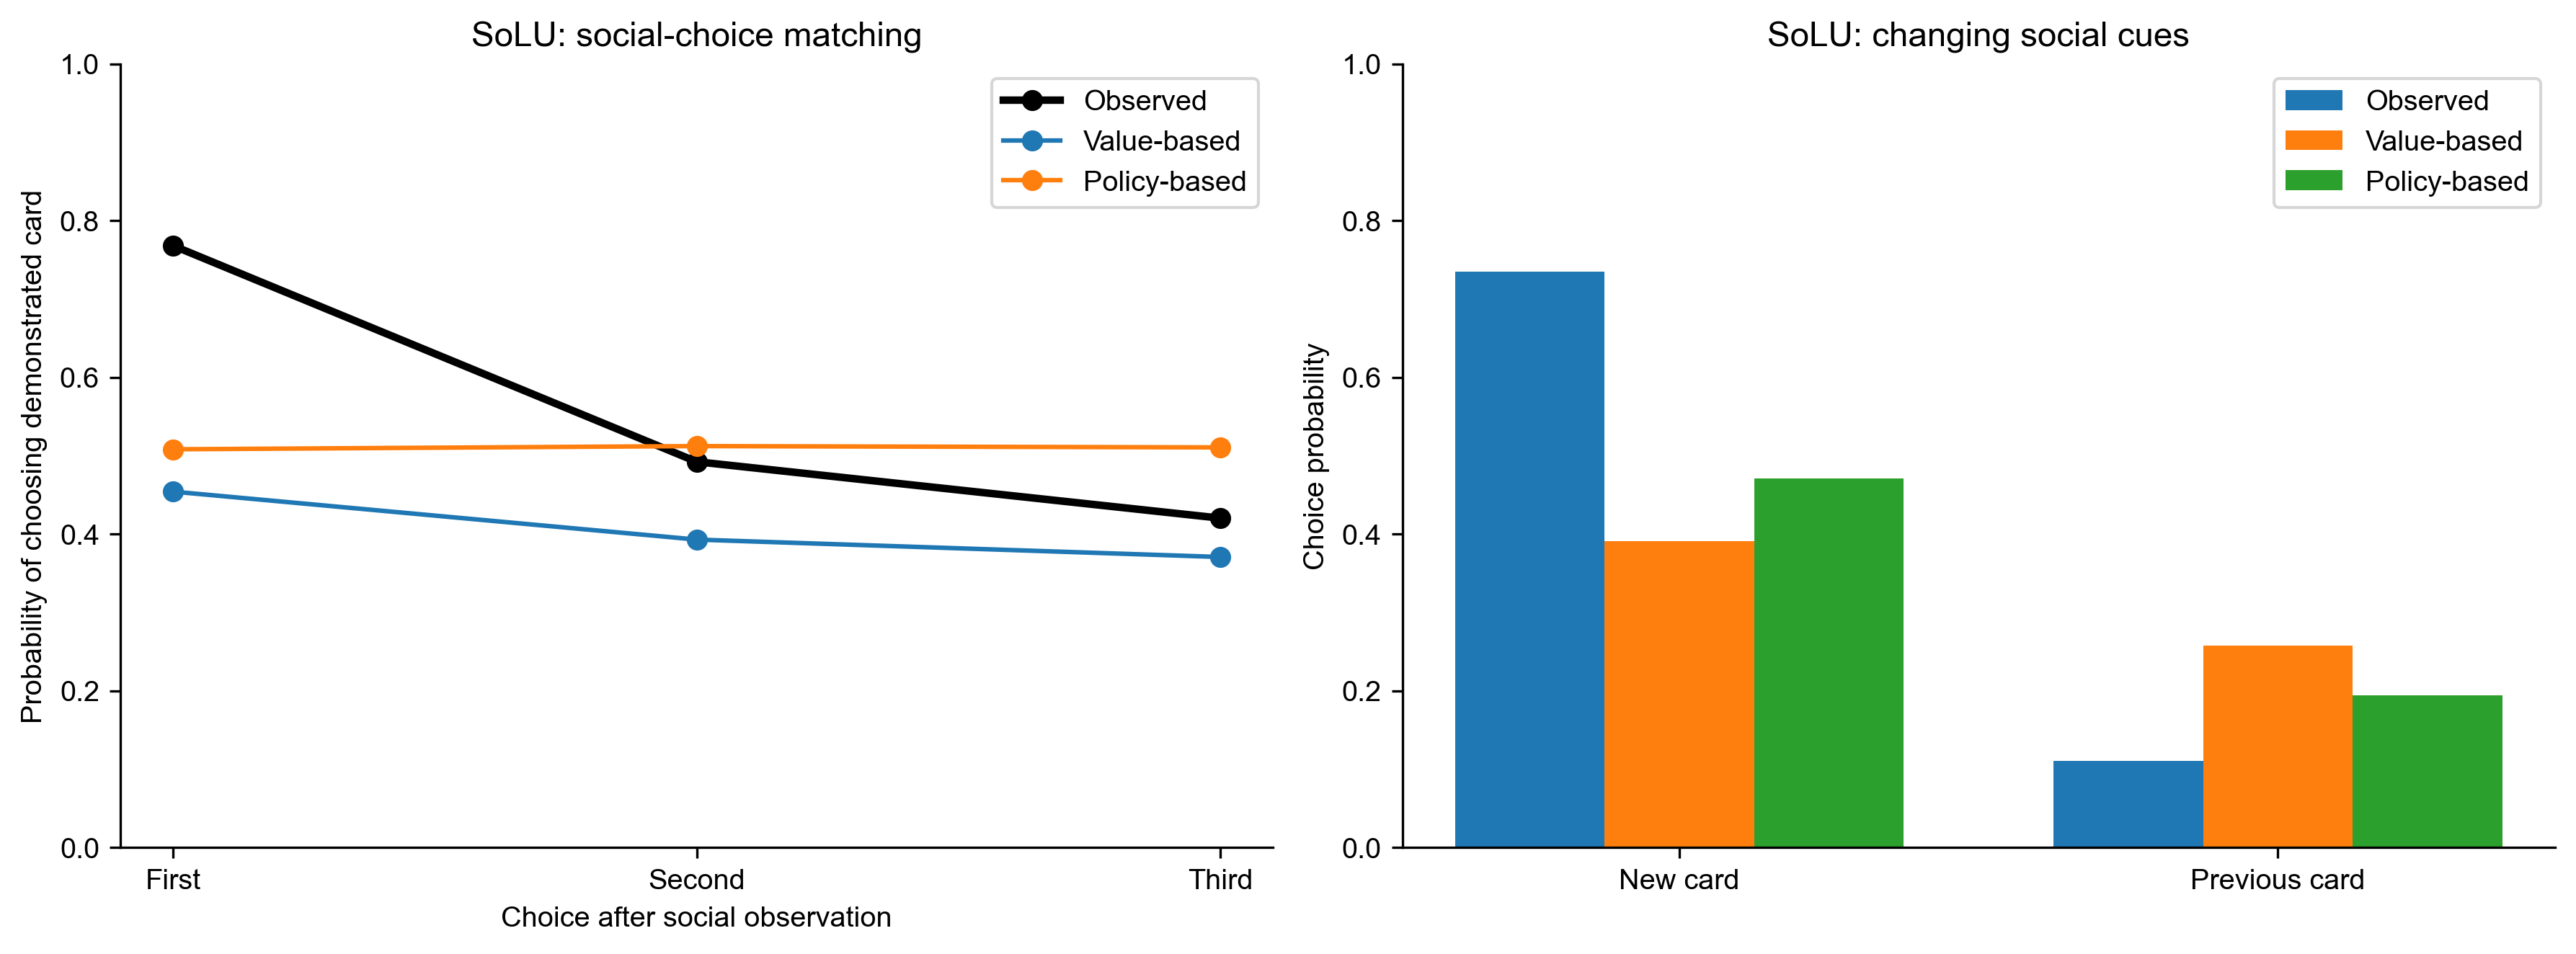

,Group,Model,Measure,Observed,Predicted,Absolute_discrepancy
0,SoLI,Value-based,First choice matching,0.859,0.569,0.291
1,SoLI,Value-based,Second choice matching,0.639,0.491,0.148
2,SoLI,Value-based,Third choice matching,0.598,0.435,0.163
3,SoLI,Value-based,Choose newly demonstrated card,0.836,0.486,0.350
4,SoLI,Value-based,Choose previously demonstrated card,0.079,0.252,0.173
5,SoLI,Policy-based,First choice matching,0.859,0.647,0.212
6,SoLI,Policy-based,Second choice matching,0.639,0.657,0.018
7,SoLI,Policy-based,Third choice matching,0.598,0.655,0.057
8,SoLI,Policy-based,Choose newly demonstrated card,0.836,0.595,0.240
9,SoLI,Policy-based,Choose previously demonstrated card,0.079,0.186,0.107


One-step predictive analysis completed.


In [67]:
# ONE-STEP-AHEAD PREDICTIVE CHECK — CELL 2/2

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


def one_step_social_summary(subjects, prediction):

    lag_obs = np.full((len(subjects), 3), np.nan)
    lag_pred = np.full((len(subjects), 3), np.nan)

    switch_obs = np.full((len(subjects), 2), np.nan)
    switch_pred = np.full((len(subjects), 2), np.nan)

    for row, subject in enumerate(subjects):

        events = np.arange(45, 105, 3)
        cards = PPC_OBS_SINGLE[subject, events]

        valid = cards >= 0

        events = events[valid]
        cards = cards[valid]

        # Matching at the first, second and third choices.
        if len(events):

            for lag in range(3):

                choices = PPC_REAL_ACTIONS[
                    subject, events + lag
                ]

                lag_obs[row, lag] = np.mean(
                    choices == cards
                )

                lag_pred[row, lag] = np.mean(
                    prediction[
                        subject,
                        events + lag,
                        cards
                    ]
                )

        # Response when the newly observed card differs
        # from the previously observed card.
        e = np.arange(48, 105, 3)

        new_cards = PPC_OBS_SINGLE[subject, e]
        old_cards = PPC_OBS_SINGLE[subject, e - 3]

        use = (
            (new_cards >= 0)
            & (old_cards >= 0)
            & (new_cards != old_cards)
        )

        e = e[use]
        new_cards = new_cards[use]
        old_cards = old_cards[use]

        if len(e):

            chosen = PPC_REAL_ACTIONS[subject, e]

            switch_obs[row, 0] = np.mean(
                chosen == new_cards
            )

            switch_obs[row, 1] = np.mean(
                chosen == old_cards
            )

            switch_pred[row, 0] = np.mean(
                prediction[subject, e, new_cards]
            )

            switch_pred[row, 1] = np.mean(
                prediction[subject, e, old_cards]
            )

    def average(array):
        return np.array([
            np.nanmean(array[:, j])
            for j in range(array.shape[1])
        ])

    return {
        'observed_lag': average(lag_obs),
        'predicted_lag': average(lag_pred),
        'observed_switch': average(switch_obs),
        'predicted_switch': average(switch_pred)
    }


PPC_ONESTEP_RESULTS = {}
rows = []

for group, ids in PPC_GROUPS.items():

    for model in PPC_MODELS:

        result = one_step_social_summary(
            np.asarray(ids),
            PPC_ONESTEP[model]
        )

        PPC_ONESTEP_RESULTS[(group, model)] = result

        measures = [
            ('lag', [
                'First choice matching',
                'Second choice matching',
                'Third choice matching'
            ]),
            ('switch', [
                'Choose newly demonstrated card',
                'Choose previously demonstrated card'
            ])
        ]

        for key, labels in measures:

            for j, label in enumerate(labels):

                rows.append({
                    'Group': group,
                    'Model': model,
                    'Measure': label,
                    'Observed': result[f'observed_{key}'][j],
                    'Predicted': result[f'predicted_{key}'][j]
                })

    # Visualize both models against real behavior.
    fig, axes = plt.subplots(
        1, 2,
        figsize=(12, 4.5)
    )

    value = PPC_ONESTEP_RESULTS[
        (group, 'Value-based')
    ]

    policy = PPC_ONESTEP_RESULTS[
        (group, 'Policy-based')
    ]

    x = np.arange(3)

    axes[0].plot(
        x, value['observed_lag'],
        'ko-', lw=2.5, label='Observed'
    )

    axes[0].plot(
        x, value['predicted_lag'],
        'o-', label='Value-based'
    )

    axes[0].plot(
        x, policy['predicted_lag'],
        'o-', label='Policy-based'
    )

    axes[0].set_xticks(
        x,
        ['First', 'Second', 'Third']
    )

    axes[0].set_xlabel(
        'Choice after social observation'
    )

    axes[0].set_ylabel(
        'Probability of choosing demonstrated card'
    )

    axes[0].set_title(
        f'{group}: social-choice matching'
    )

    axes[0].set_ylim(0, 1)
    axes[0].legend()

    # New versus previously demonstrated card.
    x = np.arange(2)
    width = 0.25

    axes[1].bar(
        x - width,
        value['observed_switch'],
        width,
        label='Observed'
    )

    axes[1].bar(
        x,
        value['predicted_switch'],
        width,
        label='Value-based'
    )

    axes[1].bar(
        x + width,
        policy['predicted_switch'],
        width,
        label='Policy-based'
    )

    axes[1].set_xticks(
        x,
        ['New card', 'Previous card']
    )

    axes[1].set_ylabel('Choice probability')

    axes[1].set_title(
        f'{group}: changing social cues'
    )

    axes[1].set_ylim(0, 1)
    axes[1].legend()

    fig.tight_layout()

    fig.savefig(
        PPC_OUTDIR / f'{group}_one_step_predictive_check.png',
        dpi=250,
        bbox_inches='tight'
    )

    plt.show()


PPC_ONESTEP_SUMMARY = pd.DataFrame(rows)

PPC_ONESTEP_SUMMARY[
    'Absolute_discrepancy'
] = abs(
    PPC_ONESTEP_SUMMARY['Observed']
    - PPC_ONESTEP_SUMMARY['Predicted']
)

PPC_ONESTEP_SUMMARY.to_csv(
    PPC_OUTDIR / 'PPC_one_step_predictive_check.csv',
    index=False
)

display(PPC_ONESTEP_SUMMARY.round(3))

print('One-step predictive analysis completed.')

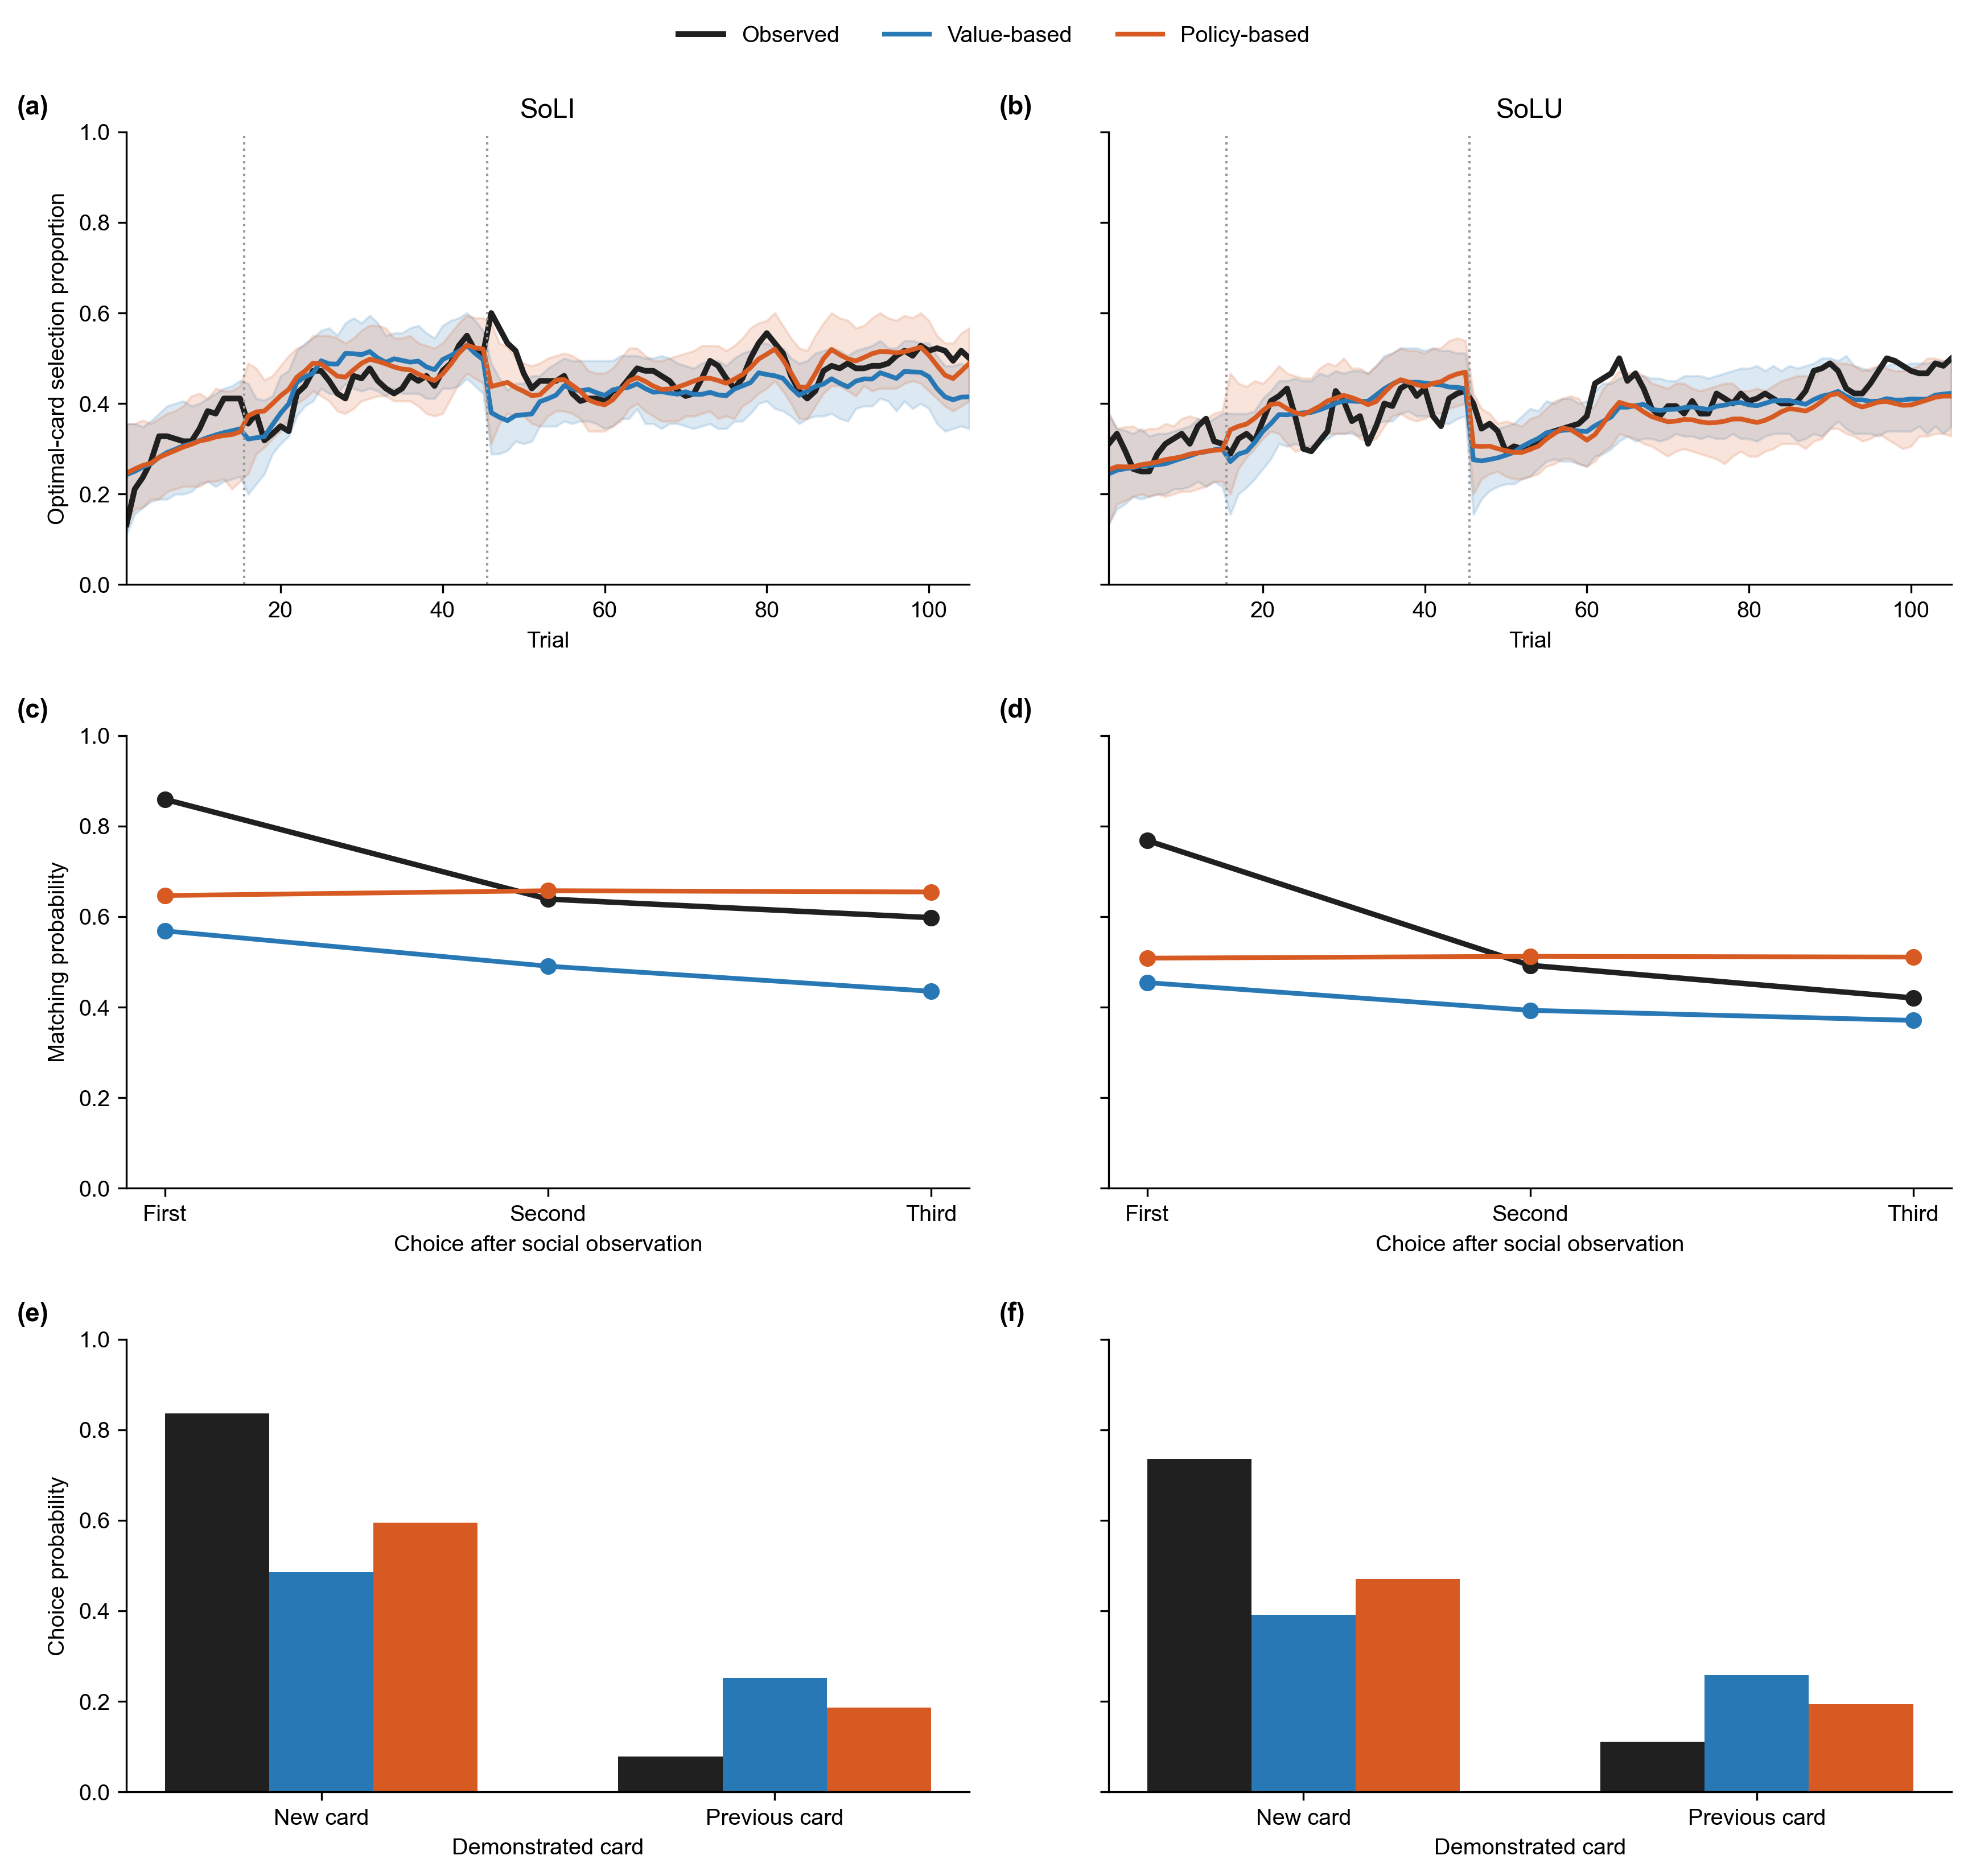

Supplementary Figure 1 saved.


In [81]:

# Run after all behavioral predictive-check cells.

import numpy as np
import matplotlib.pyplot as plt
colors = {
    "SoLI": "firebrick",
    "SoLU": "royalblue"
}
required = [
    "PPC_OBSERVED",
    "PPC_RESULTS",
    "PPC_ONESTEP_RESULTS",
    "ppc_smooth_blocks",
]

missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError("Run the previous PPC cells first: " + str(missing))

colors = {
    "Observed": "#202020",
    "Value-based": "#2878B5",
    "Policy-based": "#D65A21",
}

fig, axes = plt.subplots(
    3, 2, figsize=(11.5, 11), sharey="row"
)

for col, group in enumerate(("SoLI", "SoLU")):

    # ---------------------------------
    # ROW 1: Optimal-card trajectories
    # ---------------------------------
    ax = axes[0, col]
    x = np.arange(1, 106)

    observed = ppc_smooth_blocks(
        PPC_OBSERVED[group]["optimal_by_trial"],
        PPC_WINDOW
    )

    ax.plot(
        x, observed,
        color=colors["Observed"],
        linewidth=2.4,
        label="Observed"
    )

    for model in ("Value-based", "Policy-based"):
        sims = ppc_smooth_blocks(
            PPC_RESULTS[(group, model)]["optimal_by_trial"],
            PPC_WINDOW
        )

        mean = sims.mean(axis=0)
        low, high = np.quantile(
            sims, [0.025, 0.975], axis=0
        )

        ax.plot(
            x, mean,
            color=colors[model],
            linewidth=2,
            label=model
        )

        ax.fill_between(
            x, low, high,
            color=colors[model],
            alpha=0.16
        )

    for boundary in (15.5, 45.5):
        ax.axvline(
            boundary, linestyle=":",
            color="0.6", linewidth=1
        )

    ax.set(
        xlim=(1, 105),
        ylim=(0, 1),
        title=group,
        xlabel="Trial"
    )

    if col == 0:
        ax.set_ylabel("Optimal-card selection proportion")

    # ---------------------------------
    # ROW 2: Social-choice matching
    # One-step-ahead predictions
    # ---------------------------------
    ax = axes[1, col]
    lag_x = np.arange(3)

    observed = PPC_ONESTEP_RESULTS[
        (group, "Value-based")
    ]["observed_lag"]

    ax.plot(
        lag_x, observed,
        "o-",
        color=colors["Observed"],
        linewidth=2.3
    )

    for model in ("Value-based", "Policy-based"):
        predicted = PPC_ONESTEP_RESULTS[
            (group, model)
        ]["predicted_lag"]

        ax.plot(
            lag_x, predicted,
            "o-",
            color=colors[model],
            linewidth=2
        )

    ax.set(
        xticks=lag_x,
        xticklabels=["First", "Second", "Third"],
        ylim=(0, 1),
        xlabel="Choice after social observation"
    )

    if col == 0:
        ax.set_ylabel("Matching probability")

    # ---------------------------------
    # ROW 3: Changing social cues
    # One-step-ahead predictions
    # ---------------------------------
    ax = axes[2, col]
    bars_x = np.arange(2)
    width = 0.23

    observed = PPC_ONESTEP_RESULTS[
        (group, "Value-based")
    ]["observed_switch"]

    ax.bar(
        bars_x - width,
        observed,
        width,
        color=colors["Observed"]
    )

    for k, model in enumerate(
        ("Value-based", "Policy-based")
    ):
        predicted = PPC_ONESTEP_RESULTS[
            (group, model)
        ]["predicted_switch"]

        ax.bar(
            bars_x + k * width,
            predicted,
            width,
            color=colors[model]
        )

    ax.set(
        xticks=bars_x,
        xticklabels=["New card", "Previous card"],
        ylim=(0, 1),
        xlabel="Demonstrated card"
    )

    if col == 0:
        ax.set_ylabel("Choice probability")

# Panel lettering: a-f
for letter, ax in zip("abcdef", axes.flat):
    ax.text(
        -0.13, 1.04,
        f"({letter})",
        transform=ax.transAxes,
        fontweight="bold",
        fontsize=11
    )
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# One shared legend for the entire figure
handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles, labels,
    loc="upper center",
    ncol=3,
    frameon=False,
    bbox_to_anchor=(0.5, 1.0)
)

fig.tight_layout(
    rect=[0, 0, 1, 0.965],
    h_pad=2.1,
    w_pad=2.2
)

fig.savefig(
    PPC_OUTDIR / "Supplementary_Fig_1_Model_Predictions.pdf",
    bbox_inches="tight"
)

fig.savefig(
    PPC_OUTDIR / "Supplementary_Fig_1_Model_Predictions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Supplementary Figure 1 saved.")
fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/main/paper draft/Figures/Supplementary_Fig_1.svg')

## Validation of Social-Influence Parameters

In [70]:

# Prepare agent-specific parameters and behavioral measures

import ast
import numpy as np
import pandas as pd

from pathlib import Path
from scipy.special import softmax
from IPython.display import display

GI_ROLES = ("Best", "Second-best", "Random")
GI_GROUPS = ("SoLI", "SoLU")

# Require at least 3 observations of an agent
# for the individual-level correlation analysis.
GI_MIN_OBS = 3

GI_SEED = 2026
GI_N_PERM = 20000
GI_N_BOOT = 5000

GI_OUT = Path("Gamma_Validation_Reviewer2")
GI_OUT.mkdir(parents=True, exist_ok=True)

# ====================================
# LOAD EXISTING FITTED PARAMETERS
# ====================================

assert "all_sub_df" in globals()
assert len(all_sub_df) == 90

if "PPC_PARAMS" in globals():

    GI_THETA = np.asarray(
        PPC_PARAMS["Policy-based"],
        dtype=float
    )

else:

    GI_THETA = np.column_stack([
        all_tv_alpha_ind_Qmean,
        all_tv_beta_ind_Qmean,
        all_tv_alpha_Qmean,
        all_tv_beta_Qmean,
        np.asarray(all_tv_gamma_Qmean, dtype=float)
    ])

assert GI_THETA.shape == (90, 7)
assert np.isfinite(GI_THETA).all()

# ====================================
# CONSTRUCT PARTICIPANT-LEVEL DATA
# ====================================

GI_RECORDS = []

for subject, frame in enumerate(all_sub_df):

    assert len(frame) >= 105

    # The 'agent types' array maps displayed
    # A/B/C identities to the actual strategy:
    # 0 = Best, 1 = Second-best, 2 = Random.

    role_at_display = np.asarray(
        ast.literal_eval(
            str(frame["agent types"].iloc[45])
        ),
        dtype=int
    )

    assert set(role_at_display.tolist()) == {0, 1, 2}

    assert np.array_equal(
        role_at_display,
        np.asarray(
            ast.literal_eval(
                str(frame["agent types"].iloc[15])
            ),
            dtype=int
        )
    ), (
        f"Agent assignments changed between blocks "
        f"for participant {subject}"
    )

    theta = GI_THETA[subject]

    alpha_ind, beta_ind, alpha_social, beta_social = (
        theta[:4]
    )

    gamma_display = theta[4:7]

    # Convert agent identity order A/B/C
    # to expertise order Best/Second-best/Random.
    gamma_by_role = gamma_display[
        np.argsort(role_at_display)
    ]

    # Reconstruct privately learned Q-values
    # using actual choices and rewards.
    #
    # This allows us to estimate how likely
    # participants would be to select the
    # demonstrated card without a direct
    # social bias at the current decision.

    Q = np.zeros(4, dtype=float)

    trials_by_role = {
        role: [] for role in range(3)
    }

    for t in range(105):

        if t in (15, 45):
            Q[:] = Q.mean()

        # Block 3: first choice immediately
        # following a social observation.
        if t >= 45 and (t - 45) % 3 == 0:

            label = str(
                frame["chosen_agent"].iloc[t]
            ).strip()

            if label in ("A", "B", "C"):

                displayed_agent = "ABC".index(label)
                role = int(
                    role_at_display[displayed_agent]
                )

                demonstrated_card = int(
                    frame["agent_choices"].iloc[t]
                )

                assert 0 <= demonstrated_card < 4

                private_probability = float(
                    softmax(beta_social * Q)[
                        demonstrated_card
                    ]
                )

                participant_choice = int(
                    frame["choice"].iloc[t]
                )

                matched = float(
                    participant_choice == demonstrated_card
                )

                trials_by_role[role].append(
                    (matched, private_probability)
                )

            else:

                assert str(
                    frame["agent_choices"].iloc[t]
                ).strip() in ("-", "nan")

        # Update Q-values using actual private feedback.
        action = int(frame["choice"].iloc[t])

        reward = float(
            frame["outcome"].iloc[t] == "win"
        )

        alpha = (
            alpha_ind if t < 15
            else alpha_social
        )

        Q[action] += alpha * (
            reward - Q[action]
        )

    # ====================================
    # SAVE EACH AGENT-TYPE MEASUREMENT
    # ====================================

    for role, role_name in enumerate(GI_ROLES):

        observations = np.asarray(
            trials_by_role[role],
            dtype=float
        ).reshape(-1, 2)

        n = len(observations)

        imitation = (
            np.mean(observations[:, 0])
            if n else np.nan
        )

        private_matching = (
            np.mean(observations[:, 1])
            if n else np.nan
        )

        GI_RECORDS.append({

            "Participant": subject,

            "Group": (
                "SoLI" if subject < 45
                else "SoLU"
            ),

            "Agent_type": role_name,

            "Gamma": float(gamma_by_role[role]),

            # The actual logit-scale contribution
            # of gamma also depends on beta.
            "Beta_gamma": float(
                beta_social * gamma_by_role[role]
            ),

            "N_observed": n,

            "Immediate_matching": imitation,

            "Private_baseline_matching": private_matching,

            "Excess_matching": (
                imitation - private_matching
                if n else np.nan
            )
        })


GI_DF = pd.DataFrame(GI_RECORDS)

assert len(GI_DF) == 270

assert GI_DF.groupby(
    "Participant"
)["Agent_type"].nunique().eq(3).all()

GI_DF.to_csv(
    GI_OUT / "participant_by_agent_gamma.csv",
    index=False
)

print(
    "PASS: Gamma parameters aligned by agent "
    "expertise for all 90 participants."
)

print("\nAgent observation counts:")

display(
    GI_DF.groupby(
        ["Group", "Agent_type"]
    )["N_observed"].agg(
        N_with_3plus=lambda x: int(
            (x >= GI_MIN_OBS).sum()
        ),
        Median_observations="median",
        Total_observations="sum"
    ).round(2)
)

PASS: Gamma parameters aligned by agent expertise for all 90 participants.

Agent observation counts:


N_with_3plus  Median_observations  Total_observations
Group Agent_type                                                        
SoLI  Best                   33                  8.0                 358
      Random                 25                  3.0                 222
      Second-best            28                  4.0                 232
SoLU  Best                   31                  4.0                 267
      Random                 19                  2.0                 158
      Second-best            28                  6.0                 283

In [72]:

# Group differences and individual behavioral validity

from scipy.stats import rankdata

GI_RNG = np.random.default_rng(GI_SEED)


def gi_holm(p_values):
    """Holm multiple-comparison correction."""

    p_values = np.asarray(p_values, dtype=float)

    order = np.argsort(p_values)

    adjusted_sorted = np.maximum.accumulate(
        (len(p_values) - np.arange(len(p_values)))
        * p_values[order]
    )

    adjusted = np.empty(len(p_values))

    adjusted[order] = np.clip(
        adjusted_sorted, 0, 1
    )

    return adjusted


def gi_two_group_permutation(a, b):
    """
    Two-sided test of the difference in group means.

    Also returns a participant-bootstrap 95% CI.
    """

    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)

    observed = a.mean() - b.mean()

    combined = np.concatenate([a, b])
    n_a = len(a)

    null = np.empty(GI_N_PERM)

    for j in range(GI_N_PERM):

        shuffled = GI_RNG.permutation(combined)

        null[j] = (
            shuffled[:n_a].mean()
            - shuffled[n_a:].mean()
        )

    p_value = (
        1 + np.sum(np.abs(null) >= abs(observed))
    ) / (GI_N_PERM + 1)

    bootstrap = np.empty(GI_N_BOOT)

    for j in range(GI_N_BOOT):

        a_sample = GI_RNG.choice(
            a, len(a), replace=True
        )

        b_sample = GI_RNG.choice(
            b, len(b), replace=True
        )

        bootstrap[j] = (
            a_sample.mean() - b_sample.mean()
        )

    ci_lower, ci_upper = np.quantile(
        bootstrap, [0.025, 0.975]
    )

    return observed, p_value, ci_lower, ci_upper


# =====================================
# PART A: GROUP-LEVEL DIFFERENCES
# =====================================

wide = GI_DF.pivot(
    index="Participant",
    columns="Agent_type",
    values="Gamma"
)

# Agent selectivity contrasts
wide["Best_minus_Random"] = (
    wide["Best"] - wide["Random"]
)

wide["Best_minus_Second"] = (
    wide["Best"] - wide["Second-best"]
)

GROUP_VARIABLES = [
    "Best",
    "Second-best",
    "Random",
    "Best_minus_Random",
    "Best_minus_Second"
]

group_rows = []

for measure in GROUP_VARIABLES:

    soli = wide.loc[
        range(45), measure
    ].to_numpy()

    solu = wide.loc[
        range(45, 90), measure
    ].to_numpy()

    difference, p, ci_lo, ci_hi = (
        gi_two_group_permutation(soli, solu)
    )

    group_rows.append({

        "Measure": measure,
        "SoLI_mean": soli.mean(),
        "SoLU_mean": solu.mean(),

        "Difference_SoLI_minus_SoLU": difference,

        "CI95_lower": ci_lo,
        "CI95_upper": ci_hi,

        "p_permutation": p
    })


GI_GROUP_TESTS = pd.DataFrame(group_rows)

GI_GROUP_TESTS["p_Holm"] = gi_holm(
    GI_GROUP_TESTS["p_permutation"]
)

GI_GROUP_TESTS.to_csv(
    GI_OUT / "gamma_group_tests.csv",
    index=False
)

print("\nGROUP-LEVEL GAMMA COMPARISONS")

display(
    GI_GROUP_TESTS.round(4)
)


# =====================================
# PART B: INDIVIDUAL-LEVEL VALIDITY
# =====================================

def gi_stratified_spearman(
    data,
    parameter,
    outcome
):
    """
    Spearman correlation with a permutation test
    that shuffles gamma values WITHIN each group.

    This preserves the group structure and avoids
    treating participants from different groups
    as completely exchangeable.
    """

    d = data[
        [parameter, outcome, "Group"]
    ].dropna().reset_index(drop=True)

    n = len(d)

    if (
        n < 8
        or d[parameter].nunique() < 3
        or d[outcome].nunique() < 3
    ):
        return np.nan, np.nan, n

    x = d[parameter].to_numpy(dtype=float)
    y = d[outcome].to_numpy(dtype=float)

    group_labels = d["Group"].to_numpy()

    # Spearman = Pearson correlation of ranks.
    x_rank = rankdata(x)
    y_rank = rankdata(y)

    x_centered = x_rank - x_rank.mean()
    y_centered = y_rank - y_rank.mean()

    denominator = (
        np.linalg.norm(x_centered)
        * np.linalg.norm(y_centered)
    )

    observed_rho = float(
        x_centered @ y_centered / denominator
    )

    group_indices = [
        np.flatnonzero(group_labels == group)
        for group in GI_GROUPS
    ]

    null = np.empty(GI_N_PERM)

    for j in range(GI_N_PERM):

        shuffled = x_centered.copy()

        for idx in group_indices:

            shuffled[idx] = GI_RNG.permutation(
                x_centered[idx]
            )

        null[j] = (
            shuffled @ y_centered
        ) / denominator

    p_value = (
        1 + np.sum(
            np.abs(null) >= abs(observed_rho)
        )
    ) / (GI_N_PERM + 1)

    return observed_rho, p_value, n


individual_rows = []

for role in GI_ROLES:

    # Avoid unstable imitation rates from participants
    # who rarely selected the corresponding agent.
    d = GI_DF[
        (GI_DF["Agent_type"] == role)
        & (GI_DF["N_observed"] >= GI_MIN_OBS)
    ]

    for outcome in (
        "Excess_matching",
        "Immediate_matching"
    ):

        rho, p, n = gi_stratified_spearman(
            d,
            parameter="Gamma",
            outcome=outcome
        )

        individual_rows.append({

            "Agent_type": role,
            "Outcome": outcome,

            "N_participants": n,

            "Spearman_rho": rho,
            "p_permutation": p
        })


GI_INDIVIDUAL_TESTS = pd.DataFrame(
    individual_rows
)

# Correct the three agent-type tests within
# each behavioral outcome family.

for outcome in (
    "Excess_matching",
    "Immediate_matching"
):

    mask = (
        GI_INDIVIDUAL_TESTS["Outcome"] == outcome
    )

    GI_INDIVIDUAL_TESTS.loc[
        mask, "p_Holm"
    ] = gi_holm(
        GI_INDIVIDUAL_TESTS.loc[
            mask, "p_permutation"
        ]
    )


GI_INDIVIDUAL_TESTS.to_csv(
    GI_OUT / "gamma_individual_tests.csv",
    index=False
)

print("\nINDIVIDUAL-LEVEL GAMMA VALIDATION")

display(
    GI_INDIVIDUAL_TESTS.round(4)
)


GROUP-LEVEL GAMMA COMPARISONS


,Measure,SoLI_mean,SoLU_mean,Difference_SoLI_minus_SoLU,CI95_lower,CI95_upper,p_permutation,p_Holm
0,Best,0.3728,0.2408,0.1320,-0.0017,0.2706,0.0628,0.3140
1,Second-best,0.2773,0.2638,0.0135,-0.1375,0.1649,0.8645,1.0000
2,Random,0.3176,0.2015,0.1161,-0.0200,0.2506,0.1041,0.4166
3,Best_minus_Random,0.0552,0.0393,0.0159,-0.1318,0.1673,0.8371,1.0000
4,Best_minus_Second,0.0955,-0.0231,0.1185,-0.0266,0.2598,0.1073,0.4166



INDIVIDUAL-LEVEL GAMMA VALIDATION


,Agent_type,Outcome,N_participants,Spearman_rho,p_permutation,p_Holm
0,Best,Excess_matching,64,0.3236,0.0092,0.0185
1,Best,Immediate_matching,64,0.1740,0.1543,0.1543
2,Second-best,Excess_matching,56,0.4946,0.0001,0.0004
3,Second-best,Immediate_matching,56,0.4368,0.0009,0.0028
4,Random,Excess_matching,44,0.3838,0.0107,0.0185
5,Random,Immediate_matching,44,0.4162,0.0052,0.0104


SoLI color: #b22222
SoLU color: #4169e1


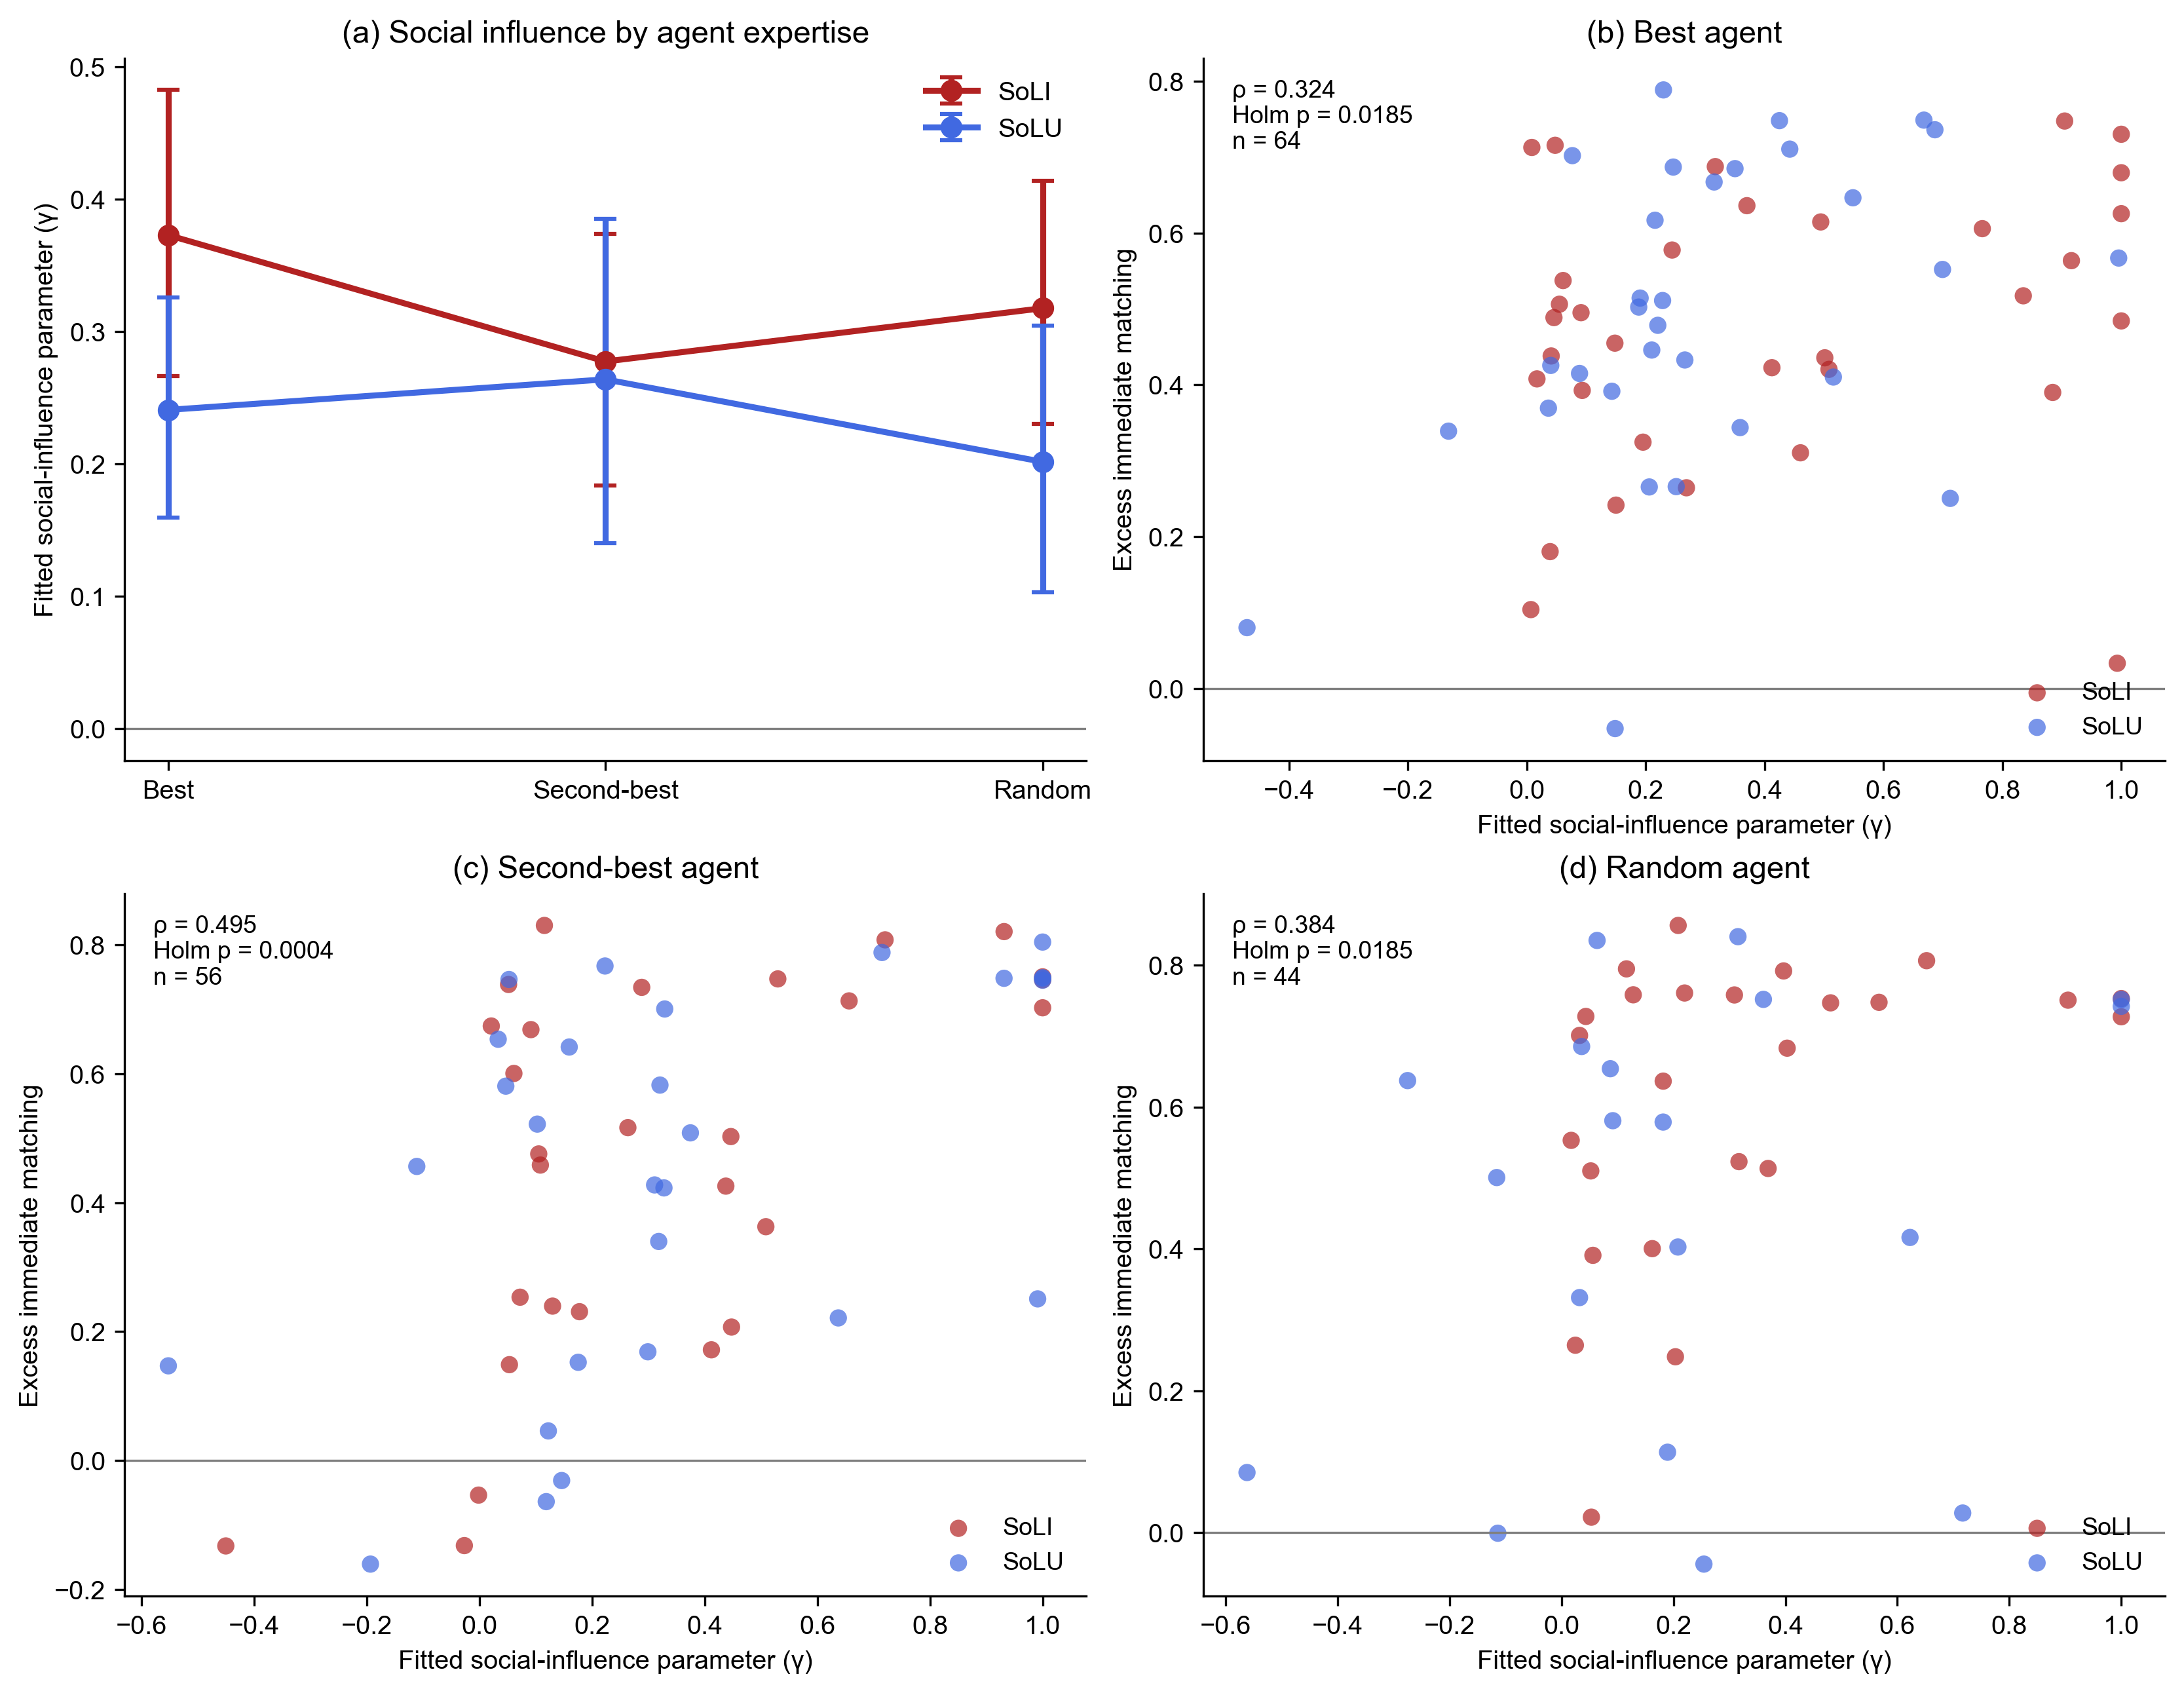


Figure generated successfully.
SoLI = firebrick (#B22222)
SoLU = royalblue (#4169E1)
PDF saved: D:\University\University of Tehran\MSc\Thesis\paper draft\main\paper draft\paper\New version\Submission\Code\Gamma_Validation_Reviewer2\Supplementary_Fig_2_Firebrick_Royalblue.pdf
PNG saved: D:\University\University of Tehran\MSc\Thesis\paper draft\main\paper draft\paper\New version\Submission\Code\Gamma_Validation_Reviewer2\Supplementary_Fig_2_Firebrick_Royalblue.png


In [79]:

# ============================================================
# SUPPLEMENTARY FIGURE 2
# Gamma group profiles and individual behavioral correspondence
#
# SoLI: FIREBRICK
# SoLU: ROYALBLUE
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex
from pathlib import Path

GI_OUT = Path("Gamma_Validation_Reviewer2")
GI_OUT.mkdir(parents=True, exist_ok=True)

# Load previous results if necessary
if "GI_DF" not in globals():
    GI_DF = pd.read_csv(
        GI_OUT / "participant_by_agent_gamma.csv"
    )

if "GI_INDIVIDUAL_TESTS" not in globals():
    GI_INDIVIDUAL_TESTS = pd.read_csv(
        GI_OUT / "gamma_individual_tests.csv"
    )

# ============================================================
# COLORS - EXPLICITLY DEFINED
# ============================================================

COLORS = {
    "SoLI": "firebrick",
    "SoLU": "royalblue"
}

print("SoLI color:", to_hex(COLORS["SoLI"]))
print("SoLU color:", to_hex(COLORS["SoLU"]))

# Firebrick = #B22222
# Royalblue = #4169E1

roles = ["Best", "Second-best", "Random"]
groups = ["SoLI", "SoLU"]

rng = np.random.default_rng(2026)

# Create a completely new figure
fig, axes = plt.subplots(
    2, 2,
    figsize=(11, 8.5),
    constrained_layout=True
)

# ============================================================
# PANEL A: GROUP-LEVEL GAMMA VALUES WITH BOOTSTRAP CIs
# ============================================================

ax = axes[0, 0]

for group in groups:

    means = []
    lows = []
    highs = []

    for role in roles:

        values = GI_DF.loc[
            (GI_DF["Group"] == group)
            & (GI_DF["Agent_type"] == role),
            "Gamma"
        ].to_numpy(dtype=float)

        mean = values.mean()

        bootstrap = rng.choice(
            values,
            size=(5000, len(values)),
            replace=True
        ).mean(axis=1)

        lo, hi = np.quantile(
            bootstrap,
            [0.025, 0.975]
        )

        means.append(mean)
        lows.append(mean - lo)
        highs.append(hi - mean)

    ax.errorbar(
        np.arange(3),
        means,
        yerr=np.array([lows, highs]),

        fmt="o-",
        linewidth=2.2,
        markersize=7,
        capsize=4,
        capthick=1.5,

        # Force group colors
        color=COLORS[group],
        ecolor=COLORS[group],
        markerfacecolor=COLORS[group],
        markeredgecolor=COLORS[group],

        label=group
    )

ax.set_xticks(
    np.arange(3),
    roles
)

ax.set_ylabel(
    "Fitted social-influence parameter (γ)"
)

ax.set_title(
    "(a) Social influence by agent expertise"
)

ax.axhline(
    0,
    color="gray",
    linewidth=0.8
)

ax.legend(
    frameon=False,
    loc="best"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)


# ============================================================
# PANELS B-D: INDIVIDUAL-LEVEL GAMMA VALIDATION
# ============================================================

for k, role in enumerate(roles):

    ax = axes.flat[k + 1]

    subset = GI_DF.loc[
        (GI_DF["Agent_type"] == role)
        & (GI_DF["N_observed"] >= 3)
    ]

    # Plot SoLI and SoLU separately
    for group in groups:

        group_data = subset.loc[
            subset["Group"] == group
        ]

        ax.scatter(
            group_data["Gamma"],
            group_data["Excess_matching"],

            s=40,
            alpha=0.7,

            # Force requested colors
            color=COLORS[group],
            facecolors=COLORS[group],

            edgecolors="none",
            label=group
        )

    # Get previous statistical results
    stats = GI_INDIVIDUAL_TESTS.loc[
        (
            GI_INDIVIDUAL_TESTS["Agent_type"]
            == role
        )
        & (
            GI_INDIVIDUAL_TESTS["Outcome"]
            == "Excess_matching"
        )
    ].iloc[0]

    rho = stats["Spearman_rho"]
    p = stats["p_Holm"]
    n = int(stats["N_participants"])

    # Display statistics inside each panel
    ax.text(
        0.03, 0.97,
        f"ρ = {rho:.3f}\n"
        f"Holm p = {p:.4f}\n"
        f"n = {n}",

        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=9,
        color="black",

        bbox=dict(
            facecolor="white",
            edgecolor="none",
            alpha=0.8
        )
    )

    ax.set_title(
        f"({chr(98 + k)}) {role} agent"
    )

    ax.set_xlabel(
        "Fitted social-influence parameter (γ)"
    )

    ax.set_ylabel(
        "Excess immediate matching"
    )

    ax.axhline(
        0,
        color="gray",
        linewidth=0.8
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.legend(
        frameon=False,
        fontsize=9,
        loc="lower right"
    )

# ============================================================
# SAVE FIGURE
# ============================================================

# New filenames distinguish this version from the old one.
pdf_path = (
    GI_OUT
    / "Supplementary_Fig_2_Firebrick_Royalblue.pdf"
)

png_path = (
    GI_OUT
    / "Supplementary_Fig_2_Firebrick_Royalblue.png"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)
fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/main/paper draft/Figures/Supplementary_Fig_2.svg')
plt.show()

print("\nFigure generated successfully.")
print("SoLI = firebrick (#B22222)")
print("SoLU = royalblue (#4169E1)")
print("PDF saved:", pdf_path.resolve())
print("PNG saved:", png_path.resolve())
